# TP2 Machine Learning
## Les réseaux de neurones

- **Realisé Par : Houda HAJJAJ et Abdelfatah CHAIB**
- **M2 EUR Smart IoT** 

### Objectif du TP

Ce TP a pour objectif d'étudier le fonctionnement des réseaux de neurones à travers l'implémentation d'un perceptron simple, son apprentissage et la réalisation d'un perceptron multicouche.

Le TP est réalisé progressivement selon les parties du sujet :

1. **Développement d'un perceptron simple :** définition du modèle et test sur la fonction logique OU.
2. **Apprentissage du perceptron :** implémentation de l'algorithme de Widrow-Hoff et expérimentation sur deux jeux de données.
3. **Perceptron multicouche :** propagation des entrées dans le réseau, apprentissage des poids et analyse des résultats.

## 1. Développement d'un perceptron simple

### 1.1. Mise en place d'un perceptron simple

Dans cette première partie, nous allons implémenter un perceptron simple, un modèle de base utilisé pour la classification binaire.

Le perceptron reçoit un vecteur d'entrée, associe un poids à chaque entrée et ajoute un biais. Il calcule ensuite une somme pondérée, puis applique une fonction d'activation pour obtenir sa sortie.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

#### Sauvegarde automatique des figures (optionnel)

La cellule suivante enregistre chaque figure affichée par `plt.show()` dans le dossier `figures/`, au format PDF (vectoriel) et PNG, pour pouvoir les réutiliser dans le rapport. Pour désactiver cette sauvegarde, il suffit de mettre `SAUVEGARDER_FIGURES = False`.

In [2]:
import os

SAUVEGARDER_FIGURES = True        # mettre False pour désactiver la sauvegarde
DOSSIER_FIGURES = "figures"

# Le test évite d'appliquer deux fois la surcharge si la cellule est ré-exécutée
if SAUVEGARDER_FIGURES and not getattr(plt.show, "_sauvegarde_active", False):
    os.makedirs(DOSSIER_FIGURES, exist_ok=True)
    _compteur_figures = {"n": 0}
    _plt_show_original = plt.show

    def _show_et_sauvegarde(*args, **kwargs):
        for num in plt.get_fignums():
            _compteur_figures["n"] += 1
            fig = plt.figure(num)
            base = f"{DOSSIER_FIGURES}/fig_{_compteur_figures['n']:03d}"
            fig.savefig(base + ".pdf", bbox_inches="tight")
            fig.savefig(base + ".png", bbox_inches="tight", dpi=200)
            print(f"  [sauvegardé] {base}.pdf / .png")
        return _plt_show_original(*args, **kwargs)

    _show_et_sauvegarde._sauvegarde_active = True
    plt.show = _show_et_sauvegarde

### Principe mathématique

Pour deux entrées \(x_1\) et \(x_2\), le perceptron utilise trois paramètres : le biais \(w_0\) et les poids \(w_1\) et \(w_2\).

La somme pondérée est :

$
z = w_0 + w_1x_1 + w_2x_2
$

Pour intégrer le biais au calcul, on ajoute une composante égale à 1 au vecteur d'entrée :
$
x_{\mathrm{aug}} = [1, x_1, x_2]
$
Le calcul devient alors un produit scalaire :

$
z = w \cdot x_{\mathrm{aug}}
$

La sortie du perceptron est obtenue en appliquant la fonction d'activation à \(z\).

In [3]:
def perceptron_simple(x, w, active):
    # Ajouter le biais à l'entrée
    x_aug = np.insert(x, 0, 1)

    # Calculer la somme pondérée
    z = np.dot(w, x_aug)

    # Fonction d'activation
    if active == 0:
        y = np.sign(z)
    elif active == 1:
        y = np.tanh(z)
    else:
        raise ValueError("active doit être 0 (sign) ou 1 (tanh).")

    return y

### Vérification de l'implémentation

Avant d'utiliser le perceptron sur un problème de classification, nous allons vérifier son fonctionnement sur quelques entrées simples.
Cette vérification permet de contrôler l'ajout du biais, le calcul de la somme pondérée et le comportement des deux fonctions d'activation.

In [4]:
# Exemple de paramètres
x = np.array([1, 2])
w = np.array([-0.5, 1, 1])

# Test avec la fonction sign
y_sign = perceptron_simple(x, w, active=0)

# Test avec la fonction tanh
y_tanh = perceptron_simple(x, w, active=1)

print("Entrée :", x)
print("Poids :", w)
print("Sortie avec sign :", y_sign)
print("Sortie avec tanh :", y_tanh)

Entrée : [1 2]
Poids : [-0.5  1.   1. ]
Sortie avec sign : 1.0
Sortie avec tanh : 0.9866142981514303


**Remarque : `sign` ou `tanh` ?**

- `sign` donne une sortie binaire ($-1$ ou $+1$) : elle sert à **prédire la classe** (inférence).
- `tanh` donne une sortie continue dans $]-1, 1[$ et sa dérivée existe partout : $\tanh'(z) = 1 - \tanh^2(z)$. C'est ce qui permet de l'utiliser dans une règle d'apprentissage par gradient, comme celle de la section 2.6.

### 1.2. Test du perceptron sur la fonction logique OU

Dans cette étape, nous allons tester le perceptron simple sur la fonction logique OU (*OR*).

La fonction OU renvoie 1 lorsqu'au moins une des deux entrées vaut 1, et 0 uniquement lorsque les deux entrées valent 0. Nous allons définir les quatre combinaisons possibles, calculer les sorties du perceptron et comparer les prédictions aux sorties attendues.

In [5]:
def afficher_resultats(X, Y, w):

    # Affichage des points de chaque classe
    plt.scatter(
        X[Y == -1, 0], X[Y == -1, 1],
        color="red", label="Classe -1"
    )

    plt.scatter(
        X[Y == 1, 0], X[Y == 1, 1],
        color="green", label="Classe +1"
    )

    # Tracer la droite séparatrice : z = a*x + b
    t = [-0.5, 1.5]

    a = -w[1] / w[2]  # Pente de la droite
    b = -w[0] / w[2]  # Ordonnée à l'origine
    z = [a * t[0] + b, a * t[1] + b]

    # Tracé de la droite de séparation
    plt.plot(t, z, color="blue", label="Droite séparatrice")

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title("Perceptron simple - Fonction OU logique")
    plt.legend()
    plt.grid(True)
    plt.show()

Test du perceptron sur l'exemple du OU logique.
Entrée : [0 0] - Sortie prédite : -1.0 - Sortie attendue : -1
Entrée : [0 1] - Sortie prédite : 1.0 - Sortie attendue : 1
Entrée : [1 0] - Sortie prédite : 1.0 - Sortie attendue : 1
Entrée : [1 1] - Sortie prédite : 1.0 - Sortie attendue : 1
  [sauvegardé] figures/fig_001.pdf / .png


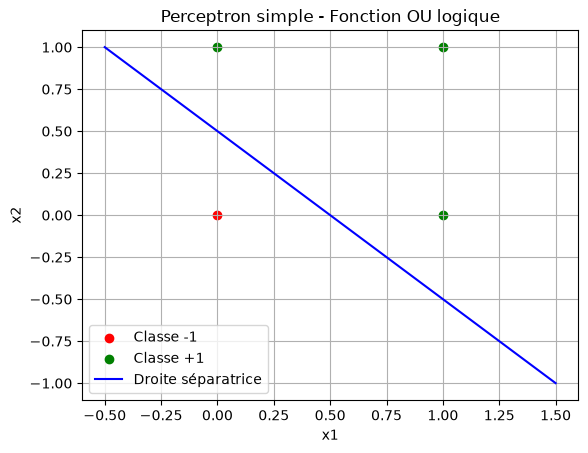

In [6]:
def test_perceptron_ou_logique():

    # Définition des données du OU logique
    X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
    Y = np.array([-1, 1, 1, 1])  # Sorties attendues avec sign

    # Définition des poids du perceptron : biais + w1 + w2
    w = np.array([-0.5, 1, 1])

    print("Test du perceptron sur l'exemple du OU logique.")

    for i in range(len(X)):
        y_pred = perceptron_simple(X[i], w, active=0)

        print(
            f"Entrée : {X[i]} - "
            f"Sortie prédite : {y_pred} - "
            f"Sortie attendue : {Y[i]}"
        )

    afficher_resultats(X, Y, w)


# Test du OU logique
test_perceptron_ou_logique()

### Analyse du test sur le OU logique

**Choix des poids $w = (-0.5,\ 1,\ 1)$.** Le neurone doit s'activer ($z > 0$) dès qu'au moins une entrée vaut 1 :

| Entrée $(x_1, x_2)$ | $z = -0.5 + x_1 + x_2$ | Sortie `sign` |
|---|---|---|
| (0, 0) | −0,5 | −1 |
| (0, 1) | 0,5 | +1 |
| (1, 0) | 0,5 | +1 |
| (1, 1) | 1,5 | +1 |

**Droite séparatrice.** Elle correspond à $z = 0$, soit $x_2 = -\dfrac{w_0 + w_1 x_1}{w_2} = 0{,}5 - x_1$. Elle isole bien le point $(0,0)$ des trois autres.

**Limite du perceptron simple.** Il ne peut pas résoudre le XOR (OU exclusif), car ses classes ne sont pas linéairement séparables. C'est ce qui motive le perceptron multicouche (section 3, test XOR).

## 2. Implémentation de l'algorithme de Widrow-Hoff

Dans cette étape, nous allons implémenter l'algorithme de Widrow-Hoff afin d'apprendre automatiquement les poids du perceptron à partir des données.

Les poids sont initialisés aléatoirement. À chaque époque, les données sont parcourues par batches, les prédictions sont calculées et les poids sont mis à jour en fonction de l'erreur. L'apprentissage s'arrête lorsque l'erreur cumulée devient nulle ou lorsque le nombre maximal d'époques est atteint.

In [7]:
def apprentissage_widrow(x, yd, epoch, batch_size):
    # Nombre d'exemples d'apprentissage
    n_samples = x.shape[1]

    # Initialisation aléatoire des poids : biais, poids de x1 et poids de x2
    w = np.random.rand(3)

    # Liste pour enregistrer l'erreur à chaque époque
    erreur = []

    # Ajout de la ligne de biais
    x_bias = np.vstack((np.ones((1, n_samples)), x))

    # Apprentissage sur plusieurs époques
    for ep in range(epoch):
        erreur_epoch = 0

        # Traitement des données par batches
        for i in range(0, n_samples, batch_size):

            # Sélection du batch
            x_batch = x_bias[:, i:i + batch_size]
            yd_batch = yd[i:i + batch_size]

            # Prédiction du perceptron
            y_pred = np.sign(w @ x_batch)

            # Éviter une sortie nulle
            y_pred[y_pred == 0] = 1

            # Erreur entre les sorties désirées et prédites
            erreur_batch = yd_batch - y_pred

            # Mise à jour des poids
            w += (1 / batch_size) * np.dot(x_batch, erreur_batch)

            # Accumulation de l'erreur quadratique
            erreur_epoch += np.sum(erreur_batch ** 2)

        # Affichage des classes et de la frontière de décision
        affiche_classe(
            w, x, yd,
            f"Epoch {ep + 1} (erreur : {erreur_epoch})"
        )

        # Enregistrement de l'erreur
        erreur.append(erreur_epoch)

        # Arrêt si l'erreur est nulle
        if erreur_epoch == 0:
            break

    return w, erreur

### 2.2. Visualisation des résultats

La fonction `affiche_classe` représente les exemples des deux classes dans un plan. Elle trace également la frontière de décision définie par les poids du perceptron.

La frontière correspond à l'équation :

$
w_0+w_1x_1+w_2x_2=0
$

Cette représentation permet de vérifier visuellement si la séparation des classes est cohérente avec les données.

In [8]:
def affiche_classe(w, x, yd, titre):
    plt.figure(figsize=(7, 5))

    # Affichage des points d'apprentissage
    for i in range(x.shape[1]):
        if yd[i] == 1:
            plt.scatter(
                x[0, i], x[1, i],
                color="green", marker="o"
            )
        else:
            plt.scatter(
                x[0, i], x[1, i],
                color="red", marker="x"
            )

    # Tracé de la frontière de décision
    if w is not None and w[2] != 0:
        t = np.linspace(x[0, :].min(), x[0, :].max(), 100)

        a = -w[1] / w[2]
        b = -w[0] / w[2]

        z = a * t + b

        plt.plot(t, z, color="blue", label="Frontière de décision")
        plt.legend()
    else:
        print("Impossible de tracer la droite : division par zéro.")

    plt.title(titre)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.grid(True)
    plt.show()

### 2.3. Test 1 : apprentissage sur `p2_d1.txt`

Dans ce premier test, nous chargeons le jeu de données `p2 d1.txt`, appliquons l'algorithme de Widrow-Hoff et observons l'évolution de l'erreur ainsi que la frontière de décision obtenue.

In [9]:
# Charger les données : 2 lignes (x1 et x2), un exemple par colonne
data1 = np.loadtxt("p2_d1.txt")
x1 = data1

# Sorties désirées : 25 points de classe -1, puis 25 points de classe +1
yd1 = np.concatenate((-np.ones(25), np.ones(25)))

print("Dimensions des entrées :", x1.shape)
print("Dimensions des sorties :", yd1.shape)
print("Classes présentes :", np.unique(yd1))

Dimensions des entrées : (2, 50)
Dimensions des sorties : (50,)
Classes présentes : [-1.  1.]


#### Visualisation des deux jeux de données avant apprentissage

Avant d'entraîner le perceptron, nous représentons les deux jeux de données sous forme de nuages de points (25 points de la classe $-1$, puis 25 de la classe $+1$). On voit déjà si une droite peut séparer les classes : c'est le cas de `p2_d1.txt`, mais pas de `p2_d2.txt` dont les classes se recouvrent.

  [sauvegardé] figures/fig_002.pdf / .png


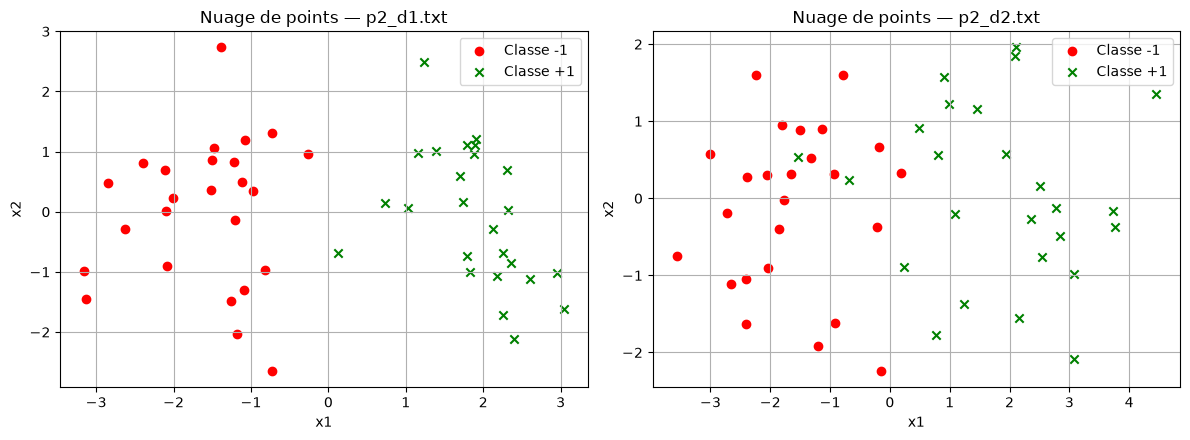

In [10]:
# Aperçu des deux jeux de données (un point par exemple, une couleur par classe)
x2_apercu = np.loadtxt("p2_d2.txt")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, (donnees, nom_fichier) in zip(axes, [(x1, "p2_d1.txt"), (x2_apercu, "p2_d2.txt")]):
    ax.scatter(donnees[0, :25], donnees[1, :25],
               c="red", marker="o", label="Classe -1")
    ax.scatter(donnees[0, 25:], donnees[1, 25:],
               c="green", marker="x", label="Classe +1")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title(f"Nuage de points — {nom_fichier}")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

  [sauvegardé] figures/fig_003.pdf / .png


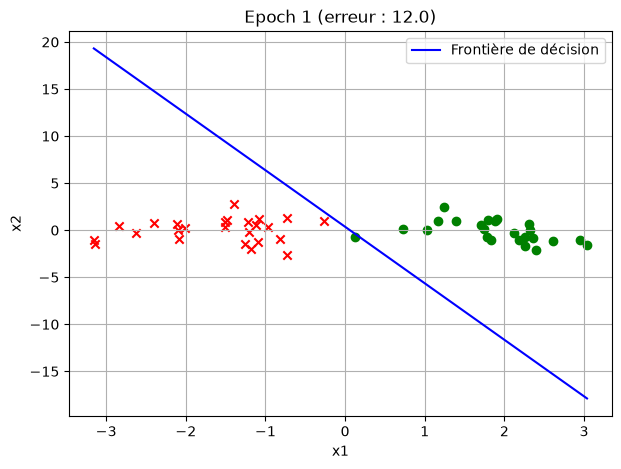

  [sauvegardé] figures/fig_004.pdf / .png


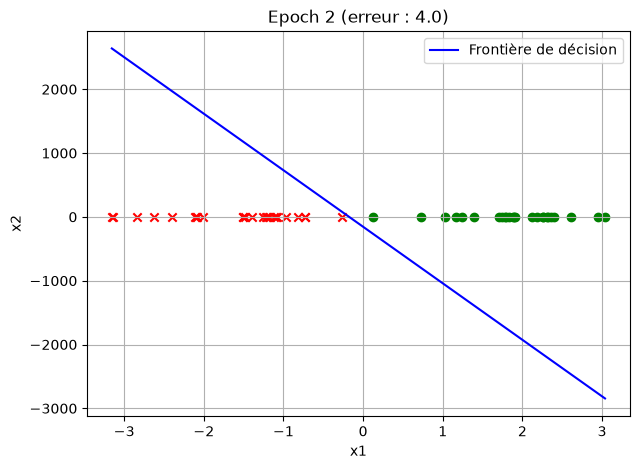

  [sauvegardé] figures/fig_005.pdf / .png


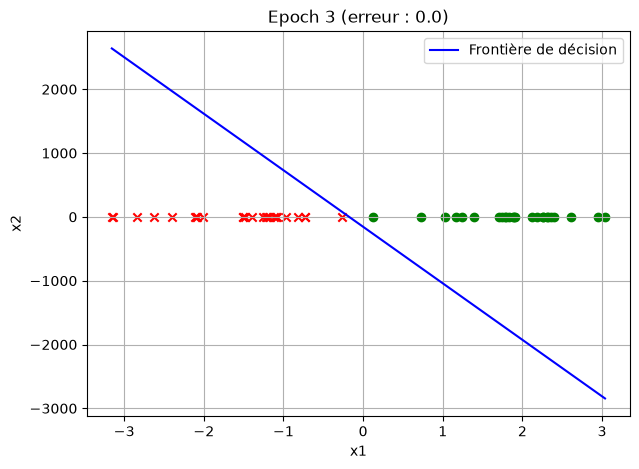

Poids appris : [0.37454012 2.13856515 0.00241446]
Dernière erreur : 0.0
  [sauvegardé] figures/fig_006.pdf / .png


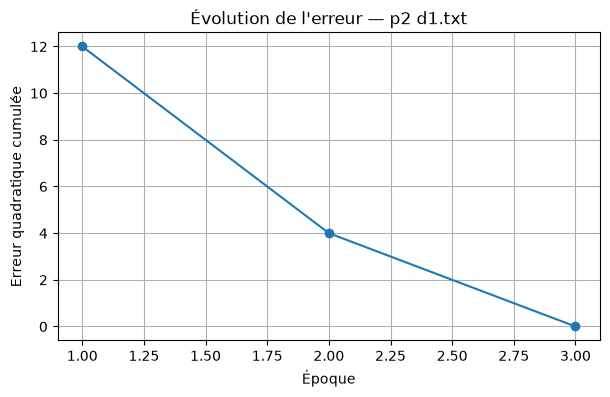

In [11]:
np.random.seed(42)

w1, erreur1 = apprentissage_widrow(
    x1, yd1,
    epoch=5,
    batch_size=4
)

print("Poids appris :", w1)
print("Dernière erreur :", erreur1[-1])

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(erreur1) + 1), erreur1, marker="o")
plt.xlabel("Époque")
plt.ylabel("Erreur quadratique cumulée")
plt.title("Évolution de l'erreur — p2 d1.txt")
plt.grid(True)
plt.show()

### 2.4. Test 2 : apprentissage sur `p2_d2.txt`

Nous répétons la même démarche avec le deuxième jeu de données. Nous comparerons les erreurs et les frontières de décision afin d'évaluer la capacité du perceptron à séparer les classes dans chaque cas.

  [sauvegardé] figures/fig_007.pdf / .png


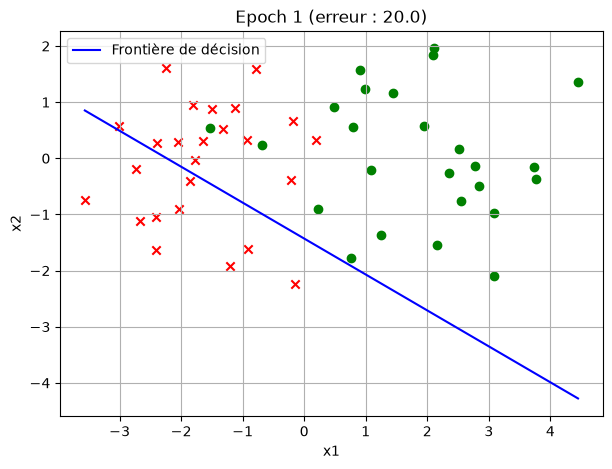

  [sauvegardé] figures/fig_008.pdf / .png


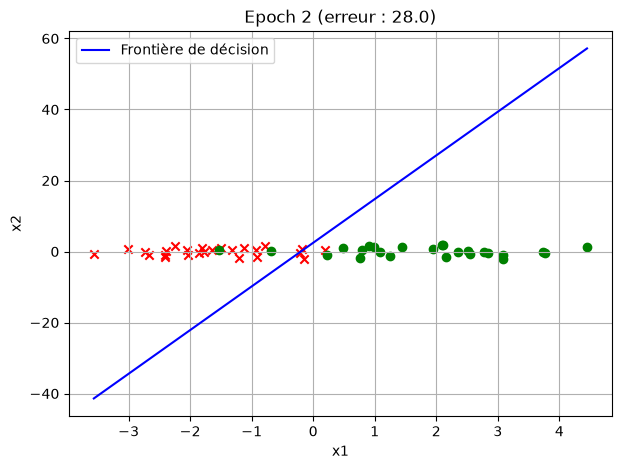

  [sauvegardé] figures/fig_009.pdf / .png


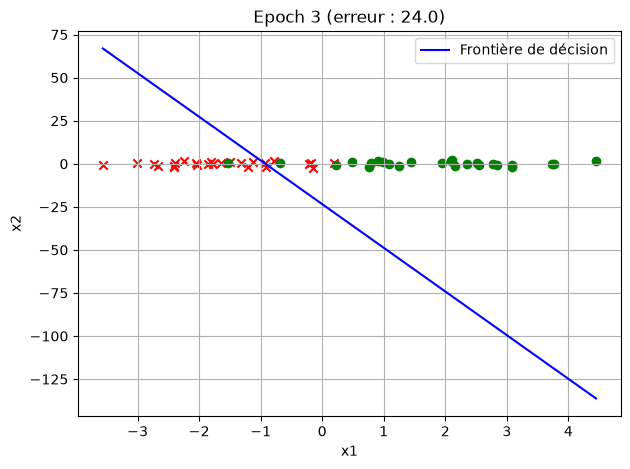

  [sauvegardé] figures/fig_010.pdf / .png


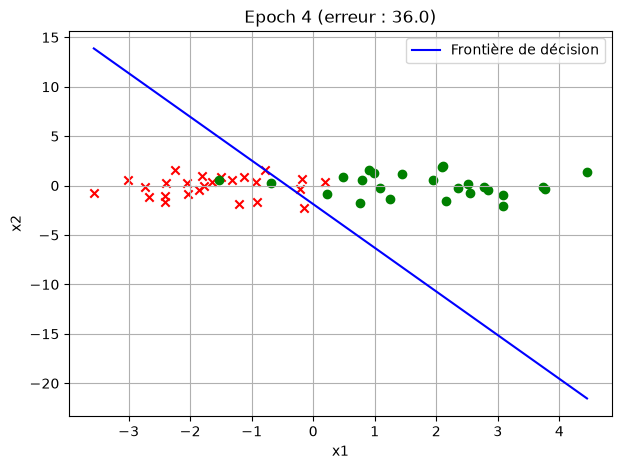

  [sauvegardé] figures/fig_011.pdf / .png


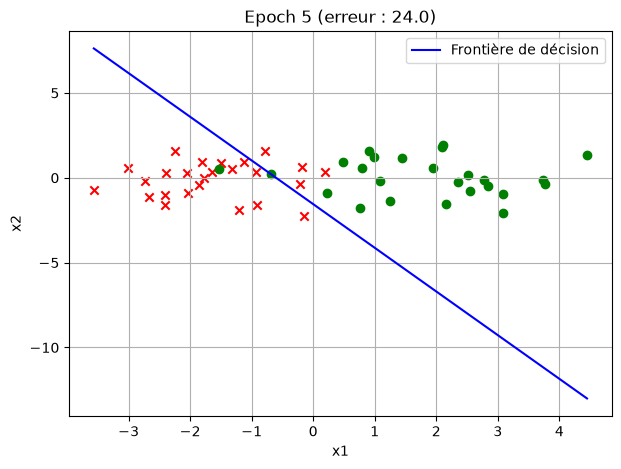

Poids appris : [0.87454012 1.45032181 0.56351862]
Dernière erreur : 24.0
  [sauvegardé] figures/fig_012.pdf / .png


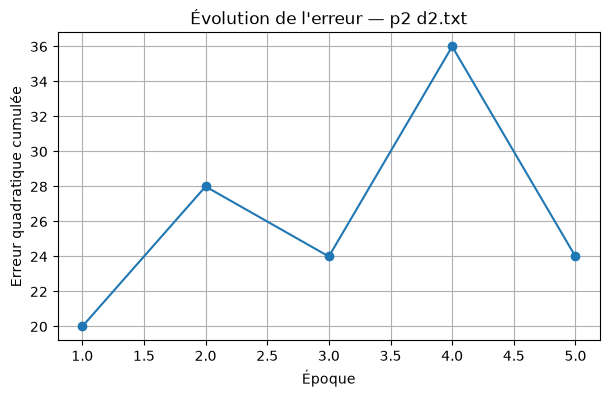

In [12]:
# Charger les données : 2 lignes (x1 et x2), un exemple par colonne
data2 = np.loadtxt("p2_d2.txt")
x2 = data2

# Sorties désirées : 25 points de classe -1, puis 25 points de classe +1
yd2 = np.concatenate((-np.ones(25), np.ones(25)))

np.random.seed(42)

w2, erreur2 = apprentissage_widrow(
    x2, yd2,
    epoch=5,
    batch_size=4
)

print("Poids appris :", w2)
print("Dernière erreur :", erreur2[-1])

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(erreur2) + 1), erreur2, marker="o")
plt.xlabel("Époque")
plt.ylabel("Erreur quadratique cumulée")
plt.title("Évolution de l'erreur — p2 d2.txt")
plt.grid(True)
plt.show()

#### Frontières de décision finales sur les deux jeux de données

Nous superposons aux nuages de points la droite $w_0+w_1x_1+w_2x_2=0$ obtenue après les cinq époques (poids `w1` du test 1 et `w2` du test 2), et nous comptons les points mal classés. Cette figure résume visuellement la comparaison de la section 2.5.

  [sauvegardé] figures/fig_013.pdf / .png


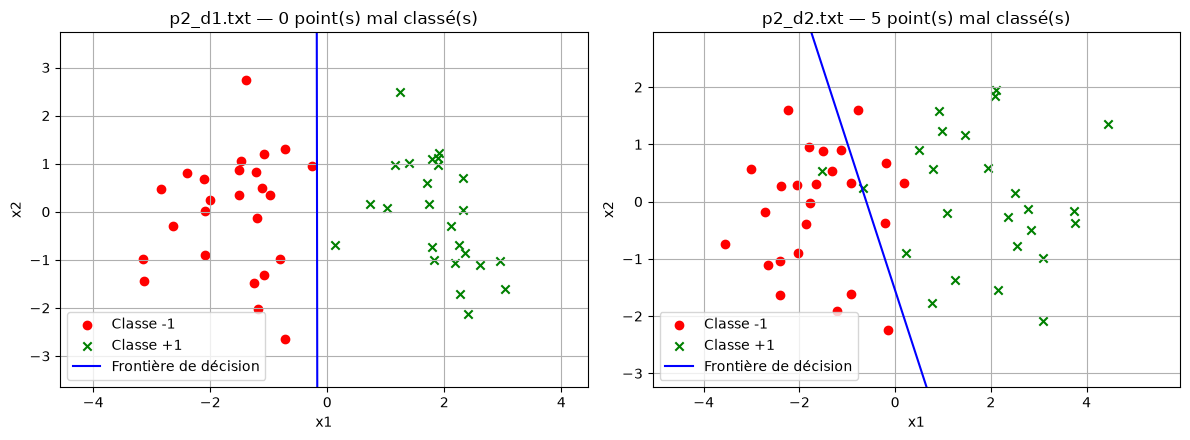

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

cas = [
    (x1, yd1, w1, "p2_d1.txt"),
    (x2, yd2, w2, "p2_d2.txt"),
]

for ax, (x_cas, yd_cas, w_cas, nom_fichier) in zip(axes, cas):
    ax.scatter(x_cas[0, yd_cas == -1], x_cas[1, yd_cas == -1],
               c="red", marker="o", label="Classe -1")
    ax.scatter(x_cas[0, yd_cas == 1], x_cas[1, yd_cas == 1],
               c="green", marker="x", label="Classe +1")

    # Frontière de décision : x2 = -(w0 + w1*x1) / w2
    if w_cas[2] != 0:
        t = np.linspace(x_cas[0].min() - 1, x_cas[0].max() + 1, 100)
        ax.plot(t, -(w_cas[0] + w_cas[1] * t) / w_cas[2],
                "b-", label="Frontière de décision")
    ax.set_ylim(x_cas[1].min() - 1, x_cas[1].max() + 1)

    # Nombre de points mal classés avec la règle du perceptron (sortie >= 0 -> +1)
    x_aug_cas = np.vstack((np.ones(x_cas.shape[1]), x_cas))
    y_pred_cas = np.where(w_cas @ x_aug_cas >= 0, 1, -1)
    n_mal_cas = int(np.sum(y_pred_cas != yd_cas))

    ax.set_title(f"{nom_fichier} — {n_mal_cas} point(s) mal classé(s)")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

### 2.5. Comparaison des deux jeux de données

Après cinq époques d'apprentissage, nous comparons l'erreur finale obtenue sur chaque jeu de données (cellule ci-dessous).

Sur un jeu **linéairement séparable**, l'erreur peut atteindre 0 : l'algorithme converge et la droite sépare parfaitement les deux classes. Sur un jeu **non séparable**, l'erreur reste non nulle quel que soit le nombre d'époques, car aucune droite ne peut classer tous les points correctement. Cette comparaison est approfondie à la section 2.6 (modes online et batch, 200 époques, nombre de points mal classés).

Erreur finale p2_d1.txt : 0.00
Erreur finale p2_d2.txt : 24.00
Convergence (erreur nulle) sur p2_d1 : True
Convergence (erreur nulle) sur p2_d2 : False
  [sauvegardé] figures/fig_014.pdf / .png


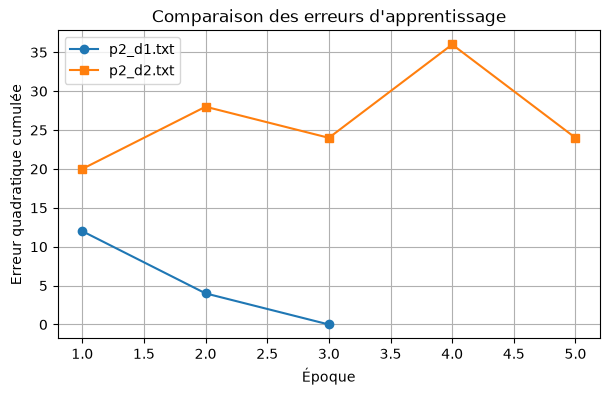

In [14]:
# Comparaison des erreurs finales et des courbes d'apprentissage
print(f"Erreur finale p2_d1.txt : {erreur1[-1]:.2f}")
print(f"Erreur finale p2_d2.txt : {erreur2[-1]:.2f}")
print("Convergence (erreur nulle) sur p2_d1 :", erreur1[-1] == 0)
print("Convergence (erreur nulle) sur p2_d2 :", erreur2[-1] == 0)

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(erreur1) + 1), erreur1, marker="o", label="p2_d1.txt")
plt.plot(range(1, len(erreur2) + 1), erreur2, marker="s", label="p2_d2.txt")
plt.xlabel("Époque")
plt.ylabel("Erreur quadratique cumulée")
plt.title("Comparaison des erreurs d'apprentissage")
plt.legend()
plt.grid(True)
plt.show()

### 2.6. Variante de Widrow-Hoff avec activation $\tanh$ : apprentissage online et par lots

L'implémentation précédente met à jour les poids à partir de la sortie `sign`. Nous ajoutons ici une variante où la sortie du neurone est continue, $y = \tanh(z)$, et où les poids sont corrigés proportionnellement à l'erreur, pondérée par la pente locale de $\tanh$ :

$$
\Delta w = \alpha \,(y_d - y)\,(1 - y^2)\,\tilde{x}
$$

Le terme $(1 - y^2)$ est la dérivée de $\tanh$.

- **Online** (`batch_size = 1`) : mise à jour après chaque exemple.
- **Par lots** (`batch_size = N`) : une seule mise à jour par époque, à partir du gradient cumulé sur le lot.

**Critère d'arrêt.** L'apprentissage s'arrête lorsque tous les exemples sont bien classés avec `sign` (zéro point mal classé), ou après `epoch` époques. On évalue avec `sign` et non avec `tanh`, car `tanh` ne vaut jamais exactement $\pm 1$. L'erreur quadratique sert à suivre la convergence.

Cette fonction porte un nom distinct (`apprentissage_widrow_tanh`) pour ne pas remplacer celle de la section 2.

In [15]:
def apprentissage_widrow_tanh(x, yd, epoch, batch_size, alpha=0.1, verbose=True):
    """
    Apprentissage par descente de gradient (règle de Widrow-Hoff, activation tanh).

    x          : matrice 2 x N (un exemple par colonne)
    yd         : vecteur de taille N (+1 ou -1)
    epoch      : nombre maximal d'époques
    batch_size : taille des lots
    alpha      : taux d'apprentissage
    """
    n_samples = x.shape[1]

    # Poids initiaux aléatoires dans [-0.5, 0.5] : [w0 (biais), w1, w2]
    w = np.random.uniform(-0.5, 0.5, size=3)

    # Ajout de la ligne de biais -> 3 x N
    x_biais = np.vstack([np.ones(n_samples), x])

    erreurs = []

    for ep in range(epoch):
        erreur_epoch = 0

        for start in range(0, n_samples, batch_size):
            end = start + batch_size
            x_batch = x_biais[:, start:end]
            yd_batch = yd[start:end]

            # Propagation
            v = np.dot(w, x_batch)
            y = np.tanh(v)

            # Erreur quadratique du batch
            erreur_epoch += np.sum((yd_batch - y) ** 2)

            # Delta = (yd - y) * (1 - y^2)
            delta = (yd_batch - y) * (1 - y ** 2)
            w += alpha * np.dot(x_batch, delta)

        erreurs.append(erreur_epoch)

        # Nombre de points mal classés (évaluation avec sign)
        n_mal = np.sum(np.sign(np.dot(w, x_biais)) != yd)

        if verbose:
            print(f"Époque {ep + 1:3d} | erreur = {erreur_epoch:8.4f} | mal classés = {n_mal}")

        if n_mal == 0:
            if verbose:
                print("Convergence atteinte !")
            break

    return w, np.array(erreurs)


def charger_donnees(nom_fichier):
    X = np.loadtxt(nom_fichier)                       # 2 x 50
    yd = np.concatenate((-np.ones(25), np.ones(25)))  # 25 points de classe -1, puis 25 de classe +1
    return X, yd


def tracer_resultats(X, yd, w, titre=""):
    plt.figure(figsize=(7, 5))
    plt.scatter(X[0, yd == -1], X[1, yd == -1], c="red", marker="o", label="classe -1")
    plt.scatter(X[0, yd == 1], X[1, yd == 1], c="green", marker="x", label="classe +1")

    # Droite séparatrice : x2 = -(w0 + w1*x1) / w2
    t = np.linspace(X[0].min() - 1, X[0].max() + 1, 100)
    plt.plot(t, -(w[0] + w[1] * t) / w[2], "k-", label="frontière")

    plt.ylim(X[1].min() - 1, X[1].max() + 1)
    plt.legend()
    plt.grid(True)
    plt.title(titre)
    plt.show()

Époque   1 | erreur =  11.9599 | mal classés = 0
Convergence atteinte !
  [sauvegardé] figures/fig_015.pdf / .png


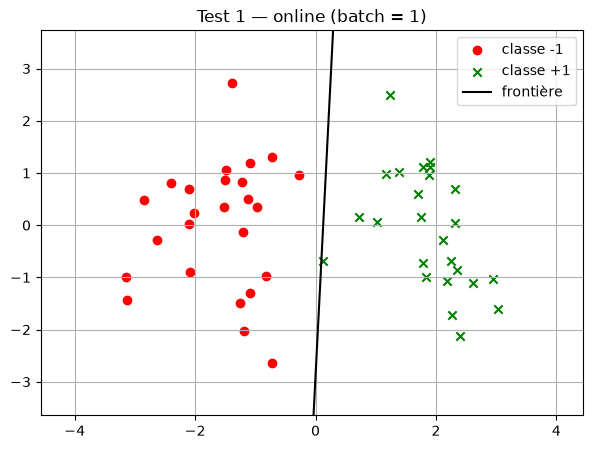

Époque   1 | erreur =  17.9550 | mal classés = 0
Convergence atteinte !
  [sauvegardé] figures/fig_016.pdf / .png


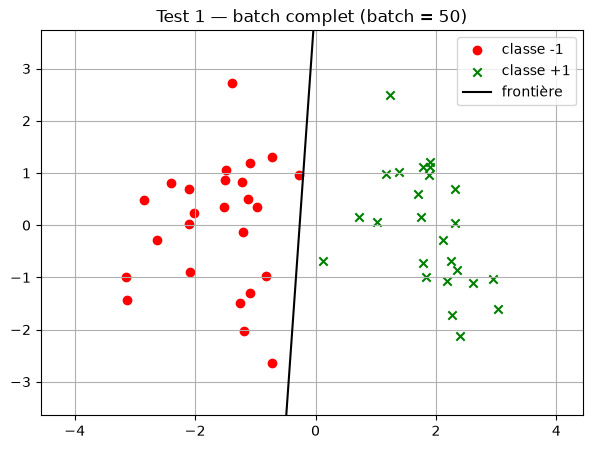

  [sauvegardé] figures/fig_017.pdf / .png


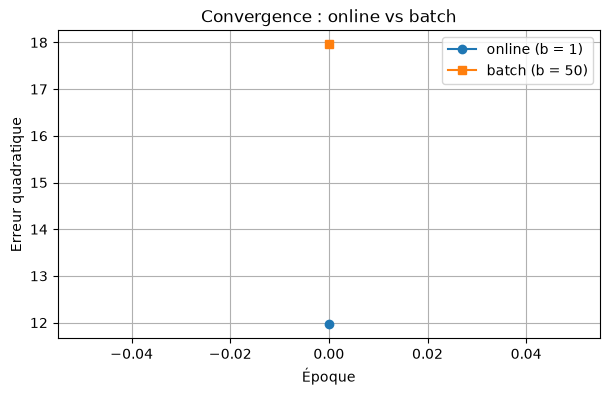

Époque   1 | erreur = 124.9616 | mal classés = 5
Époque   2 | erreur =  13.7000 | mal classés = 3
Époque   3 | erreur =  12.9651 | mal classés = 3
Époque   4 | erreur =  12.4205 | mal classés = 3
Époque   5 | erreur =  12.0009 | mal classés = 3
Époque   6 | erreur =  11.6620 | mal classés = 3
Époque   7 | erreur =  11.3706 | mal classés = 3
Époque   8 | erreur =  11.1037 | mal classés = 3
Époque   9 | erreur =  10.8467 | mal classés = 3
Époque  10 | erreur =  10.5919 | mal classés = 3
Époque  11 | erreur =  10.3383 | mal classés = 3
Époque  12 | erreur =  10.0912 | mal classés = 3
Époque  13 | erreur =   9.8608 | mal classés = 3
Époque  14 | erreur =   9.6584 | mal classés = 3
Époque  15 | erreur =   9.4922 | mal classés = 2
Époque  16 | erreur =   9.3648 | mal classés = 2
Époque  17 | erreur =   9.2734 | mal classés = 2
Époque  18 | erreur =   9.2113 | mal classés = 2
Époque  19 | erreur =   9.1707 | mal classés = 2
Époque  20 | erreur =   9.1445 | mal classés = 2
Époque  21 | erreur 

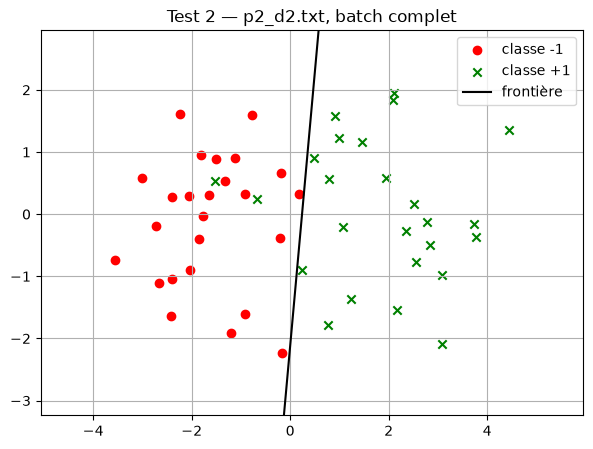

  [sauvegardé] figures/fig_019.pdf / .png


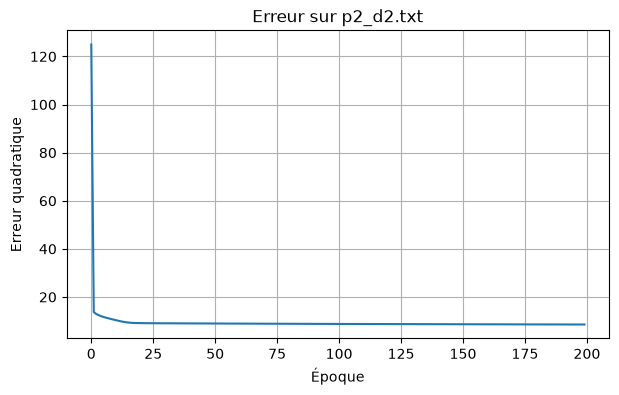

In [16]:
# --- Test 1 : p2_d1.txt, online puis batch complet ---
X_d1, y_d1 = charger_donnees("p2_d1.txt")

# a) Online
w_online, err_online = apprentissage_widrow_tanh(X_d1, y_d1, epoch=50, batch_size=1)
tracer_resultats(X_d1, y_d1, w_online, "Test 1 — online (batch = 1)")

# b) Batch complet
w_batch, err_batch = apprentissage_widrow_tanh(X_d1, y_d1, epoch=200, batch_size=50)
tracer_resultats(X_d1, y_d1, w_batch, "Test 1 — batch complet (batch = 50)")

# c) Évolution de l'erreur
plt.figure(figsize=(7, 4))
plt.plot(err_online, marker="o", label="online (b = 1)")
plt.plot(err_batch, marker="s", label="batch (b = 50)")
plt.xlabel("Époque")
plt.ylabel("Erreur quadratique")
plt.legend()
plt.grid(True)
plt.title("Convergence : online vs batch")
plt.show()

# --- Test 2 : p2_d2.txt (classes non séparables par une droite) ---
X_d2, y_d2 = charger_donnees("p2_d2.txt")
w_d2, err_d2 = apprentissage_widrow_tanh(X_d2, y_d2, epoch=200, batch_size=50)
tracer_resultats(X_d2, y_d2, w_d2, "Test 2 — p2_d2.txt, batch complet")

plt.figure(figsize=(7, 4))
plt.plot(err_d2)
plt.xlabel("Époque")
plt.ylabel("Erreur quadratique")
plt.title("Erreur sur p2_d2.txt")
plt.grid(True)
plt.show()

### Interprétation

- **Données séparables (`p2_d1.txt`)** : le nombre de points mal classés tombe à 0 et l'apprentissage s'arrête (message « Convergence atteinte »).
- **Données non séparables (`p2_d2.txt`)** : aucune droite ne classe tous les points correctement. Le nombre de mal classés ne tombe pas à 0 et l'apprentissage va jusqu'au nombre maximal d'époques. C'est la limite fondamentale du perceptron simple (Minsky et Papert, 1969), qui motive le perceptron multicouche.
- **Online vs batch** : le mode online effectue de nombreuses petites mises à jour (convergence souvent rapide mais plus bruitée) ; le mode par lots en effectue moins, mais plus stables, et peut demander plus d'époques. Les courbes d'erreur ci-dessus permettent de comparer les deux comportements.

## 3. Perceptron multicouche

### 3.1. Implémentation du réseau

Dans cette partie, nous implémentons un perceptron multicouche avec deux neurones dans la couche cachée et un neurone de sortie. Nous utilisons la fonction sigmoïde pour calculer les activations des neurones.

$
\varphi(v)=\frac{1}{1+e^{-v}}
$

Le seuil de chaque neurone est représenté par un poids associé à une entrée constante égale à \(1\).

Le réseau sera testé avec l’entrée \(x=(1,1)\), puis le résultat obtenu par programmation sera comparé au calcul manuel.
L'objectif est de comprendre la propagation des entrées dans le réseau avant de programmer l'apprentissage des poids.

In [17]:
def multiperceptron(X, w1, w2):
    # Ajouter le biais aux entrées
    X_biais = np.vstack((np.ones((1, X.shape[1])), X))

    # Calcul des sorties de la couche cachée
    z = w1.T @ X_biais

    # Fonction d'activation sigmoïde
    a = 1 / (1 + np.exp(-z))

    # Ajouter le biais à la couche cachée
    ah = np.vstack((np.ones((1, X.shape[1])), a))

    # Calcul de la sortie du réseau
    z_out = w2 @ ah

    # Fonction d'activation de sortie
    y = 1 / (1 + np.exp(-z_out))

    return y

### 3.2. Test de la propagation avant

Nous testons le réseau avec des poids initialisés pour vérifier que les calculs s'exécutent correctement et que les sorties sont comprises entre 0 et 1. À ce stade, les poids ne sont pas encore appris : ce test vérifie uniquement le fonctionnement du réseau.

In [18]:
# Deux exemples d'entrée
X_test = np.array([
    [0, 1],
    [0, 1]
])

# Initialisation des poids
np.random.seed(42)
w1_test = np.random.rand(3, 2)
w2_test = np.random.rand(3)

# Propagation avant
y_test = multiperceptron(X_test, w1_test, w2_test)

print("Sorties du réseau :")
print(y_test)

Sorties du réseau :
[0.73202101 0.77589839]


### 3.2 bis. Test sur le schéma du sujet et comparaison avec le calcul manuel

**Pourquoi la sigmoïde ?** Elle est dérivable, bornée dans $]0,1[$ et sa dérivée s'écrit à partir de sa sortie : $\varphi'(v) = \varphi(v)\,(1-\varphi(v))$. C'est idéal pour la rétropropagation.

**Architecture.**
- L'entrée augmentée $\tilde{x} = (1, x_1, x_2)$ comporte 3 valeurs.
- Chacun des 2 neurones cachés calcule un produit scalaire avec une colonne de `w1`.
- Le vecteur $a_h = (1, a_{h1}, a_{h2})$ alimente le neurone de sortie.
- Une seule sortie : classification binaire (seuil à 0,5).

Nous testons le réseau avec l'entrée $x = (1, 1)$ et les poids du schéma, puis nous comparons la sortie du programme au calcul fait « à la main » :

| | biais | poids de $x_1$ | poids de $x_2$ |
|---|---|---|---|
| Neurone caché 1 | 2 | −1 | 1 |
| Neurone caché 2 | 0,5 | 1 | 0,5 |
| Neurone de sortie | 2 | −1 (de $h_1$) | 1 (de $h_2$) |

In [19]:
def sigmoide(v):
    return 1 / (1 + np.exp(-v))


# Poids du schéma (une colonne de w1 par neurone caché)
w1_schema = np.array([[2.0, 0.5],
                      [-1.0, 1.0],
                      [1.0, 0.5]])
w2_schema = np.array([2.0, -1.0, 1.0])

# multiperceptron attend une matrice (2, N) : ici N = 1 exemple, x = (1, 1)
x_schema = np.array([[1], [1]])
y_prog = multiperceptron(x_schema, w1_schema, w2_schema)[0]

# --- Calcul manuel pour comparaison ---
x_aug = np.array([1, 1, 1])
v_h1 = np.dot(w1_schema[:, 0], x_aug)     # 2 - 1 + 1   = 2
v_h2 = np.dot(w1_schema[:, 1], x_aug)     # 0.5 + 1 + 0.5 = 2
a_h1 = sigmoide(v_h1)                     # ≈ 0.8808
a_h2 = sigmoide(v_h2)                     # ≈ 0.8808
v_out = w2_schema[0] + w2_schema[1] * a_h1 + w2_schema[2] * a_h2   # = 2
y_manuel = sigmoide(v_out)

print(f"Potentiels cachés : v_h1 = {v_h1}, v_h2 = {v_h2}")
print(f"Activations cachées : a_h1 = {a_h1:.4f}, a_h2 = {a_h2:.4f}")
print(f"Potentiel de sortie : v_out = {v_out:.4f}")
print(f"Sortie du programme : {y_prog:.4f}")
print(f"Sortie manuelle     : {y_manuel:.4f}")
print(f"Écart : {abs(y_prog - y_manuel):.2e}")

Potentiels cachés : v_h1 = 2.0, v_h2 = 2.0
Activations cachées : a_h1 = 0.8808, a_h2 = 0.8808
Potentiel de sortie : v_out = 2.0000
Sortie du programme : 0.8808
Sortie manuelle     : 0.8808
Écart : 0.00e+00


### 3.3. Apprentissage du perceptron multicouche

Nous allons maintenant entraîner le réseau à partir des données d'apprentissage. À chaque itération, nous calculons les activations de la couche cachée et de la sortie, puis l'erreur entre la prédiction et la cible. Cette erreur est rétropropagée pour mettre à jour les poids des deux couches.

Le taux d'apprentissage indiqué dans le sujet est $(\alpha=0.5$). Nous suivrons l'évolution de l'erreur pour évaluer l'apprentissage.

In [20]:
def multiperceptron_widraw(x, yd, Epoch, batch_size):

    # Initialiser les poids synaptiques
    # w1 : poids de la couche cachée (biais inclus)
    # w2 : poids de la couche de sortie (biais inclus)
    w1 = np.random.rand(3, 2)
    w2 = np.random.rand(3)

    alpha = 0.5
    erreur = []

    n_samples = x.shape[1]

    # Boucle d'apprentissage pour Epoch itérations
    for epoch in range(Epoch):

        # Parcours des lots (batch)
        for i in range(0, n_samples, batch_size):

            x_batch = x[:, i:i + batch_size]
            yd_batch = yd[i:i + batch_size]

            # Initialiser les erreurs pour le batch
            total_error = 0

            for j in range(x_batch.shape[1]):

                # Entrée avec biais
                x_biais = np.array([
                    1,
                    x_batch[0, j],
                    x_batch[1, j]
                ])

                # Calcul des sorties de la couche cachée
                z_h1 = w1[:, 0] @ x_biais
                z_h2 = w1[:, 1] @ x_biais

                # Fonction d'activation sigmoïde
                a_h1 = 1 / (1 + np.exp(-z_h1))
                a_h2 = 1 / (1 + np.exp(-z_h2))

                # Entrée pour la couche de sortie
                a_h = np.array([1, a_h1, a_h2])

                # Calcul de la sortie du réseau
                z_out = w2 @ a_h

                # Activation de sortie
                y_pred = 1 / (1 + np.exp(-z_out))

                # Calcul de l'erreur
                error = yd_batch[j] - y_pred
                total_error += error ** 2

                # Calcul des deltas avant la mise à jour
                delta_out = error * y_pred * (1 - y_pred)

                delta_h1 = (
                    delta_out * w2[1] * a_h1 * (1 - a_h1)
                )
                delta_h2 = (
                    delta_out * w2[2] * a_h2 * (1 - a_h2)
                )

                # Mise à jour des poids de la couche de sortie
                w2 += alpha * delta_out * a_h

                # Mise à jour des poids de la couche cachée
                w1[:, 0] += alpha * delta_h1 * x_biais
                w1[:, 1] += alpha * delta_h2 * x_biais

            # Ajout de l'erreur moyenne du batch
            erreur.append(total_error / x_batch.shape[1])

        # Affichage de l'erreur à chaque époque
        erreur_epoch = erreur[-1]
        print(
            f"Epoch {epoch + 1}/{Epoch}, "
            f"Erreur moyenne : {erreur_epoch:.4f}"
        )

        # Arrêt si l'erreur cumulée est nulle
        if total_error == 0:
            break

    return w1, w2, erreur

### 1.3.2. Apprentissage et évaluation du perceptron multicouche

On utilise un ensemble d’apprentissage constitué de points en deux dimensions et de leurs classes. On entraîne le réseau, puis on compare les classes prédites aux classes attendues.

On visualise ensuite :
- les points de l’ensemble d’apprentissage ;
- l’évolution de l’erreur pendant l’apprentissage ;
- les droites séparatrices des deux neurones cachés ;
- la frontière de décision finale du réseau.

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# Charger les données : 2 lignes, un individu par colonne
x = np.loadtxt("p2_d1.txt")

# Définir les étiquettes : 25 points de classe -1, puis 25 de classe +1
yd = np.concatenate((-np.ones(25), np.ones(25)))

print("Dimensions de x :", x.shape)
print("Dimensions de yd :", yd.shape)
print("Classes présentes :", np.unique(yd))

Dimensions de x : (2, 50)
Dimensions de yd : (50,)
Classes présentes : [-1.  1.]


  [sauvegardé] figures/fig_020.pdf / .png


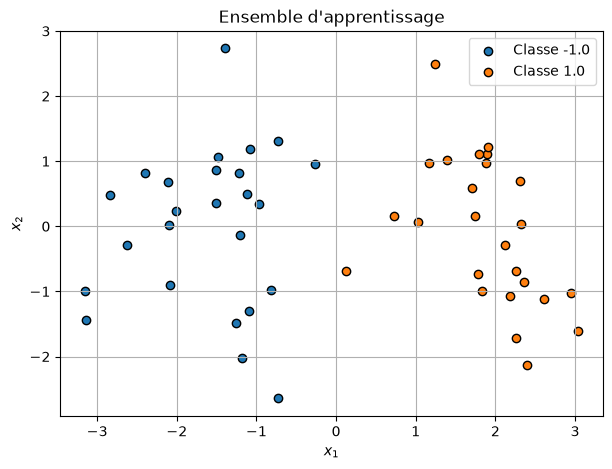

In [22]:
def affiche_classe(x, yd, titre="Ensemble d'apprentissage"):
    plt.figure(figsize=(7, 5))

    for classe in np.unique(yd):
        masque = yd == classe
        plt.scatter(
            x[0, masque],
            x[1, masque],
            label=f"Classe {classe}",
            edgecolors="black"
        )

    plt.xlabel("$x_1$")
    plt.ylabel("$x_2$")
    plt.title(titre)
    plt.legend()
    plt.grid(True)
    plt.show()


affiche_classe(x, yd)

### Entraînement du réseau

La fonction d’apprentissage utilise une sigmoïde en sortie. Si les étiquettes initiales sont \(-1\) et \(+1\), elles doivent être converties en \(0\) et \(1\) pour l’apprentissage. On conserve les étiquettes originales pour afficher et évaluer les classes.

In [23]:
classes = np.unique(yd)

if len(classes) != 2:
    raise ValueError("Cette fonction est prévue pour un problème à deux classes.")

# Conversion des étiquettes vers 0 et 1 pour la sigmoïde
if np.array_equal(classes, [-1, 1]):
    yd_train = (yd + 1) / 2
elif np.array_equal(classes, [0, 1]):
    yd_train = yd.copy()
else:
    yd_train = (yd == classes[1]).astype(float)

# Paramètres d'apprentissage
Epoch = 10
batch_size = 1  # apprentissage en ligne

# Entraînement
w1, w2, erreur = multiperceptron_widraw(
    x, yd_train, Epoch, batch_size
)

print("\nPoids finaux de la couche cachée :")
print(w1)

print("\nPoids finaux de la couche de sortie :")
print(w2)

Epoch 1/10, Erreur moyenne : 0.0287
Epoch 2/10, Erreur moyenne : 0.0204
Epoch 3/10, Erreur moyenne : 0.0160
Epoch 4/10, Erreur moyenne : 0.0127
Epoch 5/10, Erreur moyenne : 0.0102
Epoch 6/10, Erreur moyenne : 0.0083
Epoch 7/10, Erreur moyenne : 0.0069
Epoch 8/10, Erreur moyenne : 0.0058
Epoch 9/10, Erreur moyenne : 0.0050
Epoch 10/10, Erreur moyenne : 0.0043

Poids finaux de la couche cachée :
[[ 0.17676817 -0.25940078]
 [ 2.09156093  2.20945711]
 [-0.05559678 -0.09865914]]

Poids finaux de la couche de sortie :
[-2.16383921  2.15172035  2.70832586]


  [sauvegardé] figures/fig_021.pdf / .png


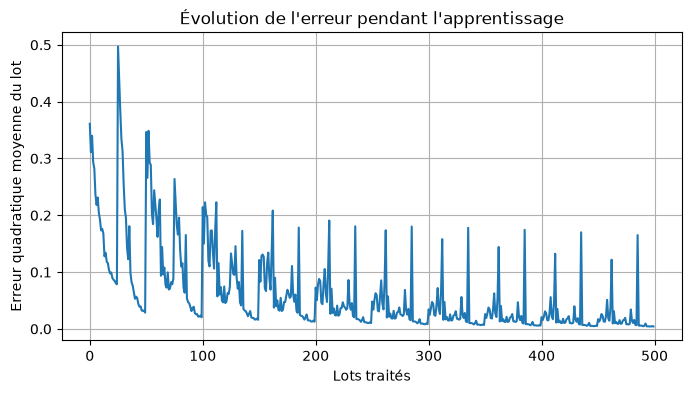

In [24]:
plt.figure(figsize=(8, 4))
plt.plot(erreur)
plt.xlabel("Lots traités")
plt.ylabel("Erreur quadratique moyenne du lot")
plt.title("Évolution de l'erreur pendant l'apprentissage")
plt.grid(True)
plt.show()

### Afficher les droites séparatrices des neurones cachés

Chaque neurone caché définit une droite dans le plan d’entrée lorsque son potentiel est nul :
$
w_{0}+w_{1}x_1+w_{2}x_2=0
$
On affiche ces deux droites avec les points de l’ensemble d’apprentissage.

  [sauvegardé] figures/fig_022.pdf / .png


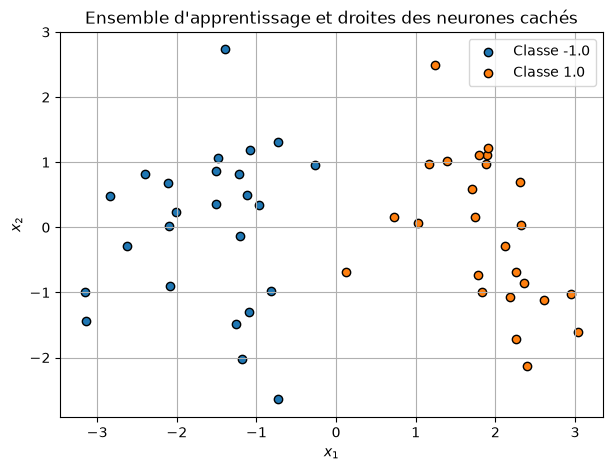

  [sauvegardé] figures/fig_023.pdf / .png


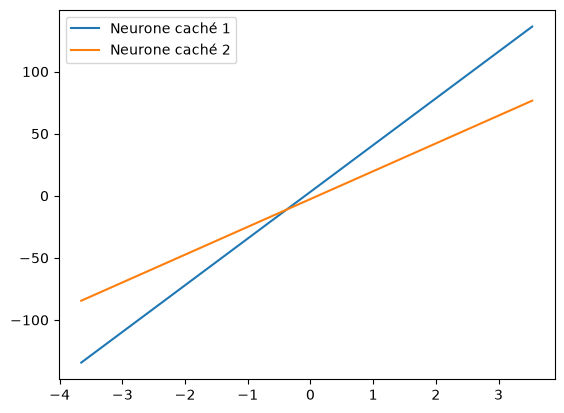

In [25]:
def afficher_droites_cachees(x, yd, w1):
    affiche_classe(x, yd, "Ensemble d'apprentissage et droites des neurones cachés")

    ax = plt.gca()
    t = np.linspace(x[0].min() - 0.5, x[0].max() + 0.5, 200)

    for j in range(2):
        poids = w1[:, j]

        # w[0] + w[1]*x1 + w[2]*x2 = 0
        if not np.isclose(poids[2], 0):
            z = -(poids[0] + poids[1] * t) / poids[2]
            ax.plot(t, z, label=f"Neurone caché {j + 1}")
        elif not np.isclose(poids[1], 0):
            x_vertical = -poids[0] / poids[1]
            ax.axvline(x_vertical, label=f"Neurone caché {j + 1}")

    ax.legend()
    plt.show()


afficher_droites_cachees(x, yd, w1)

  [sauvegardé] figures/fig_024.pdf / .png


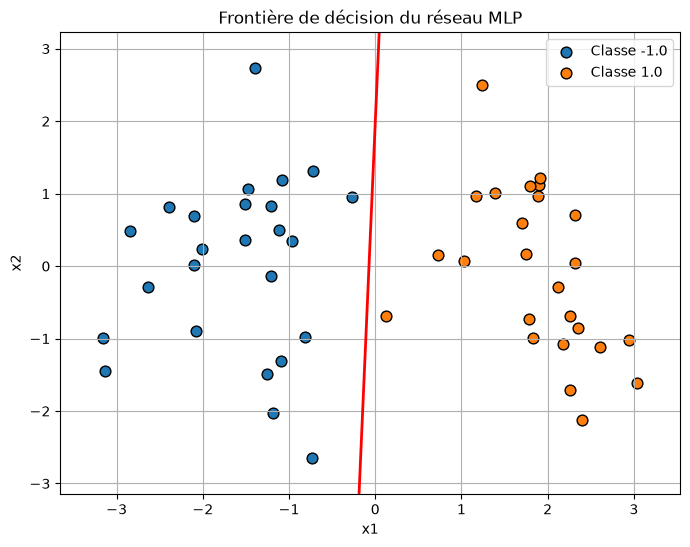

In [26]:

import numpy as np
import matplotlib.pyplot as plt

def afficher_frontiere_reseau(x, yd, w1, w2, resolution=200):
    # Vérifier les dimensions des données
    x = np.asarray(x)
    yd = np.asarray(yd).ravel()

    if x.ndim != 2 or x.shape[0] != 2:
        raise ValueError(f"x doit être de forme (2, N), forme reçue : {x.shape}")

    if x.shape[1] != len(yd):
        raise ValueError("Le nombre de points dans x doit correspondre à yd.")

    # Construire la grille couvrant les données
    marge = 0.5
    x1_min, x1_max = x[0, :].min() - marge, x[0, :].max() + marge
    x2_min, x2_max = x[1, :].min() - marge, x[1, :].max() + marge

    xx1, xx2 = np.meshgrid(
        np.linspace(x1_min, x1_max, resolution),
        np.linspace(x2_min, x2_max, resolution)
    )

    # Transformer la grille en matrice de forme (2, N)
    grille = np.vstack((xx1.ravel(), xx2.ravel()))

    # IMPORTANT : multiperceptron reçoit toute la matrice (2, N)
    sorties = np.asarray(
        multiperceptron(grille, w1, w2)
    ).reshape(xx1.shape)

    # Afficher les points d'apprentissage
    plt.figure(figsize=(8, 6))

    for classe in np.unique(yd):
        masque = (yd == classe)
        plt.scatter(
            x[0, masque], x[1, masque],
            label=f"Classe {classe}",
            edgecolors="black",
            s=60
        )

    # Tracer la frontière de décision du réseau
    plt.contour(
        xx1, xx2, sorties,
        levels=[0.5],
        colors="red",
        linewidths=2
    )

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title("Frontière de décision du réseau MLP")
    plt.legend()
    plt.grid(True)
    plt.show()


# Afficher la frontière du réseau entraîné
afficher_frontiere_reseau(x, yd, w1, w2)


#### Classes prédites et points mal classés

Comme annoncé en début de section, nous comparons les classes prédites par le réseau aux classes attendues. La sortie sigmoïde est comparée au seuil $0{,}5$ : au-dessus, la classe prédite est $+1$ ; en dessous, elle vaut $-1$. Les points mal classés (s'il y en a) sont entourés en noir.

Points mal classés : 0 / 50
Accuracy sur l'ensemble d'apprentissage : 100.00%

Matrice de confusion (lignes : réel, colonnes : prédit)
              prédit -1   prédit +1
  réel -1          25           0
  réel +1           0          25
  [sauvegardé] figures/fig_025.pdf / .png


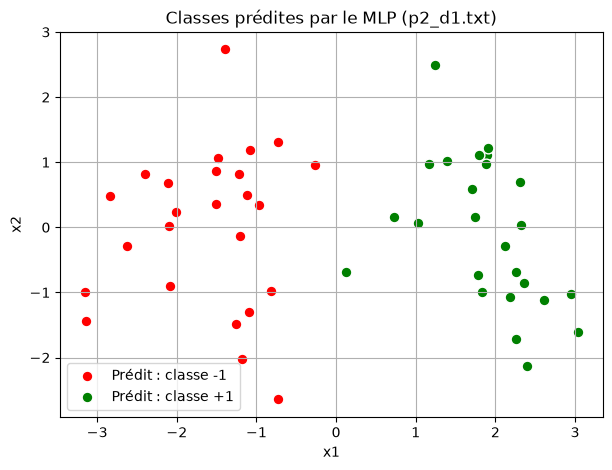

In [27]:
# Sorties du réseau entraîné pour les 50 points (matrice (2, 50) attendue par multiperceptron)
sorties_mlp = multiperceptron(x, w1, w2)
classes_predites_mlp = np.where(sorties_mlp >= 0.5, 1, -1)

mal_classes_mlp = classes_predites_mlp != yd
n_mal_mlp = int(mal_classes_mlp.sum())

print(f"Points mal classés : {n_mal_mlp} / {len(yd)}")
print(f"Accuracy sur l'ensemble d'apprentissage : {1 - n_mal_mlp / len(yd):.2%}")

# Matrice de confusion 2 x 2 (lignes : classe réelle, colonnes : classe prédite)
print("\nMatrice de confusion (lignes : réel, colonnes : prédit)")
print("              prédit -1   prédit +1")
for classe_reelle in (-1, 1):
    ligne = [int(np.sum((yd == classe_reelle) & (classes_predites_mlp == cp))) for cp in (-1, 1)]
    print(f"  réel {classe_reelle:+d}  {ligne[0]:10d}  {ligne[1]:10d}")

# Affichage : couleur = classe prédite, contour noir = point mal classé
plt.figure(figsize=(7, 5))
for classe, couleur in [(-1, "red"), (1, "green")]:
    masque = classes_predites_mlp == classe
    plt.scatter(x[0, masque], x[1, masque], c=couleur, s=60,
                edgecolors="white", label=f"Prédit : classe {classe:+d}")

if n_mal_mlp > 0:
    plt.scatter(x[0, mal_classes_mlp], x[1, mal_classes_mlp],
                facecolors="none", edgecolors="black", s=180, linewidths=2,
                label="Point mal classé")

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Classes prédites par le MLP (p2_d1.txt)")
plt.legend()
plt.grid(True)
plt.show()

### Test complémentaire : apprentissage du XOR

Le XOR n'est pas linéairement séparable : un perceptron simple ne peut pas le résoudre (section 1.2). Un perceptron multicouche avec 2 neurones cachés y parvient, car la composition de deux couches sigmoïdes produit une frontière non linéaire.

Nous utilisons ici une version **vectorisée** de la rétropropagation : les gradients sont calculés sur tout le lot, puis les poids sont mis à jour avec le gradient moyen. Elle est nommée `multiperceptron_widrow_vectorise` pour ne pas remplacer `multiperceptron_widraw` de la section 3.3.

In [28]:
def multiperceptron_widrow_vectorise(x, yd, Epoch, batch_size,
                                     alpha=0.5, seed=42, verbose=True):
    """
    Entraîne un MLP 2-2-1 (sigmoïde partout) par rétropropagation vectorisée.

    x          : np.ndarray (2, N) — un exemple par colonne
    yd         : np.ndarray (N,)   — étiquettes dans {0, 1}
    Epoch      : nombre d'époques
    batch_size : taille des lots
    alpha      : taux d'apprentissage
    seed       : graine aléatoire

    Retour : w1 (3x2), w2 (3,), erreurs (erreur quadratique cumulée par époque)
    """
    rng = np.random.default_rng(seed)
    N = x.shape[1]

    # Initialisation aléatoire de petits poids
    w1 = rng.uniform(-0.5, 0.5, size=(3, 2))   # [biais, w_x1, w_x2] x 2 neurones
    w2 = rng.uniform(-0.5, 0.5, size=3)        # [biais, w_h1, w_h2]

    x_biais = np.vstack([np.ones(N), x])       # (3, N)
    erreurs = []

    for ep in range(Epoch):
        erreur_epoch = 0.0

        for start in range(0, N, batch_size):
            end = min(start + batch_size, N)
            xb = x_biais[:, start:end]          # (3, B)
            yd_b = yd[start:end]                # (B,)
            B = xb.shape[1]

            # ---- Propagation avant ----
            h = sigmoide(w1.T @ xb)                 # (2, B)
            a_h = np.vstack([np.ones(B), h])        # (3, B) avec biais
            y = sigmoide(w2 @ a_h)                  # (B,)

            erreur_epoch += np.sum((yd_b - y) ** 2)

            # ---- Rétropropagation ----
            d_out = (yd_b - y) * y * (1 - y)                       # (B,)
            grad_w2 = a_h @ d_out                                  # (3,)
            d_h = (w2[1:, None] * d_out[None, :]) * h * (1 - h)    # (2, B)
            grad_w1 = xb @ d_h.T                                   # (3, 2)

            # ---- Mise à jour ----
            w2 += (alpha / B) * grad_w2
            w1 += (alpha / B) * grad_w1

        erreurs.append(erreur_epoch)

        if verbose and (ep % max(1, Epoch // 10) == 0 or ep == Epoch - 1):
            print(f"Époque {ep + 1:5d} | erreur = {erreur_epoch:.6f}")

    return w1, w2, np.array(erreurs)

>>> Entraînement du MLP sur le XOR

Époque     1 | erreur = 1.011928
Époque   501 | erreur = 1.000124
Époque  1001 | erreur = 1.000009
Époque  1501 | erreur = 0.999932
Époque  2001 | erreur = 0.999742
Époque  2501 | erreur = 0.998476
Époque  3001 | erreur = 0.930663
Époque  3501 | erreur = 0.718125
Époque  4001 | erreur = 0.087647
Époque  4501 | erreur = 0.019114
Époque  5000 | erreur = 0.010378

Prédictions après apprentissage :
  x = [0 0]  y = 0.0515  classe = 0  attendu = 0  [OK]
  x = [0 1]  y = 0.9461  classe = 1  attendu = 1  [OK]
  x = [1 0]  y = 0.9480  classe = 1  attendu = 1  [OK]
  x = [1 1]  y = 0.0460  classe = 0  attendu = 0  [OK]
  [sauvegardé] figures/fig_026.pdf / .png


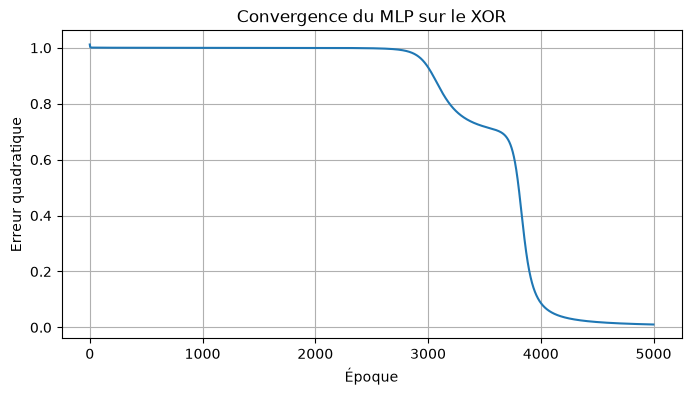

In [29]:
X_xor = np.array([[0, 0],
                  [0, 1],
                  [1, 0],
                  [1, 1]]).T          # (2, 4)
yd_xor = np.array([0, 1, 1, 0])       # XOR, étiquettes dans {0, 1} pour la sigmoïde

print(">>> Entraînement du MLP sur le XOR\n")
w1_xor, w2_xor, err_xor = multiperceptron_widrow_vectorise(
    X_xor, yd_xor, Epoch=5000, batch_size=4, alpha=2.0
)

# Prédictions finales (multiperceptron prend la matrice (2, N))
sorties_xor = multiperceptron(X_xor, w1_xor, w2_xor)

print("\nPrédictions après apprentissage :")
for i in range(4):
    classe = 1 if sorties_xor[i] >= 0.5 else 0
    ok = "OK" if classe == yd_xor[i] else "FAUX"
    print(f"  x = {X_xor[:, i]}  y = {sorties_xor[i]:.4f}  classe = {classe}  attendu = {yd_xor[i]}  [{ok}]")

plt.figure(figsize=(8, 4))
plt.plot(err_xor)
plt.xlabel("Époque")
plt.ylabel("Erreur quadratique")
plt.title("Convergence du MLP sur le XOR")
plt.grid(True)
plt.show()

**Lecture des résultats**

- L'erreur quadratique présente d'abord un **plateau** (proche de 1) pendant plusieurs milliers d'époques, puis chute brutalement lorsque le réseau trouve une configuration de poids adaptée : c'est un comportement classique sur le XOR.
- Après apprentissage, les quatre sorties doivent être proches de 0 ou de 1 et les quatre classes correctement prédites. Avec la graine 42 et $\alpha = 2$, l'erreur finale est d'environ 0,01 et les sorties valent environ 0,05 / 0,95 / 0,95 / 0,05.
- Le perceptron simple ne résout pas le XOR (données non linéairement séparables) alors que le MLP 2-2-1 y parvient grâce à sa couche cachée. Cela illustre le théorème d'approximation universelle : une seule couche cachée suffit, en théorie, pour approcher toute fonction continue.

### Conclusion de Partie I

Les résultats permettent d’évaluer la capacité du perceptron multicouche à apprendre les classes de l’ensemble d’apprentissage. La courbe d’erreur renseigne sur l’évolution de l’apprentissage, tandis que les droites des neurones cachés et la frontière finale permettent de visualiser la séparation des classes.

Le nombre de points mal classés permet de vérifier si le réseau a correctement appris les données. Si des erreurs subsistent, il faut notamment examiner le nombre d’époques, l’initialisation des poids et le taux d’apprentissage.

## Partie II : Réseaux denses et réseaux profonds

In [30]:

import numpy as np
import pandas as pd
from pathlib import Path

# Vérifier la présence du fichier Excel
fichier = Path("WangSignatures.xlsx")
if not fichier.exists():
    raise FileNotFoundError(
        "WangSignatures.xlsx est introuvable. "
        "Place-le dans le répertoire du notebook ou indique son chemin."
    )

# Noms exacts des onglets indiqués dans le TP
descripteurs = {
    "JCD": "WangSignaturesJCD",
    "PHOG": "WangSignaturesPHOG",
    "CEDD": "WangSignaturesCEDD",
    "FCTH": "WangSignaturesFCTH",
    "FuzzyColorHistogram": "WangSignaturesFuzzyColorHistogr"
}

X_descripteurs = {}
label = None

for nom, feuille in descripteurs.items():
    # La première colonne contient le nom de l'image
    df = pd.read_excel(
        fichier,
        sheet_name=feuille,
        header=None,
        index_col=0
    )

    # Construire les étiquettes à partir des noms de fichiers
    noms_images = df.index.astype(str)
    labels_feuille = np.array([
        int(nom_image.rsplit(".", 1)[0]) // 100
        for nom_image in noms_images
    ])

    # Vérifier que les onglets utilisent le même ordre d'images
    if label is None:
        label = labels_feuille
        noms_reference = noms_images.to_numpy()
    else:
        if not np.array_equal(noms_images.to_numpy(), noms_reference):
            raise ValueError(
                f"L'ordre des images diffère dans l'onglet {feuille}."
            )
        if not np.array_equal(labels_feuille, label):
            raise ValueError(
                f"Les étiquettes diffèrent dans l'onglet {feuille}."
            )

    # Extraire les caractéristiques numériques
    X = df.to_numpy(dtype=np.float32)

    if not np.isfinite(X).all():
        raise ValueError(
            f"Valeurs manquantes ou non finies dans l'onglet {feuille}."
        )

    X_descripteurs[nom] = X

# Afficher un bilan des données importées
print("Nombre d'images :", len(label))
print("Classes présentes :", np.unique(label))
print("Effectifs par classe :", np.bincount(label, minlength=10))
print("\nDimensions des descripteurs :")

for nom, X in X_descripteurs.items():
    print(f"{nom:22s} : {X.shape}")

print("\nPremières étiquettes :", label[:10])


c:\Users\abdel\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Nombre d'images : 1000
Classes présentes : [0 1 2 3 4 5 6 7 8 9]
Effectifs par classe : [100 100 100 100 100 100 100 100 100 100]

Dimensions des descripteurs :
JCD                    : (1000, 168)
PHOG                   : (1000, 255)
CEDD                   : (1000, 144)
FCTH                   : (1000, 192)
FuzzyColorHistogram    : (1000, 125)

Premières étiquettes : [0 0 0 1 1 1 1 1 1 1]


#### Aperçu d'un onglet brut du fichier Excel

Nous affichons la forme et les premières lignes de l'onglet `JCD`. La première colonne contient le nom de l'image (`0.jpg`, `1.jpg`, `10.jpg`, `100.jpg`, ...) : les images sont donc rangées par ordre **alphabétique** des noms et non par ordre numérique. C'est pour cela que la classe est calculée à partir du **nom** de chaque image (numéro // 100) et jamais à partir de sa position dans le tableau.

In [31]:
# Onglet brut JCD : première colonne = nom de l'image, autres colonnes = descripteur
df_apercu = pd.read_excel(
    fichier,
    sheet_name=descripteurs["JCD"],
    header=None,
    index_col=0
)

print("Forme brute (JCD)        :", df_apercu.shape)
print("5 premiers noms d'images :", list(df_apercu.index[:5]))
print("Classes correspondantes  :", [int(str(n).rsplit('.', 1)[0]) // 100 for n in df_apercu.index[:5]])

display(df_apercu.iloc[:5, :8])

Forme brute (JCD)        : (1000, 168)
5 premiers noms d'images : ['0.jpg', '1.jpg', '10.jpg', '100.jpg', '101.jpg']
Classes correspondantes  : [0, 0, 0, 1, 1]


,1,2,3,4,5,6,7,8
0,,,,,,,,
0.jpg,0.5,2.0,2.0,0.5,1.0,1.0,2.0,1.5
1.jpg,0.5,3.0,3.5,1.0,0.5,2.5,3.0,2.5
10.jpg,3.5,3.0,1.0,0.5,0.5,1.5,2.5,2.5
100.jpg,0.5,3.0,1.0,1.0,0.5,1.5,1.0,1.0
101.jpg,4.0,4.5,0.5,0.0,0.0,0.5,0.5,0.0


### 2.1.2 Préparation des données d’apprentissage et de test

Nous séparons aléatoirement la base en `80 %` pour l’apprentissage et `20 %` pour le test, en conservant la proportion de chaque classe grâce à `stratify=label`. Les données de test simulent les images inconnues. La normalisation sera ajustée uniquement sur l’ensemble d’apprentissage.

In [32]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Une seule séparation commune à tous les descripteurs
indices = np.arange(len(label))

idx_train, idx_test = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=label
)

y_train = label[idx_train]
y_test = label[idx_test]

print("Taille apprentissage :", len(idx_train))
print("Taille test :", len(idx_test))

print("\nRépartition des classes dans l'ensemble d'apprentissage :")
print(np.bincount(y_train, minlength=10))

print("\nRépartition des classes dans l'ensemble de test :")
print(np.bincount(y_test, minlength=10))


Taille apprentissage : 800
Taille test : 200

Répartition des classes dans l'ensemble d'apprentissage :
[80 80 80 80 80 80 80 80 80 80]

Répartition des classes dans l'ensemble de test :
[20 20 20 20 20 20 20 20 20 20]


### 2.1.2 Classification par perceptron multicouche (MLP)

Nous utilisons un réseau dense réalisé avec **Keras**. La couche de sortie possède `10 neurones` et utilise `softmax` pour produire une probabilité pour chacune des classes. La fonction de coût est `sparse_categorical_crossentropy`, adaptée aux étiquettes entières de 0 à 9.

In [33]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Fixer les graines aléatoires pour faciliter la reproductibilité
np.random.seed(42)
tf.random.set_seed(42)

def creer_mlp(nb_caracteristiques, neurones=128, dropout=0.3):
    model = keras.Sequential([
        keras.Input(shape=(nb_caracteristiques,)),
        layers.Dense(neurones, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


c:\Users\abdel\anaconda3\Lib\site-packages\keras\src\export\tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


### Entraînement et évaluation avec un descripteur

Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.3422 - loss: 2.0535 - val_accuracy: 0.5688 - val_loss: 1.5295
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6828 - loss: 1.1619 - val_accuracy: 0.7000 - val_loss: 1.0924
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7406 - loss: 0.8454 - val_accuracy: 0.7312 - val_loss: 0.8794
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8172 - loss: 0.6149 - val_accuracy: 0.7937 - val_loss: 0.7604
Epoch 5/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8250 - loss: 0.5251 - val_accuracy: 0.7875 - val_loss: 0.7005
Epoch 6/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8578 - loss: 0.4616 - val_accuracy: 0.8062 - val_loss: 0.6602
Epoch 7/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8922 - loss: 0.3823 - val_accuracy: 0.8125 - val_loss: 0.6302
Epoch 8/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9031 - loss: 0.3168 - val_accuracy: 0.8125 - val_los

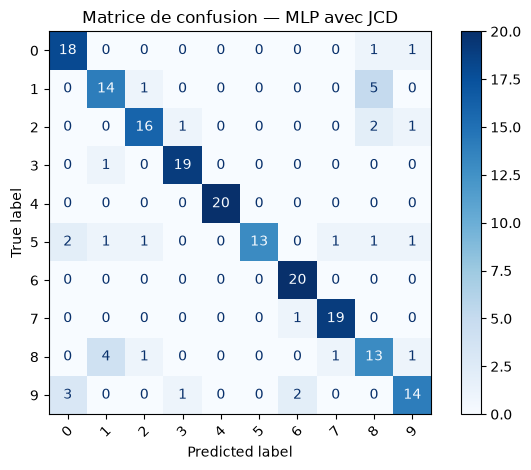

In [34]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)
import matplotlib.pyplot as plt

# Standardisation sans fuite d'information
scaler_jcd = StandardScaler()

X_train_jcd = scaler_jcd.fit_transform(
    X_descripteurs["JCD"][idx_train]
)
X_test_jcd = scaler_jcd.transform(
    X_descripteurs["JCD"][idx_test]
)

# Création et entraînement du modèle
model_jcd = creer_mlp(X_train_jcd.shape[1])

historique_jcd = model_jcd.fit(
    X_train_jcd,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=7,
            restore_best_weights=True
        )
    ],
    verbose=1
)

# Évaluation sur les données de test
loss_jcd, accuracy_jcd = model_jcd.evaluate(
    X_test_jcd, y_test, verbose=0
)

probabilites_jcd = model_jcd.predict(X_test_jcd, verbose=0)
y_pred_jcd = np.argmax(probabilites_jcd, axis=1)

print(f"Précision sur le test : {accuracy_jcd:.4f}")
print(f"Taux d'erreur : {1 - accuracy_jcd:.4f}")

print("\nRapport de classification :")
print(classification_report(y_test, y_pred_jcd, zero_division=0))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred_jcd),
    display_labels=np.arange(10)
).plot(cmap="Blues", xticks_rotation=45)

plt.title("Matrice de confusion — MLP avec JCD")
plt.tight_layout()
plt.show()


### Évolution de l’apprentissage

Nous observons l’évolution de la précision et de la fonction de coût pour les données d’apprentissage et de validation. Un écart croissant entre ces courbes peut indiquer un surapprentissage.

  [sauvegardé] figures/fig_028.pdf / .png


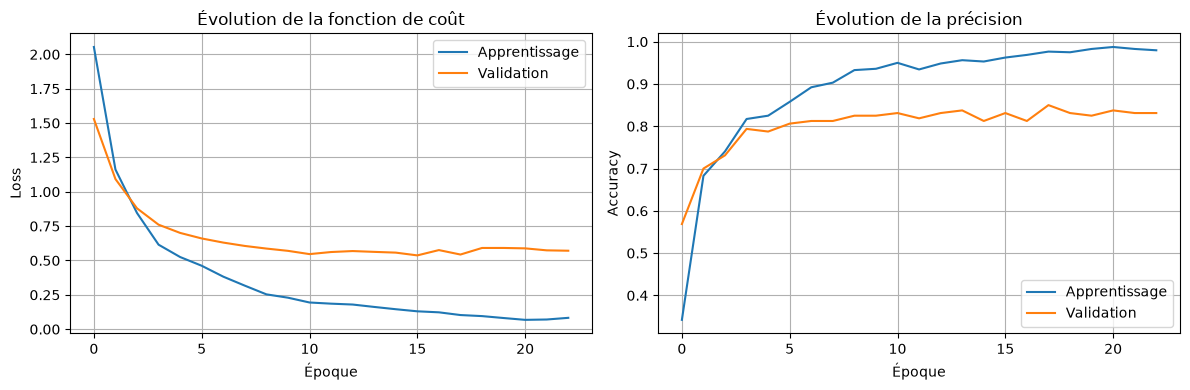

In [35]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(historique_jcd.history["loss"], label="Apprentissage")
axes[0].plot(historique_jcd.history["val_loss"], label="Validation")
axes[0].set_title("Évolution de la fonction de coût")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(historique_jcd.history["accuracy"], label="Apprentissage")
axes[1].plot(historique_jcd.history["val_accuracy"], label="Validation")
axes[1].set_title("Évolution de la précision")
axes[1].set_xlabel("Époque")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


### Remarques sur les choix de modélisation

- **Standardisation (`StandardScaler`)** : les descripteurs n'ont pas les mêmes échelles ; sans normalisation, les attributs de grande amplitude dominent l'apprentissage. Le scaler est ajusté uniquement sur l'apprentissage, sans fuite d'information.
- **Dropout** : régularisation qui limite la mémorisation de l'ensemble d'apprentissage, utile avec peu d'exemples (800 images d'apprentissage).
- **`validation_split`** : une partie de l'apprentissage est réservée au suivi du surapprentissage.
- **`sparse_categorical_crossentropy`** : les étiquettes sont des entiers de 0 à 9, sans encodage one-hot.

### Tester les cinq descripteurs et leur concaténation

Nous répétons la même expérience pour chaque descripteur, avec la même séparation apprentissage/test. Nous comparons les précisions sur le test et les taux d’erreur.


--- Descripteur : JCD ---
Accuracy test : 0.8550
Taux d'erreur : 0.1450
  [sauvegardé] figures/fig_029.pdf / .png


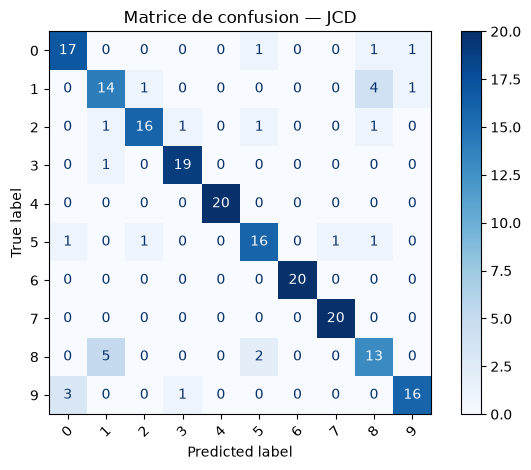


--- Descripteur : PHOG ---
Accuracy test : 0.6050
Taux d'erreur : 0.3950
  [sauvegardé] figures/fig_030.pdf / .png


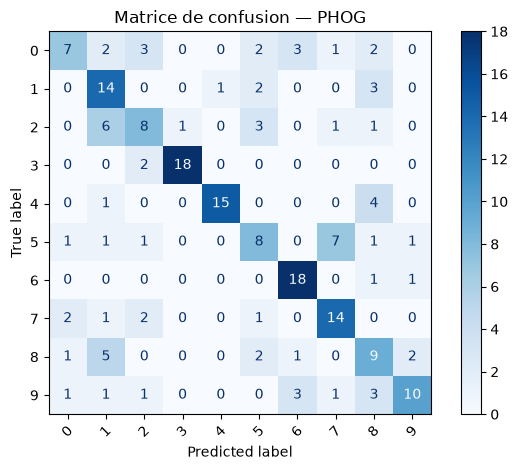


--- Descripteur : CEDD ---
Accuracy test : 0.8300
Taux d'erreur : 0.1700
  [sauvegardé] figures/fig_031.pdf / .png


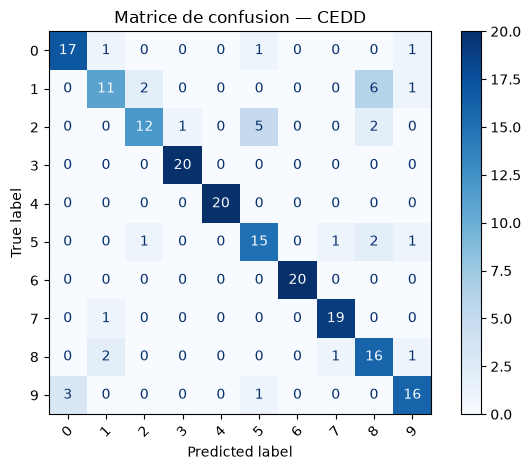


--- Descripteur : FCTH ---
Accuracy test : 0.7550
Taux d'erreur : 0.2450
  [sauvegardé] figures/fig_032.pdf / .png


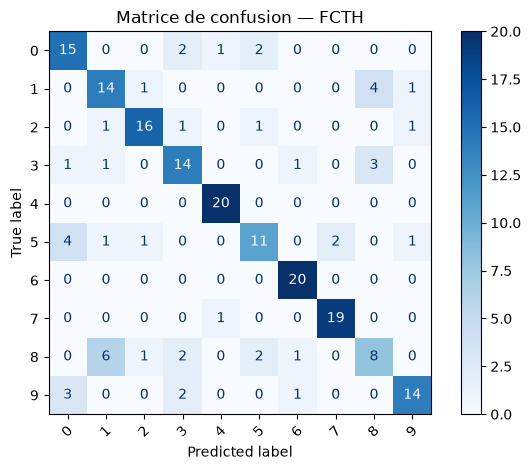


--- Descripteur : FuzzyColorHistogram ---
Accuracy test : 0.7700
Taux d'erreur : 0.2300
  [sauvegardé] figures/fig_033.pdf / .png


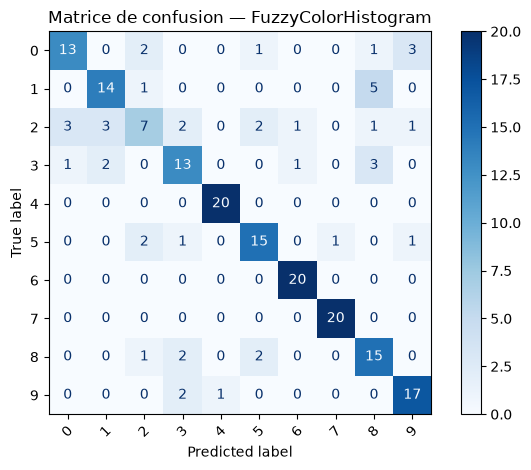


--- Descripteur : Concaténation ---
Accuracy test : 0.8150
Taux d'erreur : 0.1850
  [sauvegardé] figures/fig_034.pdf / .png


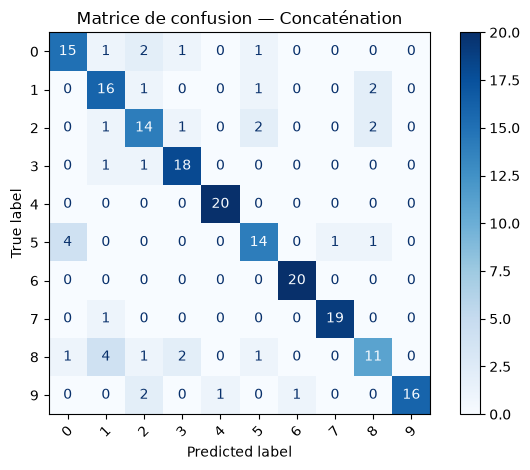

,Descripteur,Accuracy test,Taux d'erreur
0,JCD,0.855,0.145
2,CEDD,0.830,0.170
5,Concaténation,0.815,0.185
4,FuzzyColorHistogram,0.770,0.230
3,FCTH,0.755,0.245
1,PHOG,0.605,0.395


In [36]:

# Préparer les données : chaque descripteur est normalisé séparément.
X_train_descripteurs = {}
X_test_descripteurs = {}

for nom, X in X_descripteurs.items():
    scaler = StandardScaler()

    X_train_descripteurs[nom] = scaler.fit_transform(X[idx_train])
    X_test_descripteurs[nom] = scaler.transform(X[idx_test])

# Concaténer les descripteurs normalisés
X_train_descripteurs["Concaténation"] = np.concatenate(
    [X_train_descripteurs[nom] for nom in descripteurs],
    axis=1
)

X_test_descripteurs["Concaténation"] = np.concatenate(
    [X_test_descripteurs[nom] for nom in descripteurs],
    axis=1
)

# Entraîner et évaluer un MLP par représentation
resultats_mlp = []
modeles_mlp = {}
historiques_mlp = {}

for nom, Xtr in X_train_descripteurs.items():
    print(f"\n--- Descripteur : {nom} ---")

    Xte = X_test_descripteurs[nom]
    model = creer_mlp(Xtr.shape[1])

    historique = model.fit(
        Xtr,
        y_train,
        epochs=50,
        batch_size=32,
        validation_split=0.2,
        callbacks=[
            keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=7,
                restore_best_weights=True
            )
        ],
        verbose=0
    )

    loss, accuracy = model.evaluate(Xte, y_test, verbose=0)
    predictions = np.argmax(model.predict(Xte, verbose=0), axis=1)

    resultats_mlp.append({
        "Descripteur": nom,
        "Accuracy test": accuracy,
        "Taux d'erreur": 1 - accuracy
    })

    modeles_mlp[nom] = model
    historiques_mlp[nom] = historique

    print(f"Accuracy test : {accuracy:.4f}")
    print(f"Taux d'erreur : {1 - accuracy:.4f}")

    ConfusionMatrixDisplay(
        confusion_matrix(y_test, predictions),
        display_labels=np.arange(10)
    ).plot(cmap="Blues", xticks_rotation=45)

    plt.title(f"Matrice de confusion — {nom}")
    plt.tight_layout()
    plt.show()

tableau_mlp = pd.DataFrame(resultats_mlp)
display(tableau_mlp.sort_values("Accuracy test", ascending=False))


### Comparaison graphique des descripteurs (MLP)

Nous résumons les résultats précédents sous forme de diagramme en barres, avec la dimension de chaque descripteur et la précision obtenue sur le test.

Descripteur              Dimension   Accuracy test
--------------------------------------------------
JCD                            168          0.8550
PHOG                           255          0.6050
CEDD                           144          0.8300
FCTH                           192          0.7550
FuzzyColorHistogram            125          0.7700
Concaténation                  884          0.8150
  [sauvegardé] figures/fig_035.pdf / .png


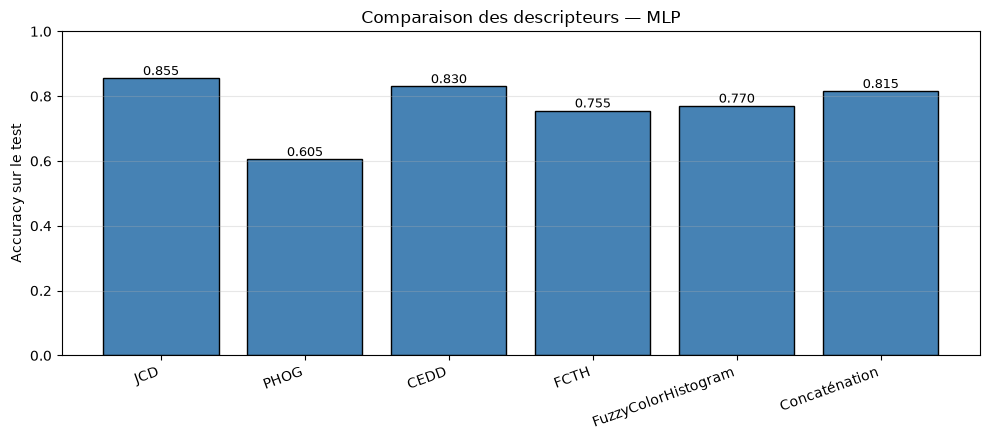

In [37]:
# Dimension de chaque représentation
dimensions_descripteurs = {nom: X.shape[1] for nom, X in X_descripteurs.items()}
dimensions_descripteurs["Concaténation"] = X_train_descripteurs["Concaténation"].shape[1]

acc_mlp_par_descripteur = tableau_mlp.set_index("Descripteur")["Accuracy test"]

print(f"{'Descripteur':<24}{'Dimension':>10}{'Accuracy test':>16}")
print("-" * 50)
for nom, acc in acc_mlp_par_descripteur.items():
    print(f"{nom:<24}{dimensions_descripteurs[nom]:>10d}{acc:>16.4f}")

plt.figure(figsize=(10, 4.5))
plt.bar(acc_mlp_par_descripteur.index, acc_mlp_par_descripteur.values,
        color="steelblue", edgecolor="k")
for i, v in enumerate(acc_mlp_par_descripteur.values):
    plt.text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
plt.ylabel("Accuracy sur le test")
plt.ylim(0, 1)
plt.title("Comparaison des descripteurs — MLP")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Matrices de confusion avec les noms de classes

Les classes de la base Wang correspondent à dix thèmes (numéro d'image // 100). Nous affichons les matrices de confusion du MLP avec les **noms** des classes, pour un descripteur seul (`JCD`) et pour la concaténation, afin de repérer plus facilement les thèmes confondus.

  [sauvegardé] figures/fig_036.pdf / .png


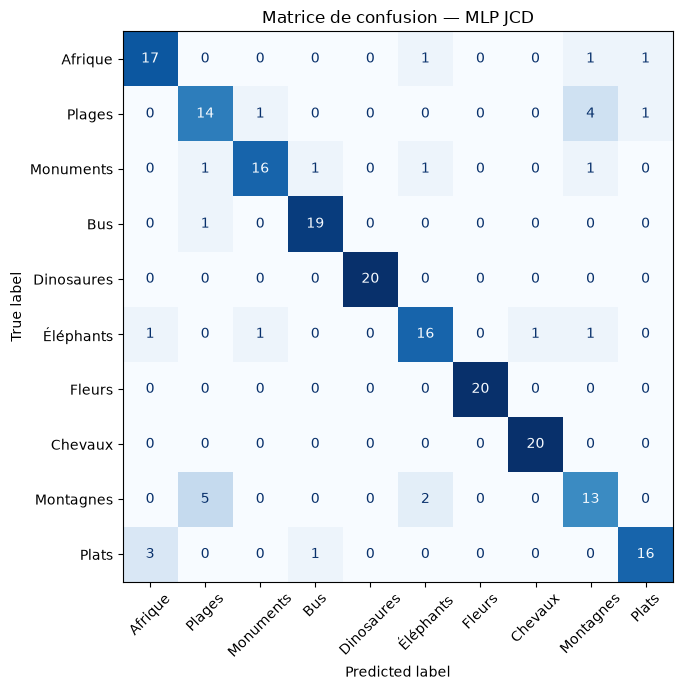

  [sauvegardé] figures/fig_037.pdf / .png


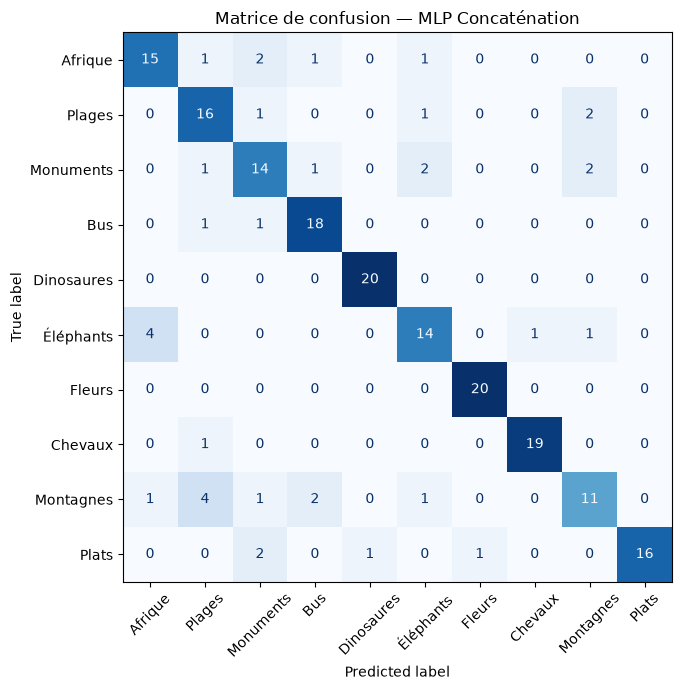

In [38]:
# Noms des 10 classes de la base Wang (numéro d'image // 100)
CLASSES = ["Afrique", "Plages", "Monuments", "Bus", "Dinosaures",
           "Éléphants", "Fleurs", "Chevaux", "Montagnes", "Plats"]


def afficher_matrice_classes(y_true, y_pred, titre):
    cm_noms = confusion_matrix(y_true, y_pred, labels=np.arange(10))
    fig, ax = plt.subplots(figsize=(8, 7))
    ConfusionMatrixDisplay(cm_noms, display_labels=CLASSES).plot(
        ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45
    )
    ax.set_title(titre)
    plt.tight_layout()
    plt.show()
    return cm_noms


# Prédictions des MLP déjà entraînés (cellule de la section 2.1)
predictions_mlp_test = {}
for nom in ["JCD", "Concaténation"]:
    predictions_mlp_test[nom] = np.argmax(
        modeles_mlp[nom].predict(X_test_descripteurs[nom], verbose=0), axis=1
    )
    afficher_matrice_classes(
        y_test, predictions_mlp_test[nom], f"Matrice de confusion — MLP {nom}"
    )

### Nuage de points des images de test (descripteurs concaténés)

Pour visualiser les 200 images de test dans un plan, nous projetons leurs descripteurs concaténés en 2 dimensions, d'abord par **ACP** (projection linéaire ajustée sur l'apprentissage), puis par **t-SNE** (projection non linéaire qui conserve les voisinages). Chaque point est coloré par sa classe réelle ; les croix noires indiquent les images mal classées par le MLP.

  [sauvegardé] figures/fig_038.pdf / .png


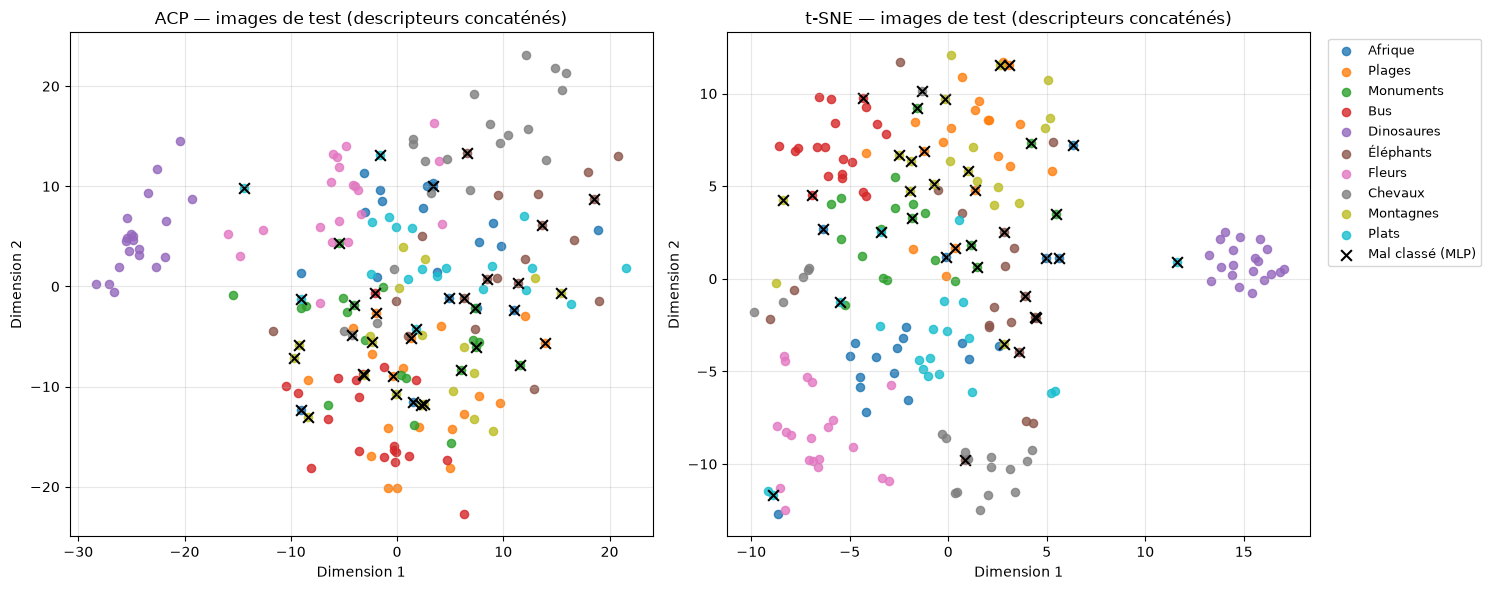

In [39]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

Xtr_conc = X_train_descripteurs["Concaténation"]
Xte_conc = X_test_descripteurs["Concaténation"]

# Images de test mal classées par le MLP (concaténation)
erreurs_mlp_conc = predictions_mlp_test["Concaténation"] != y_test

# --- Projection ACP (ajustée sur l'apprentissage, appliquée au test) ---
proj_acp = PCA(n_components=2, random_state=42).fit(Xtr_conc).transform(Xte_conc)

# --- Projection t-SNE sur les points de test ---
proj_tsne_desc = TSNE(
    n_components=2, perplexity=30, random_state=42,
    init="pca", learning_rate="auto"
).fit_transform(Xte_conc)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, proj_2d, titre in [(axes[0], proj_acp, "ACP"),
                           (axes[1], proj_tsne_desc, "t-SNE")]:
    for c in range(10):
        masque = y_test == c
        ax.scatter(proj_2d[masque, 0], proj_2d[masque, 1],
                   s=35, alpha=0.8, label=CLASSES[c])
    ax.scatter(proj_2d[erreurs_mlp_conc, 0], proj_2d[erreurs_mlp_conc, 1],
               marker="x", c="black", s=60, linewidths=1.5,
               label="Mal classé (MLP)")
    ax.set_title(f"{titre} — images de test (descripteurs concaténés)")
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")
    ax.grid(alpha=0.3)

axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

### Comparer avec les k plus proches voisins (KppV)

On comparer le **MLP** à un classifieur KppV, en optimisant le nombre de voisins **\(k\)** et la distance par validation croisée. Nous utilisons une recherche par `validation croisée` sur les données d’apprentissage uniquement, puis évaluons le meilleur modèle sur le test.

In [40]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

parametres_knn = {
    "knn__n_neighbors": [1, 3, 5, 7, 9, 11, 15],
    "knn__metric": ["euclidean", "manhattan"]
}

resultats_knn = []
modeles_knn = {}

for nom, Xtr in X_train_descripteurs.items():
    print(f"\n--- KppV : {nom} ---")

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier())
    ])

    recherche = GridSearchCV(
        pipeline,
        param_grid=parametres_knn,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    recherche.fit(
        X_descripteurs[nom][idx_train]
        if nom != "Concaténation"
        else np.concatenate(
            [X_descripteurs[d][idx_train] for d in descripteurs],
            axis=1
        ),
        y_train
    )

    # Évaluer le meilleur modèle sur les données de test correspondantes
    Xte_brut = (
        X_descripteurs[nom][idx_test]
        if nom != "Concaténation"
        else np.concatenate(
            [X_descripteurs[d][idx_test] for d in descripteurs],
            axis=1
        )
    )

    y_pred = recherche.predict(Xte_brut)
    accuracy = accuracy_score(y_test, y_pred)

    modeles_knn[nom] = recherche.best_estimator_

    resultats_knn.append({
        "Descripteur": nom,
        "Meilleurs paramètres": recherche.best_params_,
        "Accuracy CV": recherche.best_score_,
        "Accuracy test": accuracy,
        "Taux d'erreur": 1 - accuracy
    })

    print("Meilleurs paramètres :", recherche.best_params_)
    print(f"Accuracy validation croisée : {recherche.best_score_:.4f}")
    print(f"Accuracy test : {accuracy:.4f}")

tableau_knn = pd.DataFrame(resultats_knn)
display(tableau_knn.sort_values("Accuracy test", ascending=False))



--- KppV : JCD ---
Meilleurs paramètres : {'knn__metric': 'euclidean', 'knn__n_neighbors': 7}
Accuracy validation croisée : 0.7750
Accuracy test : 0.7500

--- KppV : PHOG ---
Meilleurs paramètres : {'knn__metric': 'manhattan', 'knn__n_neighbors': 1}
Accuracy validation croisée : 0.5700
Accuracy test : 0.5100

--- KppV : CEDD ---
Meilleurs paramètres : {'knn__metric': 'euclidean', 'knn__n_neighbors': 5}
Accuracy validation croisée : 0.7638
Accuracy test : 0.7750

--- KppV : FCTH ---
Meilleurs paramètres : {'knn__metric': 'manhattan', 'knn__n_neighbors': 5}
Accuracy validation croisée : 0.7537
Accuracy test : 0.7350

--- KppV : FuzzyColorHistogram ---
Meilleurs paramètres : {'knn__metric': 'euclidean', 'knn__n_neighbors': 1}
Accuracy validation croisée : 0.6613
Accuracy test : 0.6300

--- KppV : Concaténation ---
Meilleurs paramètres : {'knn__metric': 'manhattan', 'knn__n_neighbors': 11}
Accuracy validation croisée : 0.8287
Accuracy test : 0.8150


,Descripteur,Meilleurs paramètres,Accuracy CV,Accuracy test,Taux d'erreur
5,Concaténation,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.82875,0.815,0.185
2,CEDD,"{'knn__metric': 'euclidean', 'knn__n_neighbors...",0.76375,0.775,0.225
0,JCD,"{'knn__metric': 'euclidean', 'knn__n_neighbors...",0.77500,0.750,0.250
3,FCTH,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.75375,0.735,0.265
4,FuzzyColorHistogram,"{'knn__metric': 'euclidean', 'knn__n_neighbors...",0.66125,0.630,0.370
1,PHOG,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.57000,0.510,0.490


,Descripteur,Accuracy MLP,Taux d'erreur,Accuracy KppV
0,JCD,0.855,0.145,0.750
1,PHOG,0.605,0.395,0.510
2,CEDD,0.830,0.170,0.775
3,FCTH,0.755,0.245,0.735
4,FuzzyColorHistogram,0.770,0.230,0.630
5,Concaténation,0.815,0.185,0.815


  [sauvegardé] figures/fig_039.pdf / .png


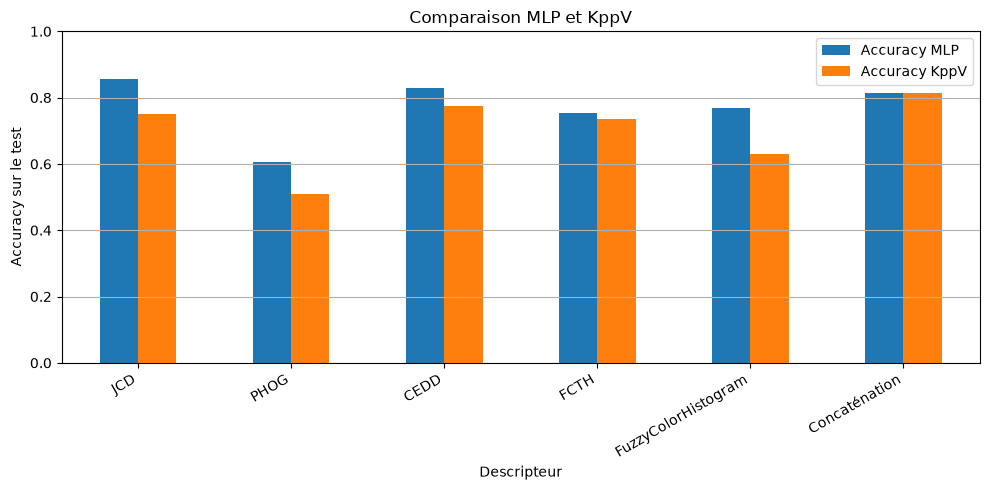

In [41]:

comparaison = tableau_mlp.merge(
    tableau_knn[["Descripteur", "Accuracy test"]],
    on="Descripteur",
    suffixes=("_MLP", "_KppV")
)

comparaison = comparaison.rename(columns={
    "Accuracy test_MLP": "Accuracy MLP",
    "Accuracy test_KppV": "Accuracy KppV"
})

display(comparaison)

comparaison.plot(
    x="Descripteur",
    y=["Accuracy MLP", "Accuracy KppV"],
    kind="bar",
    figsize=(10, 5)
)

plt.ylabel("Accuracy sur le test")
plt.ylim(0, 1)
plt.title("Comparaison MLP et KppV")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()


### KppV avec pondération des voisins

La recherche précédente ne faisait varier que $k$ et la distance. Nous ajoutons ici l'hyperparamètre `weights` : avec `uniform`, tous les voisins comptent de la même façon ; avec `distance`, les voisins proches ont plus de poids dans le vote. La recherche par validation croisée reste faite sur l'apprentissage uniquement, et le test sert à l'évaluation finale. Nous comparons ensuite les trois classifieurs (MLP, KppV simple, KppV pondéré).

JCD                    | CV = 0.7813 | test = 0.7500 | {'knn__metric': 'euclidean', 'knn__n_neighbors': 7, 'knn__weights': 'distance'}
PHOG                   | CV = 0.5813 | test = 0.5200 | {'knn__metric': 'manhattan', 'knn__n_neighbors': 3, 'knn__weights': 'distance'}
CEDD                   | CV = 0.7787 | test = 0.8050 | {'knn__metric': 'manhattan', 'knn__n_neighbors': 5, 'knn__weights': 'distance'}
FCTH                   | CV = 0.7700 | test = 0.7400 | {'knn__metric': 'manhattan', 'knn__n_neighbors': 5, 'knn__weights': 'distance'}
FuzzyColorHistogram    | CV = 0.6613 | test = 0.6300 | {'knn__metric': 'euclidean', 'knn__n_neighbors': 1, 'knn__weights': 'uniform'}
Concaténation          | CV = 0.8412 | test = 0.8250 | {'knn__metric': 'manhattan', 'knn__n_neighbors': 11, 'knn__weights': 'distance'}


,Descripteur,Meilleurs paramètres,Accuracy CV,Accuracy test,Taux d'erreur
5,Concaténation,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.84125,0.825,0.175
2,CEDD,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.77875,0.805,0.195
0,JCD,"{'knn__metric': 'euclidean', 'knn__n_neighbors...",0.78125,0.750,0.250
3,FCTH,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.77000,0.740,0.260
4,FuzzyColorHistogram,"{'knn__metric': 'euclidean', 'knn__n_neighbors...",0.66125,0.630,0.370
1,PHOG,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.58125,0.520,0.480


,Descripteur,MLP,"KppV (k, distance)",KppV (+ weights)
0,JCD,0.855,0.750,0.750
1,PHOG,0.605,0.510,0.520
2,CEDD,0.830,0.775,0.805
3,FCTH,0.755,0.735,0.740
4,FuzzyColorHistogram,0.770,0.630,0.630
5,Concaténation,0.815,0.815,0.825


  [sauvegardé] figures/fig_040.pdf / .png


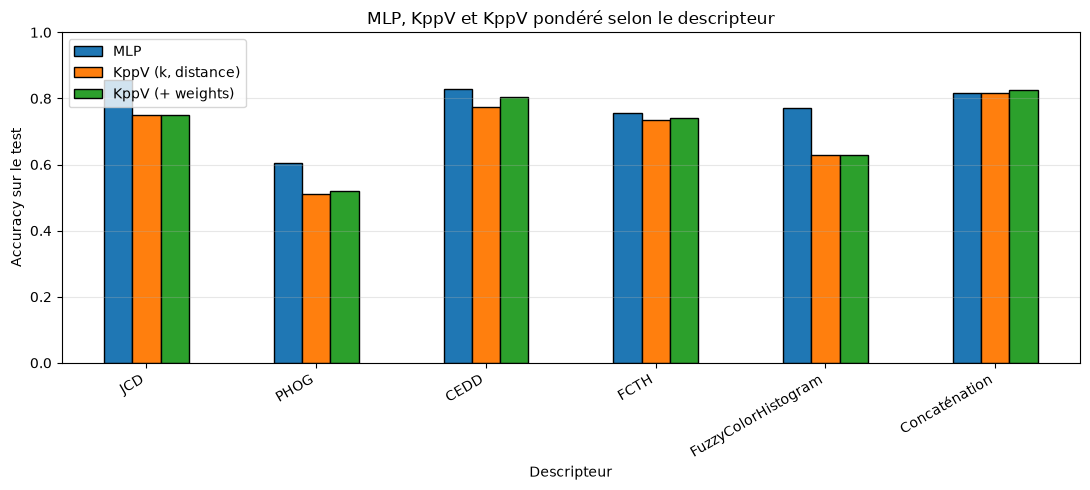

In [42]:
parametres_knn_poids = {
    "knn__n_neighbors": [1, 3, 5, 7, 9, 11, 15],
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"]
}

cv_poids = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


def donnees_brutes(nom, indices):
    # Descripteur brut (ou concaténation des descripteurs bruts) pour les indices donnés
    if nom == "Concaténation":
        return np.concatenate([X_descripteurs[d][indices] for d in descripteurs], axis=1)
    return X_descripteurs[nom][indices]


resultats_knn_poids = []

for nom in X_train_descripteurs:
    pipeline_poids = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier())
    ])

    recherche_poids = GridSearchCV(
        pipeline_poids,
        param_grid=parametres_knn_poids,
        cv=cv_poids,
        scoring="accuracy",
        n_jobs=-1
    )
    recherche_poids.fit(donnees_brutes(nom, idx_train), y_train)

    y_pred_poids = recherche_poids.predict(donnees_brutes(nom, idx_test))
    acc_poids = accuracy_score(y_test, y_pred_poids)

    resultats_knn_poids.append({
        "Descripteur": nom,
        "Meilleurs paramètres": recherche_poids.best_params_,
        "Accuracy CV": recherche_poids.best_score_,
        "Accuracy test": acc_poids,
        "Taux d'erreur": 1 - acc_poids
    })

    print(f"{nom:<22} | CV = {recherche_poids.best_score_:.4f} | "
          f"test = {acc_poids:.4f} | {recherche_poids.best_params_}")

tableau_knn_poids = pd.DataFrame(resultats_knn_poids)
display(tableau_knn_poids.sort_values("Accuracy test", ascending=False))

# Comparaison MLP / KppV simple / KppV pondéré
comparaison_trois = (
    tableau_mlp[["Descripteur", "Accuracy test"]].rename(columns={"Accuracy test": "MLP"})
    .merge(tableau_knn[["Descripteur", "Accuracy test"]]
           .rename(columns={"Accuracy test": "KppV (k, distance)"}), on="Descripteur")
    .merge(tableau_knn_poids[["Descripteur", "Accuracy test"]]
           .rename(columns={"Accuracy test": "KppV (+ weights)"}), on="Descripteur")
)

display(comparaison_trois)

comparaison_trois.plot(x="Descripteur", kind="bar", figsize=(11, 5), edgecolor="k")
plt.ylabel("Accuracy sur le test")
plt.ylim(0, 1)
plt.title("MLP, KppV et KppV pondéré selon le descripteur")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 2.2 Approche profonde : apprentissage des descripteurs

Nous chargeons les images de la base `Wang` à partir de leurs noms (0.jpg à 999.jpg). Chaque image est redimensionnée à une taille commune, et sa classe est calculée à partir de son numéro. Les pixels sont normalisés entre `0` et `1`.

In [43]:

from pathlib import Path
from PIL import Image

from sklearn.model_selection import train_test_split

dossier_images = Path("Wang")
taille_image = (128, 128)  # Possibilité de passer à (256, 256)

images = []
labels_images = []

for i in range(1000):
    chemin = dossier_images / f"{i}.jpg"

    if not chemin.exists():
        raise FileNotFoundError(f"Image introuvable : {chemin}")

    with Image.open(chemin) as img:
        img = img.convert("RGB")
        img = img.resize(taille_image)
        images.append(np.asarray(img, dtype=np.float32))

    labels_images.append(i // 100)

X_images = np.array(images, dtype=np.float32) / 255.0
y_images = np.array(labels_images, dtype=np.int64)

idx_img_train, idx_img_test = train_test_split(
    np.arange(len(y_images)),
    test_size=0.20,
    random_state=42,
    stratify=y_images
)

X_img_train = X_images[idx_img_train]
X_img_test = X_images[idx_img_test]
y_img_train = y_images[idx_img_train]
y_img_test = y_images[idx_img_test]

print("Dimensions des images :", X_images.shape)
print("Images d'apprentissage :", X_img_train.shape[0])
print("Images de test :", X_img_test.shape[0])
print("Répartition des classes :", np.bincount(y_images))


Dimensions des images : (1000, 128, 128, 3)
Images d'apprentissage : 800
Images de test : 200
Répartition des classes : [100 100 100 100 100 100 100 100 100 100]


### Aperçu des images et augmentation de données

Nous associons un nom à chaque classe de la base Wang (numéro d'image // 100), puis nous affichons quelques images d'apprentissage. Nous définissons aussi une **augmentation de données** (retournement, rotation, zoom, translation, contraste). Elle ne s'applique qu'à l'apprentissage et sera utilisée dans les expériences de la section 2.3.

Correspondance classe -> nom :
  0 : Afrique
  1 : Plages
  2 : Monuments
  3 : Bus
  4 : Dinosaures
  5 : Éléphants
  6 : Fleurs
  7 : Chevaux
  8 : Montagnes
  9 : Plats
  [sauvegardé] figures/fig_041.pdf / .png


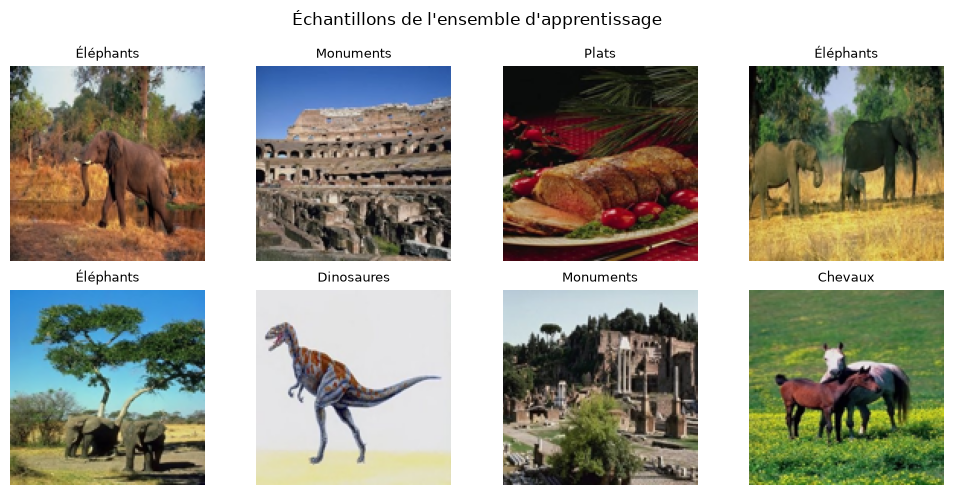

  [sauvegardé] figures/fig_042.pdf / .png


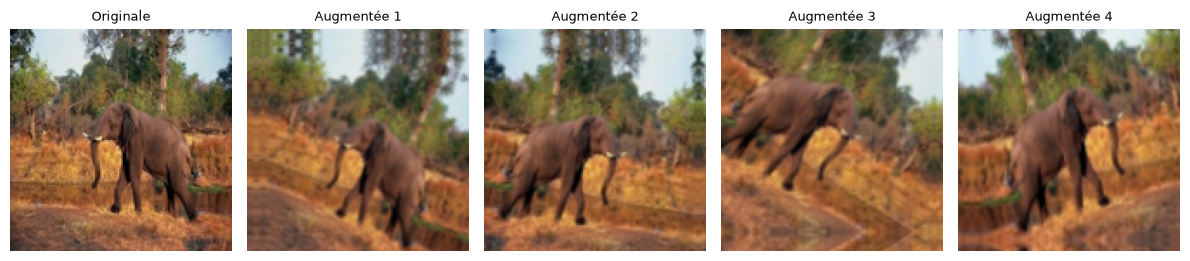

In [44]:
CLASSES = ["Afrique", "Plages", "Monuments", "Bus", "Dinosaures",
           "Éléphants", "Fleurs", "Chevaux", "Montagnes", "Plats"]

print("Correspondance classe -> nom :")
for num, nom_classe in enumerate(CLASSES):
    print(f"  {num} : {nom_classe}")

# Quelques images d'apprentissage
plt.figure(figsize=(10, 5))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(X_img_train[i])
    plt.title(CLASSES[y_img_train[i]], fontsize=9)
    plt.axis("off")
plt.suptitle("Échantillons de l'ensemble d'apprentissage")
plt.tight_layout()
plt.show()

# Augmentation de données (active uniquement lorsque training=True)
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),            # ±36°
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.1),
])

# Une image et quelques versions augmentées
exemple = X_img_train[:1]
plt.figure(figsize=(12, 3))
plt.subplot(1, 5, 1)
plt.imshow(exemple[0])
plt.title("Originale", fontsize=9)
plt.axis("off")
for k in range(4):
    version = augmentation(exemple, training=True)[0].numpy()
    plt.subplot(1, 5, k + 2)
    plt.imshow(np.clip(version, 0, 1))
    plt.title(f"Augmentée {k + 1}", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

#### Exemples d'images par classe

Pour bien comprendre la base, nous affichons plusieurs images de **chaque classe** : une ligne par classe, d'abord pour l'ensemble d'apprentissage, puis pour l'ensemble de test. Cela permet de repérer les classes visuellement proches (par exemple *Plages* et *Montagnes*) qui seront les plus difficiles à distinguer.

  [sauvegardé] figures/fig_065.pdf / .png


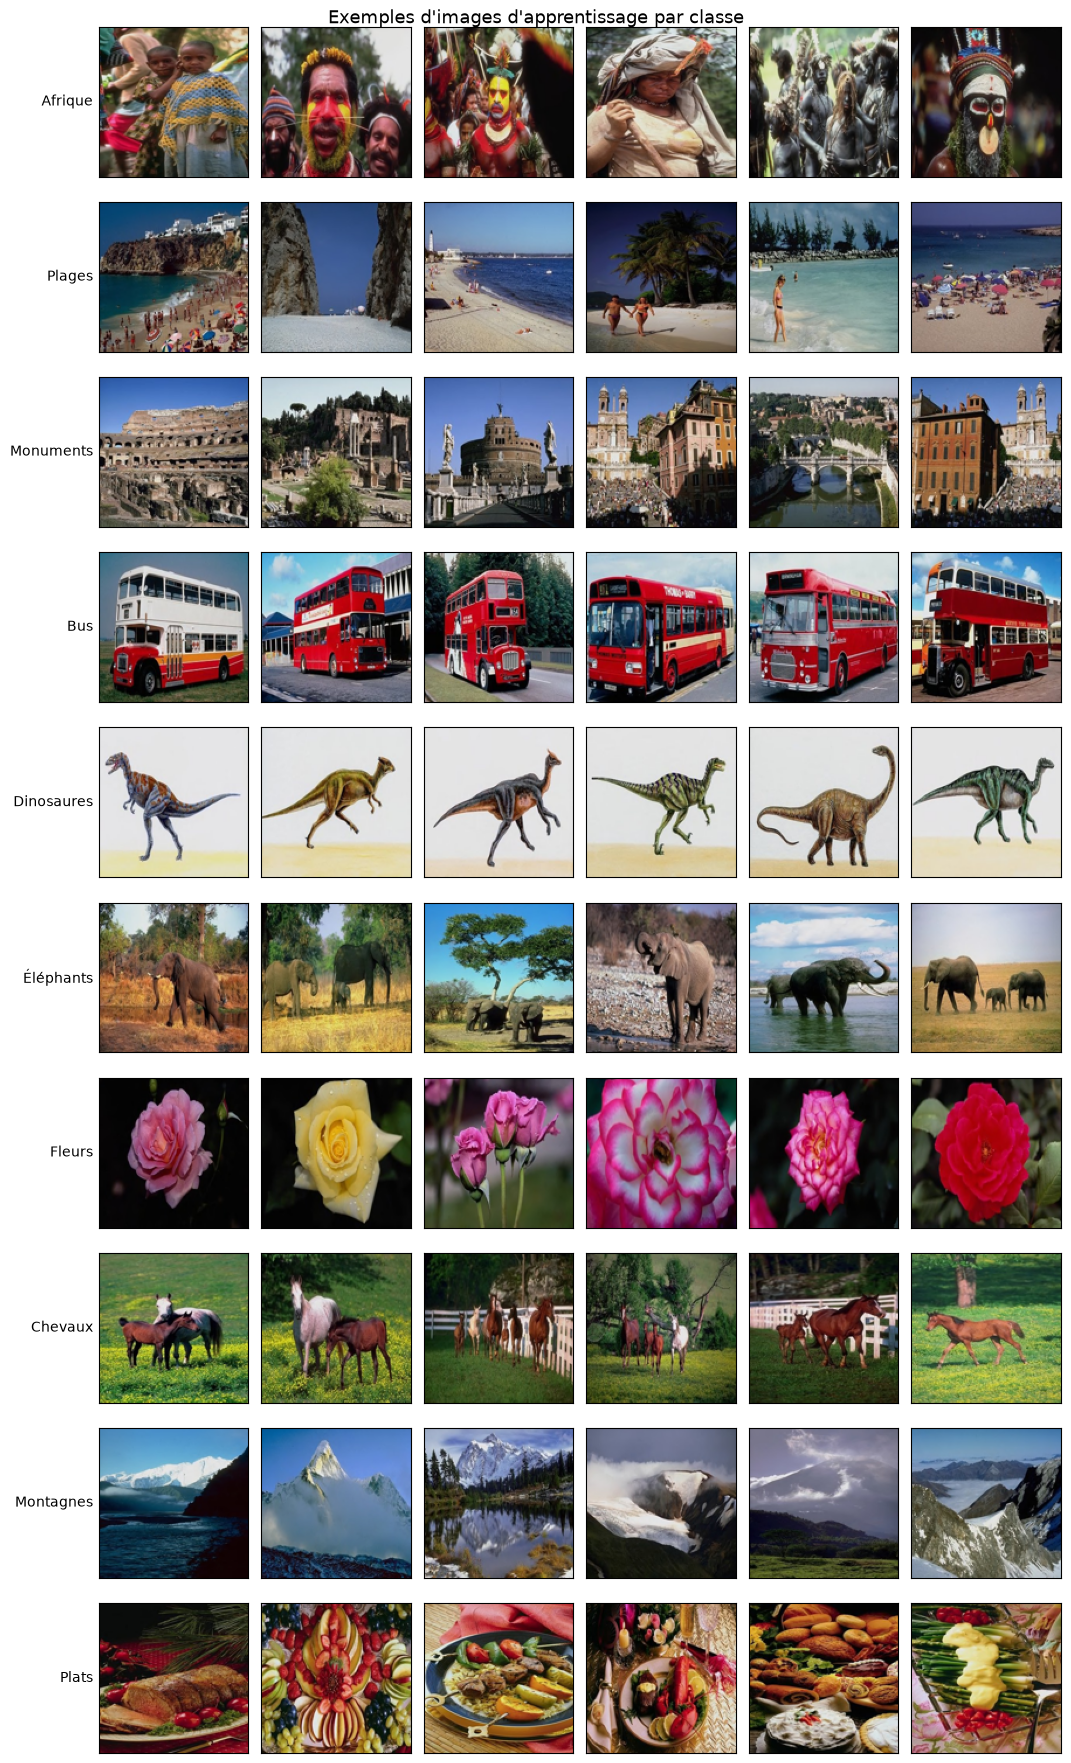

In [68]:
def afficher_images_par_classe(X, y, n_par_classe, titre):
    # Une ligne par classe, n_par_classe images par ligne
    fig, axes = plt.subplots(10, n_par_classe,
                             figsize=(1.8 * n_par_classe, 1.8 * 10))

    for c in range(10):
        indices = np.where(y == c)[0][:n_par_classe]
        for j in range(n_par_classe):
            ax = axes[c, j]
            if j < len(indices):
                ax.imshow(X[indices[j]])
            ax.set_xticks([])
            ax.set_yticks([])
            if j == 0:
                ax.set_ylabel(CLASSES[c], rotation=0, ha="right",
                              va="center", fontsize=10)

    fig.suptitle(titre, fontsize=13)
    plt.tight_layout()
    plt.show()


afficher_images_par_classe(X_img_train, y_img_train, 6,
                           "Exemples d'images d'apprentissage par classe")



### Construction d’un premier réseau convolutif (CNN)

Nous construisons une architecture simple composée de couches convolutives pour extraire les caractéristiques, de couches de sous-échantillonnage pour réduire les dimensions, puis de couches denses pour classifier les images en dix classes. Cette première architecture sert de référence avant les améliorations.

In [46]:

def creer_cnn():
    model = keras.Sequential([
        keras.Input(shape=(taille_image[1], taille_image[0], 3)),

        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(10, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


cnn = creer_cnn()
cnn.summary()


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,393,610 (28.20 MB)

 Trainable params: 7,393,610 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

### Entraînement et évaluation du CNN

Nous entraînons le réseau avec une partie des données d’apprentissage réservée à la validation. L’arrêt anticipé permet de limiter le surapprentissage. Nous évaluons ensuite le modèle sur les images de test, qui n’ont pas été utilisées pour l’entraînement.

Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 194ms/step - accuracy: 0.1875 - loss: 2.8396 - val_accuracy: 0.4000 - val_loss: 1.8413
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 174ms/step - accuracy: 0.5109 - loss: 1.4239 - val_accuracy: 0.7000 - val_loss: 1.0811
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 169ms/step - accuracy: 0.6672 - loss: 1.0077 - val_accuracy: 0.6625 - val_loss: 0.9490
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 169ms/step - accuracy: 0.7281 - loss: 0.8079 - val_accuracy: 0.6750 - val_loss: 0.9425
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 167ms/step - accuracy: 0.8234 - loss: 0.5803 - val_accuracy: 0.7375 - val_loss: 0.8293
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 166ms/step - accuracy: 0.8594 - loss: 0.4053 - val_accuracy: 0.7437 - val_loss: 0.7595
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 166ms/step - accuracy: 0.8969 - loss: 0.3141 - val_accuracy: 0.7563 - val_loss: 0.7314
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 166ms/step - accuracy: 0.9312 - loss: 0.2360 - val_accuracy: 0.

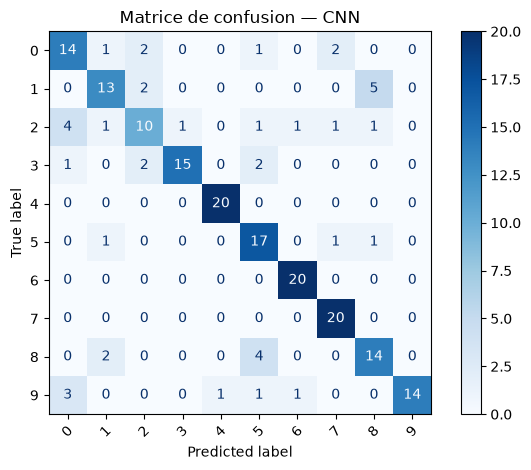

In [47]:

historique_cnn = cnn.fit(
    X_img_train,
    y_img_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True
        )
    ],
    verbose=1
)

loss_cnn, accuracy_cnn = cnn.evaluate(
    X_img_test, y_img_test, verbose=0
)

probabilites_cnn = cnn.predict(X_img_test, verbose=0)
y_pred_cnn = np.argmax(probabilites_cnn, axis=1)

print(f"Loss sur le test : {loss_cnn:.4f}")
print(f"Accuracy sur le test : {accuracy_cnn:.4f}")
print(f"Taux d'erreur : {1 - accuracy_cnn:.4f}")

print("\nRapport de classification :")
print(classification_report(
    y_img_test, y_pred_cnn, zero_division=0
))

ConfusionMatrixDisplay(
    confusion_matrix(y_img_test, y_pred_cnn),
    display_labels=np.arange(10)
).plot(cmap="Blues", xticks_rotation=45)

plt.title("Matrice de confusion — CNN")
plt.tight_layout()
plt.show()


### Analyse des courbes d’apprentissage

Nous comparons la fonction de coût et la précision sur les ensembles d’apprentissage et de validation. Une précision d’apprentissage élevée accompagnée d’une précision de validation plus faible peut révéler du surapprentissage.

  [sauvegardé] figures/fig_046.pdf / .png


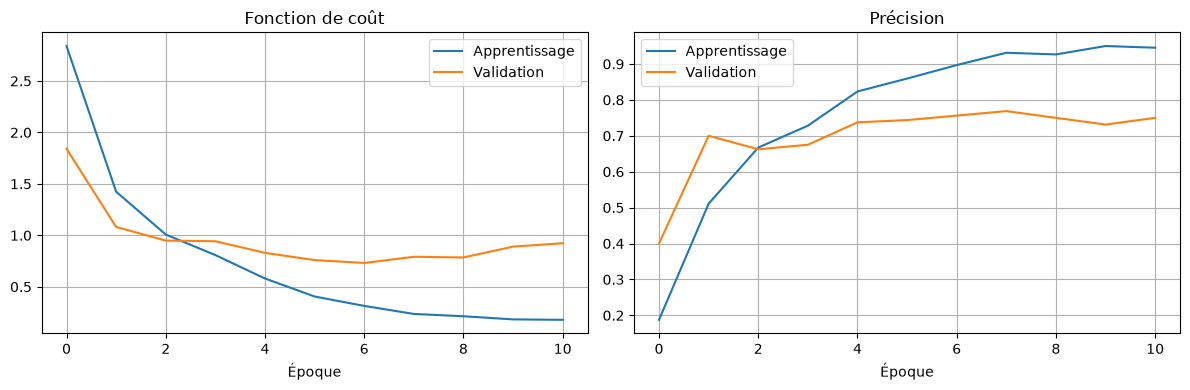

In [48]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(historique_cnn.history["loss"], label="Apprentissage")
axes[0].plot(historique_cnn.history["val_loss"], label="Validation")
axes[0].set_title("Fonction de coût")
axes[0].set_xlabel("Époque")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(historique_cnn.history["accuracy"], label="Apprentissage")
axes[1].plot(historique_cnn.history["val_accuracy"], label="Validation")
axes[1].set_title("Précision")
axes[1].set_xlabel("Époque")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


### Comparaison des approches

Nous comparons les performances obtenues avec le meilleur MLP fondé sur les descripteurs et avec le CNN qui apprend directement à partir des images.

,Approche,Accuracy test,Taux d'erreur
0,MLP — JCD,0.855,0.145
1,CNN,0.785,0.215


  [sauvegardé] figures/fig_047.pdf / .png


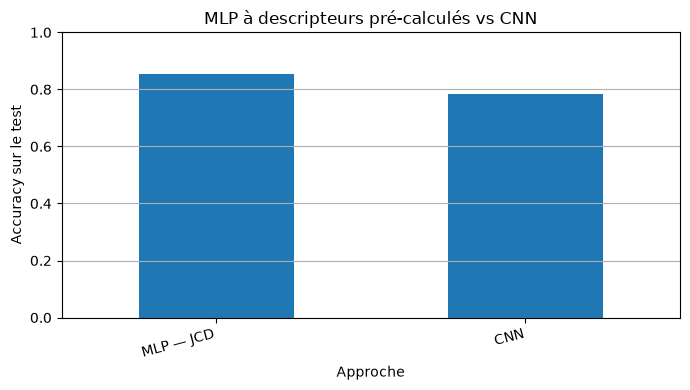

In [49]:

meilleur_mlp = tableau_mlp.loc[
    tableau_mlp["Accuracy test"].idxmax()
]

comparaison_finale = pd.DataFrame([
    {
        "Approche": f"MLP — {meilleur_mlp['Descripteur']}",
        "Accuracy test": meilleur_mlp["Accuracy test"],
        "Taux d'erreur": meilleur_mlp["Taux d'erreur"]
    },
    {
        "Approche": "CNN",
        "Accuracy test": accuracy_cnn,
        "Taux d'erreur": 1 - accuracy_cnn
    }
])

display(comparaison_finale)

comparaison_finale.plot(
    x="Approche",
    y="Accuracy test",
    kind="bar",
    legend=False,
    figsize=(7, 4)
)

plt.ylabel("Accuracy sur le test")
plt.ylim(0, 1)
plt.title("MLP à descripteurs pré-calculés vs CNN")
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()


### Transfert d’apprentissage avec VGG16

Nous utilisons VGG16 comme extracteur de caractéristiques, puis ajoutons une tête de classification adaptée aux dix classes de Wang. Cette méthode réutilise des caractéristiques apprises sur une grande base d’images.

In [50]:

from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

# VGG16 attend des images de taille compatible avec son entrée
taille_vgg = (224, 224)

def preparer_vgg(X):
    X_resize = tf.image.resize(X, taille_vgg).numpy()
    X_resize = X_resize * 255.0
    return preprocess_input(X_resize)

X_vgg_train = preparer_vgg(X_img_train)
X_vgg_test = preparer_vgg(X_img_test)

base_vgg = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Geler les poids pré-entraînés pour commencer
base_vgg.trainable = False

entree = keras.Input(shape=(224, 224, 3))
caracteristiques = base_vgg(entree, training=False)
caracteristiques = layers.GlobalAveragePooling2D()(caracteristiques)
caracteristiques = layers.Dense(128, activation="relu")(caracteristiques)
caracteristiques = layers.Dropout(0.4)(caracteristiques)
sortie = layers.Dense(10, activation="softmax")(caracteristiques)

model_vgg = keras.Model(entree, sortie)

model_vgg.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_vgg.summary()


Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,781,642 (56.39 MB)

 Trainable params: 66,954 (261.54 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

### Entraînement et évaluation

Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 69s 2s/step - accuracy: 0.5609 - loss: 2.4016 - val_accuracy: 0.9250 - val_loss: 0.2212
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 66s 2s/step - accuracy: 0.8984 - loss: 0.3089 - val_accuracy: 0.9563 - val_loss: 0.1422
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 67s 2s/step - accuracy: 0.9453 - loss: 0.1810 - val_accuracy: 0.9625 - val_loss: 0.1086
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 66s 2s/step - accuracy: 0.9609 - loss: 0.1205 - val_accuracy: 0.9812 - val_loss: 0.0791
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 66s 2s/step - accuracy: 0.9672 - loss: 0.0861 - val_accuracy: 0.9750 - val_loss: 0.0758
Epoch 6/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 64s 2s/step - accuracy: 0.9781 - loss: 0.0505 - val_accuracy: 0.9812 - val_loss: 0.0765
Epoch 7/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 67s 2s/step - accuracy: 0.9875 - loss: 0.0425 - val_accuracy: 0.9812 - val_loss: 0.0827
Epoch 8/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 66s 2s/step - accuracy: 0.9937 - loss: 0.0203 - val_accuracy: 0.9812 - val_loss:

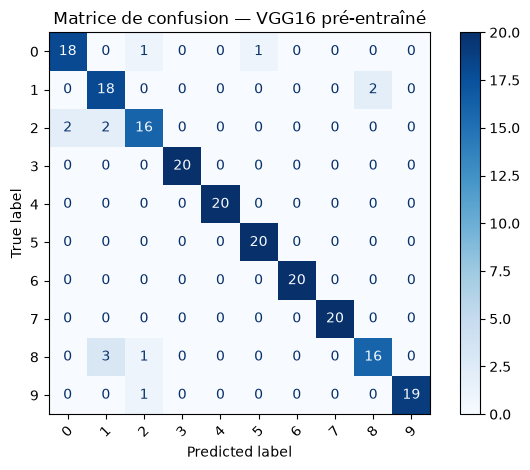

In [51]:

historique_vgg = model_vgg.fit(
    X_vgg_train,
    y_img_train,
    epochs=10,
    batch_size=16,
    validation_split=0.2,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ],
    verbose=1
)

loss_vgg, accuracy_vgg = model_vgg.evaluate(
    X_vgg_test, y_img_test, verbose=0
)

y_pred_vgg = np.argmax(
    model_vgg.predict(X_vgg_test, verbose=0),
    axis=1
)

print(f"Accuracy VGG16 sur le test : {accuracy_vgg:.4f}")
print(f"Taux d'erreur : {1 - accuracy_vgg:.4f}")

ConfusionMatrixDisplay(
    confusion_matrix(y_img_test, y_pred_vgg),
    display_labels=np.arange(10)
).plot(cmap="Blues", xticks_rotation=45)

plt.title("Matrice de confusion — VGG16 pré-entraîné")
plt.tight_layout()
plt.show()


### Fine-tuning de VGG16

Jusqu'ici, les couches convolutives de VGG16 étaient gelées. Nous dégelons maintenant les derniers blocs (à partir de `block4_conv1`) et poursuivons l'entraînement avec un taux d'apprentissage très faible ($10^{-5}$), pour adapter les caractéristiques d'`ImageNet` à la base Wang sans détruire les poids pré-entraînés.

Les variables du VGG16 gelé (`accuracy_vgg`, `y_pred_vgg`) ne sont pas modifiées : le fine-tuning utilise des variables distinctes (`accuracy_vgg_ft`, `y_pred_vgg_ft`). Le modèle `model_vgg` devient en revanche le modèle fine-tuné.

Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 127s 3s/step - accuracy: 0.9781 - loss: 0.0790 - val_accuracy: 0.9625 - val_loss: 0.1575 - learning_rate: 1.0000e-05
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 117s 3s/step - accuracy: 0.9875 - loss: 0.0446 - val_accuracy: 0.9625 - val_loss: 0.1183 - learning_rate: 1.0000e-05
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 118s 3s/step - accuracy: 0.9844 - loss: 0.0364 - val_accuracy: 0.9750 - val_loss: 0.1033 - learning_rate: 1.0000e-05
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 115s 3s/step - accuracy: 0.9937 - loss: 0.0219 - val_accuracy: 0.9750 - val_loss: 0.0930 - learning_rate: 1.0000e-05
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 121s 3s/step - accuracy: 0.9937 - loss: 0.0157 - val_accuracy: 0.9812 - val_loss: 0.0690 - learning_rate: 1.0000e-05
Epoch 6/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 119s 3s/step - accuracy: 0.9969 - loss: 0.0181 - val_accuracy: 0.9750 - val_loss: 0.1427 - learning_rate: 1.0000e-05
Epoch 7/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 120s 3s/step - accuracy: 0.9922 

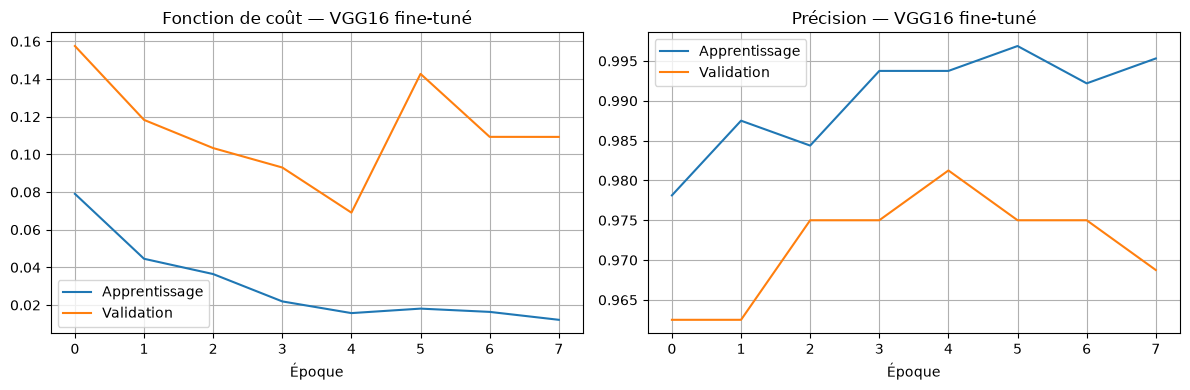

  [sauvegardé] figures/fig_050.pdf / .png


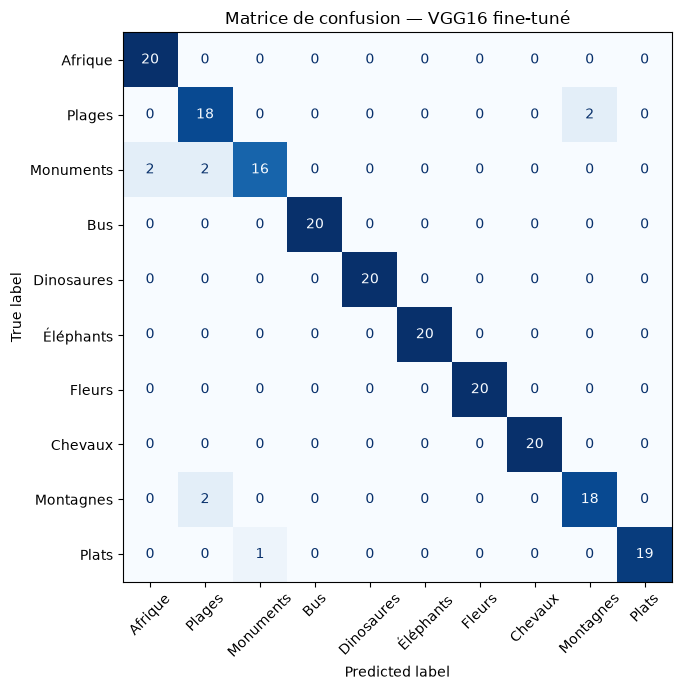

In [52]:
# Dictionnaire qui recueillera les résultats des expériences complémentaires
resultats_supplementaires = {}


def tracer_courbes(hist, titre):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(hist.history["loss"], label="Apprentissage")
    axes[0].plot(hist.history["val_loss"], label="Validation")
    axes[0].set_title(f"Fonction de coût — {titre}")
    axes[0].set_xlabel("Époque")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(hist.history["accuracy"], label="Apprentissage")
    axes[1].plot(hist.history["val_accuracy"], label="Validation")
    axes[1].set_title(f"Précision — {titre}")
    axes[1].set_xlabel("Époque")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()


# Dégeler uniquement les derniers blocs de VGG16
base_vgg.trainable = True
FINE_TUNE_FROM = "block4_conv1"
set_trainable = False
for couche in base_vgg.layers:
    if couche.name == FINE_TUNE_FROM:
        set_trainable = True
    couche.trainable = set_trainable

# Taux d'apprentissage très faible pour ne pas casser les poids ImageNet
model_vgg.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

historique_vgg_ft = model_vgg.fit(
    X_vgg_train,
    y_img_train,
    epochs=10,
    batch_size=16,
    validation_split=0.2,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-7
        )
    ],
    verbose=1
)

loss_vgg_ft, accuracy_vgg_ft = model_vgg.evaluate(
    X_vgg_test, y_img_test, verbose=0
)
y_pred_vgg_ft = np.argmax(model_vgg.predict(X_vgg_test, verbose=0), axis=1)

resultats_supplementaires["VGG16 — fine-tuning"] = float(accuracy_vgg_ft)

print(f"Accuracy VGG16 gelé       : {accuracy_vgg:.4f}")
print(f"Accuracy VGG16 fine-tuné  : {accuracy_vgg_ft:.4f}")
print(f"Taux d'erreur (fine-tuné) : {1 - accuracy_vgg_ft:.4f}")

tracer_courbes(historique_vgg_ft, "VGG16 fine-tuné")

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(
    confusion_matrix(y_img_test, y_pred_vgg_ft),
    display_labels=CLASSES
).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
ax.set_title("Matrice de confusion — VGG16 fine-tuné")
plt.tight_layout()
plt.show()

### Entraînement de ResNet50 et EfficientNetB0

Nous utilisons les poids pré-entraînés sur `ImageNet`, gelons les couches convolutives et ajoutons une tête de classification à dix classes. Les deux modèles sont entraînés sur le même ensemble d’apprentissage et évalués sur le même ensemble de test.

In [53]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50, EfficientNetB0
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)
import time
import gc

TAILLE_MODELE = (224, 224)

# Les données images doivent déjà être normalisées entre 0 et 1.
def preparer_images_transfer(X, nom_modele):
    X_resize = tf.image.resize(X, TAILLE_MODELE).numpy()
    X_resize = X_resize * 255.0

    if nom_modele == "ResNet50":
        return resnet_preprocess(X_resize)

    elif nom_modele == "EfficientNetB0":
        # EfficientNetB0 intègre le prétraitement des pixels dans le modèle.
        return X_resize

    else:
        raise ValueError("Modèle non pris en charge")


def creer_modele_transfer(constructeur):
    base = constructeur(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3),
        pooling="avg"
    )
    base.trainable = False

    entree = keras.Input(shape=(224, 224, 3))
    caracteristiques = base(entree, training=False)
    x = layers.Dense(128, activation="relu")(caracteristiques)
    x = layers.Dropout(0.3)(x)
    sortie = layers.Dense(10, activation="softmax")(x)

    model = keras.Model(entree, sortie)
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model



Entraînement de ResNet50

Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 37s 800ms/step - accuracy: 0.8125 - loss: 0.6011 - val_accuracy: 0.9750 - val_loss: 0.0902
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 29s 733ms/step - accuracy: 0.9766 - loss: 0.0655 - val_accuracy: 0.9750 - val_loss: 0.0942
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 30s 736ms/step - accuracy: 0.9953 - loss: 0.0211 - val_accuracy: 0.9688 - val_loss: 0.0910
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 29s 729ms/step - accuracy: 0.9922 - loss: 0.0278 - val_accuracy: 0.9688 - val_loss: 0.0975

Accuracy : 0.9550
Taux d'erreur : 0.0450
Temps d'entraînement : 125.7 secondes
              precision    recall  f1-score   support

           0       0.95      0.90      0.92        20
           1       0.83      0.95      0.88        20
           2       0.86      0.90      0.88        20
           3       1.00      0.95      0.97        20
           4       1.00      1.00      1.00        20
           5       1.00      1.00      1.00        2

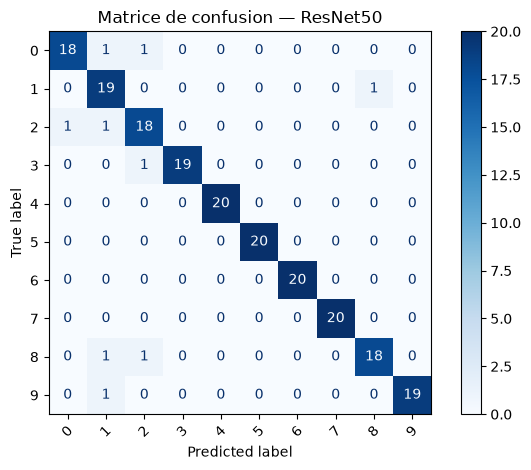


Entraînement de EfficientNetB0
Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 358ms/step - accuracy: 0.8359 - loss: 0.6473 - val_accuracy: 0.9875 - val_loss: 0.0857
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 12s 306ms/step - accuracy: 0.9906 - loss: 0.0441 - val_accuracy: 0.9875 - val_loss: 0.0679
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 12s 310ms/step - accuracy: 0.9984 - loss: 0.0188 - val_accuracy: 0.9812 - val_loss: 0.0635
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 13s 317ms/step - accuracy: 1.0000 - loss: 0.0103 - val_accuracy: 0.9812 - val_loss: 0.0585
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 12s 305ms/step - accuracy: 0.9984 - loss: 0.0098 - val_accuracy: 0.9812 - val_loss: 0.0594
Epoch 6/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 12s 304ms/step - accuracy: 1.0000 - loss: 0.0099 - val_accuracy: 0.9812 - val_loss: 0.0587
Epoch 7/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 12s 302ms/step - accuracy: 1.0000 - loss: 0.0072 - val_accuracy: 0.9812 - val_loss: 0.0607

Accuracy : 0.9650
Taux d'erreur : 0.0350
Temps d'entraînement : 

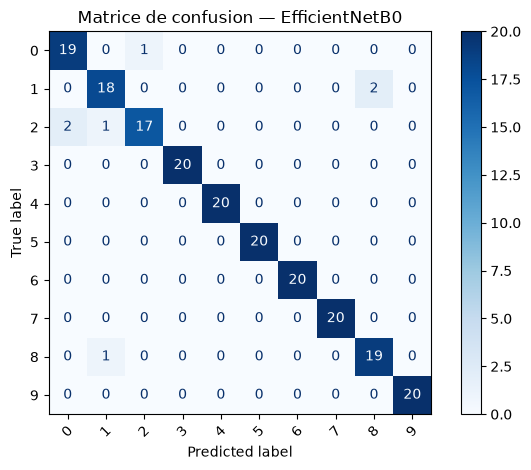

In [54]:

constructeurs = {
    "ResNet50": ResNet50,
    "EfficientNetB0": EfficientNetB0
}

resultats_nouveaux = []
modeles_nouveaux = {}
historiques_nouveaux = {}
predictions_nouveaux = {}

for nom, constructeur in constructeurs.items():
    print(f"\n{'=' * 45}\nEntraînement de {nom}\n{'=' * 45}")

    tf.keras.backend.clear_session()
    gc.collect()

    Xtr = preparer_images_transfer(X_img_train, nom)
    Xte = preparer_images_transfer(X_img_test, nom)

    model = creer_modele_transfer(constructeur)

    debut = time.time()

    historique = model.fit(
        Xtr,
        y_img_train,
        epochs=10,
        batch_size=16,
        validation_split=0.2,
        callbacks=[
            keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=3,
                restore_best_weights=True
            )
        ],
        verbose=1
    )

    temps = time.time() - debut

    probabilites = model.predict(Xte, verbose=0)
    y_pred = np.argmax(probabilites, axis=1)

    accuracy = accuracy_score(y_img_test, y_pred)

    resultats_nouveaux.append({
        "Modèle": nom,
        "Accuracy test": accuracy,
        "Taux d'erreur": 1 - accuracy,
        "Temps entraînement (s)": temps,
        "Époques effectuées": len(historique.history["loss"])
    })

    modeles_nouveaux[nom] = model
    historiques_nouveaux[nom] = historique
    predictions_nouveaux[nom] = y_pred

    print(f"\nAccuracy : {accuracy:.4f}")
    print(f"Taux d'erreur : {1 - accuracy:.4f}")
    print(f"Temps d'entraînement : {temps:.1f} secondes")
    print(classification_report(
        y_img_test, y_pred, zero_division=0
    ))

    matrice = confusion_matrix(
        y_img_test, y_pred, labels=np.arange(10)
    )

    ConfusionMatrixDisplay(
        confusion_matrix=matrice,
        display_labels=np.arange(10)
    ).plot(cmap="Blues", xticks_rotation=45)

    plt.title(f"Matrice de confusion — {nom}")
    plt.tight_layout()
    plt.show()

    del Xtr, Xte


### Comparaison entre VGG16, ResNet50 et EfficientNetB0

Nous comparons les trois réseaux pré-entraînés à partir de leur précision sur le même ensemble de test.

,Modèle,Accuracy test,Taux d'erreur
0,EfficientNetB0,0.965,0.035
1,ResNet50,0.955,0.045
2,VGG16,0.935,0.065


  [sauvegardé] figures/fig_053.pdf / .png


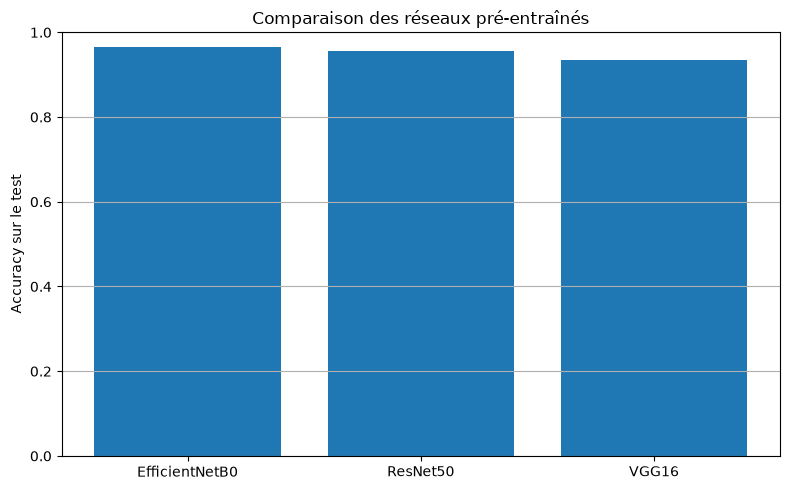

Meilleur réseau : EfficientNetB0
Accuracy : 0.9650
Taux d'erreur : 0.0350


In [55]:

# Réutiliser le résultat VGG16 déjà calculé
resultats_reseaux = [
    {
        "Modèle": "VGG16",
        "Accuracy test": float(accuracy_vgg),
        "Taux d'erreur": 1 - float(accuracy_vgg)
    }
]

# Ajouter ResNet50 et EfficientNetB0
for resultat in resultats_nouveaux:
    resultats_reseaux.append({
        "Modèle": resultat["Modèle"],
        "Accuracy test": resultat["Accuracy test"],
        "Taux d'erreur": resultat["Taux d'erreur"]
    })

# Créer et trier le tableau comparatif
tableau_reseaux = pd.DataFrame(resultats_reseaux)
tableau_reseaux = tableau_reseaux.sort_values(
    "Accuracy test", ascending=False
).reset_index(drop=True)

display(tableau_reseaux)

# Comparaison graphique
plt.figure(figsize=(8, 5))
plt.bar(
    tableau_reseaux["Modèle"],
    tableau_reseaux["Accuracy test"]
)
plt.ylim(0, 1)
plt.ylabel("Accuracy sur le test")
plt.title("Comparaison des réseaux pré-entraînés")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

# Identifier le meilleur réseau
meilleur_reseau = tableau_reseaux.iloc[0]

print("Meilleur réseau :", meilleur_reseau["Modèle"])
print(f"Accuracy : {meilleur_reseau['Accuracy test']:.4f}")
print(f"Taux d'erreur : {meilleur_reseau["Taux d'erreur"]:.4f}")


### CNN amélioré : architecture plus profonde avec augmentation

Le premier CNN de la section 2.2 est volontairement simple. Nous construisons ici une architecture plus profonde : trois étages composés de **deux convolutions** (32, 64 puis 128 filtres, `padding="same"`) suivies d'un sous-échantillonnage, puis une couche dense de 256 neurones avec `Dropout(0.5)`. L'**augmentation de données** définie plus haut est intégrée au début du modèle (active uniquement à l'apprentissage), et le callback `ReduceLROnPlateau` divise le taux d'apprentissage par 2 lorsque la validation stagne.

Comme pour les autres modèles, 20 % de l'apprentissage sert de validation interne ; le test n'est utilisé que pour l'évaluation finale.

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_7 (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,530,858 (32.54 MB)

 Trainable params: 8,530,858 (32.54 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 11s 448ms/step - accuracy: 0.1906 - loss: 2.1507 - val_accuracy: 0.3313 - val_loss: 1.9501 - learning_rate: 0.0010
Epoch 2/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 427ms/step - accuracy: 0.3562 - loss: 1.7686 - val_accuracy: 0.4688 - val_loss: 1.5352 - learning_rate: 0.0010
Epoch 3/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 430ms/step - accuracy: 0.4969 - loss: 1.5031 - val_accuracy: 0.6125 - val_loss: 1.2194 - learning_rate: 0.0010
Epoch 4/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 429ms/step - accuracy: 0.6000 - loss: 1.2365 - val_accuracy: 0.6438 - val_loss: 1.0604 - learning_rate: 0.0010
Epoch 5/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 444ms/step - accuracy: 0.6328 - loss: 1.0929 - val_accuracy: 0.6875 - val_loss: 0.9181 - learning_rate: 0.0010
Epoch 6/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 447ms/step - accuracy: 0.6906 - loss: 0.9083 - val_accuracy: 0.6938 - val_loss: 0.8976 - learning_rate: 0.0010
Epoch 7/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 449ms/step - accuracy: 0.7484 - loss: 0.7352 -

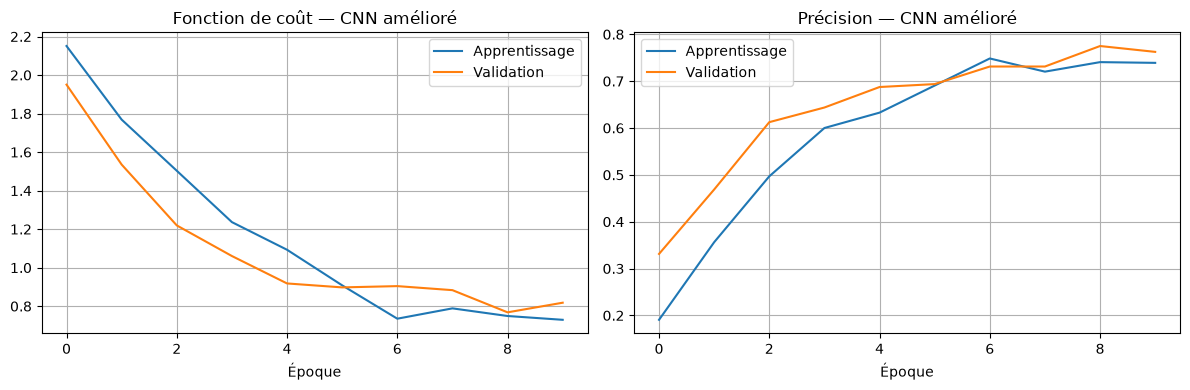

  [sauvegardé] figures/fig_055.pdf / .png


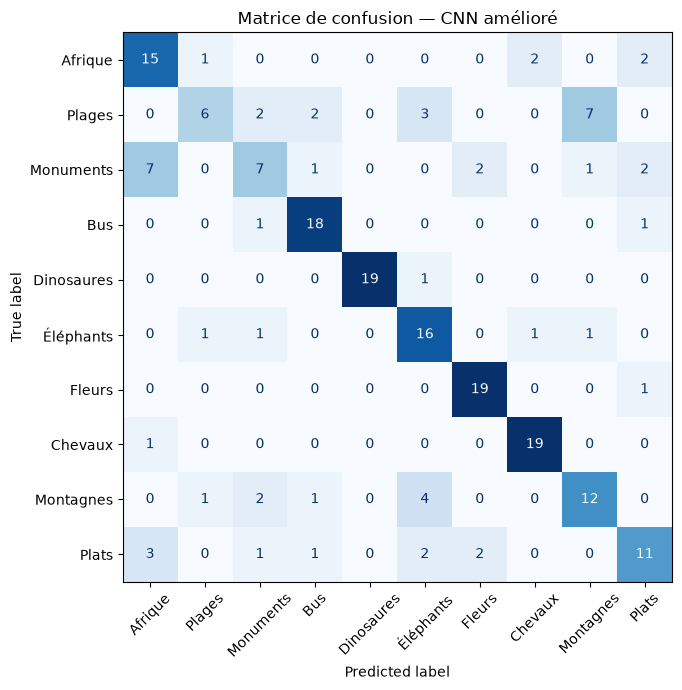

In [56]:
def creer_cnn_ameliore(avec_augmentation=True):
    entree = keras.Input(shape=(taille_image[1], taille_image[0], 3))
    x_cnn = augmentation(entree) if avec_augmentation else entree

    # Étage 1
    x_cnn = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(x_cnn)
    x_cnn = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(x_cnn)
    x_cnn = layers.MaxPooling2D((2, 2))(x_cnn)

    # Étage 2
    x_cnn = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x_cnn)
    x_cnn = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x_cnn)
    x_cnn = layers.MaxPooling2D((2, 2))(x_cnn)

    # Étage 3
    x_cnn = layers.Conv2D(128, (3, 3), activation="relu", padding="same")(x_cnn)
    x_cnn = layers.MaxPooling2D((2, 2))(x_cnn)

    # Tête de classification
    x_cnn = layers.Flatten()(x_cnn)
    x_cnn = layers.Dense(256, activation="relu")(x_cnn)
    x_cnn = layers.Dropout(0.5)(x_cnn)
    sortie_cnn = layers.Dense(10, activation="softmax")(x_cnn)

    model_cnn = keras.Model(entree, sortie_cnn)
    model_cnn.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model_cnn


cnn_ameliore = creer_cnn_ameliore()
cnn_ameliore.summary()

historique_cnn_ameliore = cnn_ameliore.fit(
    X_img_train,
    y_img_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=6,
            restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=1e-5
        )
    ],
    verbose=1
)

loss_cnn_ameliore, accuracy_cnn_ameliore = cnn_ameliore.evaluate(
    X_img_test, y_img_test, verbose=0
)
y_pred_cnn_ameliore = np.argmax(cnn_ameliore.predict(X_img_test, verbose=0), axis=1)

resultats_supplementaires["CNN amélioré — augmentation + ReduceLROnPlateau"] = float(accuracy_cnn_ameliore)

print(f"\nCNN de base (section 2.2)  - Accuracy test : {accuracy_cnn:.4f}")
print(f"CNN amélioré               - Accuracy test : {accuracy_cnn_ameliore:.4f}")
print(f"Taux d'erreur (CNN amélioré) : {1 - accuracy_cnn_ameliore:.4f}")

print("\nRapport de classification :")
print(classification_report(
    y_img_test, y_pred_cnn_ameliore, target_names=CLASSES, zero_division=0
))

tracer_courbes(historique_cnn_ameliore, "CNN amélioré")

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(
    confusion_matrix(y_img_test, y_pred_cnn_ameliore, labels=np.arange(10)),
    display_labels=CLASSES
).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
ax.set_title("Matrice de confusion — CNN amélioré")
plt.tight_layout()
plt.show()

## 2.3 Approfondissements : analyses complémentaires

Cette section complète l'étude par plusieurs analyses : apport de l'augmentation de données, choix de l'optimiseur, visualisation t-SNE, analyse des confusions et robustesse aux perturbations.

Pour rester cohérentes avec le reste du notebook, toutes ces expériences utilisent le **même découpage** (`X_img_train` / `X_img_test`), une **validation interne** (`validation_split=0.2`) pour l'arrêt anticipé, et le jeu de test uniquement pour l'évaluation finale.


### Augmentation de données : gain réel ou non ?

Nous entraînons le même CNN (celui de la section 2.2) avec et sans augmentation de données (définie plus haut), puis nous comparons les courbes de validation et la précision sur le test. L'augmentation est intégrée au modèle : elle n'est active que pendant l'apprentissage.


===== Sans augmentation =====
  -> accuracy test = 0.7150

===== Avec augmentation =====
  -> accuracy test = 0.7600
  [sauvegardé] figures/fig_056.pdf / .png


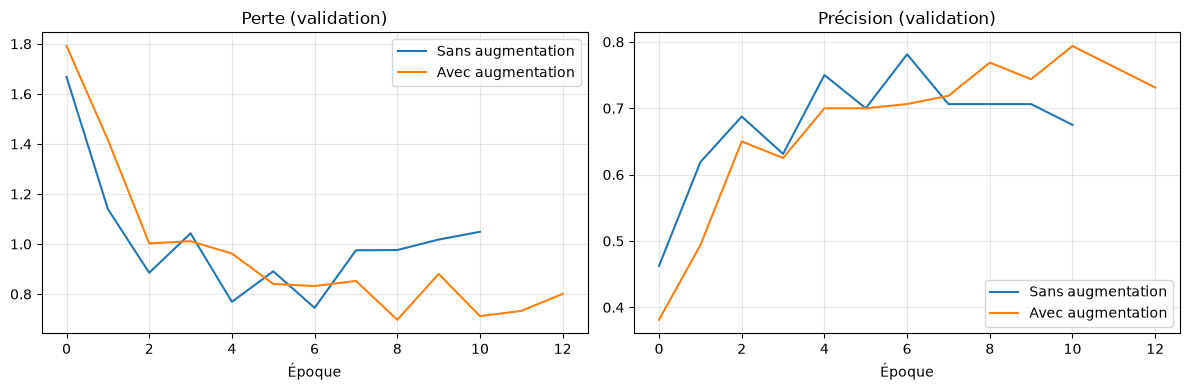

In [58]:
def creer_cnn_avec_augmentation():
    cnn_base = creer_cnn()
    entree = keras.Input(shape=(taille_image[1], taille_image[0], 3))
    x_aug = augmentation(entree)          # actif uniquement en apprentissage
    sortie = cnn_base(x_aug)
    model = keras.Model(entree, sortie)
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


histoires = {}
acc_aug = {}

for nom_exp, constructeur_modele in [("Sans augmentation", creer_cnn),
                                     ("Avec augmentation", creer_cnn_avec_augmentation)]:
    print(f"\n===== {nom_exp} =====")
    m = constructeur_modele()
    h = m.fit(
        X_img_train, y_img_train,
        epochs=20, batch_size=32, validation_split=0.2, verbose=0,
        callbacks=[keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=4, restore_best_weights=True)]
    )
    histoires[nom_exp] = h
    _, acc = m.evaluate(X_img_test, y_img_test, verbose=0)
    acc_aug[nom_exp] = float(acc)
    print(f"  -> accuracy test = {acc:.4f}")
    del m
    gc.collect()

resultats_supplementaires["CNN — avec augmentation"] = acc_aug["Avec augmentation"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for nom_exp, h in histoires.items():
    axes[0].plot(h.history["val_loss"], label=nom_exp)
    axes[1].plot(h.history["val_accuracy"], label=nom_exp)
axes[0].set_title("Perte (validation)")
axes[1].set_title("Précision (validation)")
for ax in axes:
    ax.set_xlabel("Époque")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Optimiseurs et taux d'apprentissage

Nous entraînons le CNN de la section 2.2 avec quatre configurations d'optimiseur (SGD avec momentum, Adam à deux taux d'apprentissage, RMSprop) et nous comparons l'évolution de la précision de validation.


===== SGD lr=0.01 =====
  -> accuracy test = 0.6950

===== Adam lr=1e-3 =====
  -> accuracy test = 0.7500

===== Adam lr=1e-4 =====
  -> accuracy test = 0.7400

===== RMSprop lr=1e-3 =====
  -> accuracy test = 0.7050
  [sauvegardé] figures/fig_057.pdf / .png


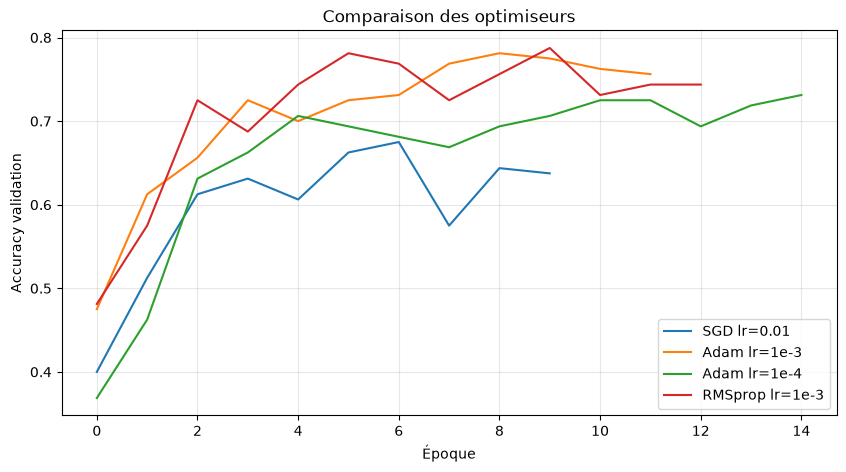

In [59]:
def faire_optimiseurs():
    return {
        "SGD lr=0.01":     keras.optimizers.SGD(0.01, momentum=0.9),
        "Adam lr=1e-3":    keras.optimizers.Adam(1e-3),
        "Adam lr=1e-4":    keras.optimizers.Adam(1e-4),
        "RMSprop lr=1e-3": keras.optimizers.RMSprop(1e-3),
    }

resultats_optims = {}
courbes_optims = {}

for nom_opt, opt in faire_optimiseurs().items():
    print(f"\n===== {nom_opt} =====")
    m = creer_cnn()
    m.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h = m.fit(
        X_img_train, y_img_train,
        epochs=15, batch_size=32, validation_split=0.2, verbose=0,
        callbacks=[keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=3, restore_best_weights=True)]
    )
    _, acc = m.evaluate(X_img_test, y_img_test, verbose=0)
    resultats_optims[nom_opt] = float(acc)
    courbes_optims[nom_opt] = h.history["val_accuracy"]
    print(f"  -> accuracy test = {acc:.4f}")
    del m
    gc.collect()

plt.figure(figsize=(10, 5))
for nom_opt, v in courbes_optims.items():
    plt.plot(v, label=nom_opt)
plt.xlabel("Époque")
plt.ylabel("Accuracy validation")
plt.title("Comparaison des optimiseurs")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Diagnostic de l'architecture de `model_vgg`

Avant d'extraire les caractéristiques du réseau pour le t-SNE, nous vérifions la liste de ses couches : cela permet de s'assurer que la couche dense utilisée est bien celle qui produit les caractéristiques (`Dense(128)` de la tête de classification).

In [60]:
print("model_vgg :", type(model_vgg).__name__)
print()
for i, couche_diag in enumerate(model_vgg.layers):
    details = ""
    if hasattr(couche_diag, "units"):
        details = f"units={couche_diag.units}"
    print(f"  [{i:>2}] {type(couche_diag).__name__:<26} "
          f"name={couche_diag.name:<30} {details}")

model_vgg : Functional

  [ 0] InputLayer                 name=input_layer_10                 
  [ 1] Functional                 name=vgg16                          
  [ 2] GlobalAveragePooling2D     name=global_average_pooling2d       
  [ 3] Dense                      name=dense_23                       units=128
  [ 4] Dropout                    name=dropout_8                      
  [ 5] Dense                      name=dense_24                       units=10


### Visualisation t-SNE des caractéristiques de VGG16

Nous projetons en 2 dimensions les caractéristiques apprises par la couche dense de `model_vgg` (après fine-tuning), pour les images de test. Si les classes forment des groupes bien séparés, le réseau a appris des représentations discriminantes.

Couche utilisée : dense_23 — (None, 128)
Forme des caractéristiques : (200, 128)
Nombre d'étiquettes : 200
  [sauvegardé] figures/fig_058.pdf / .png


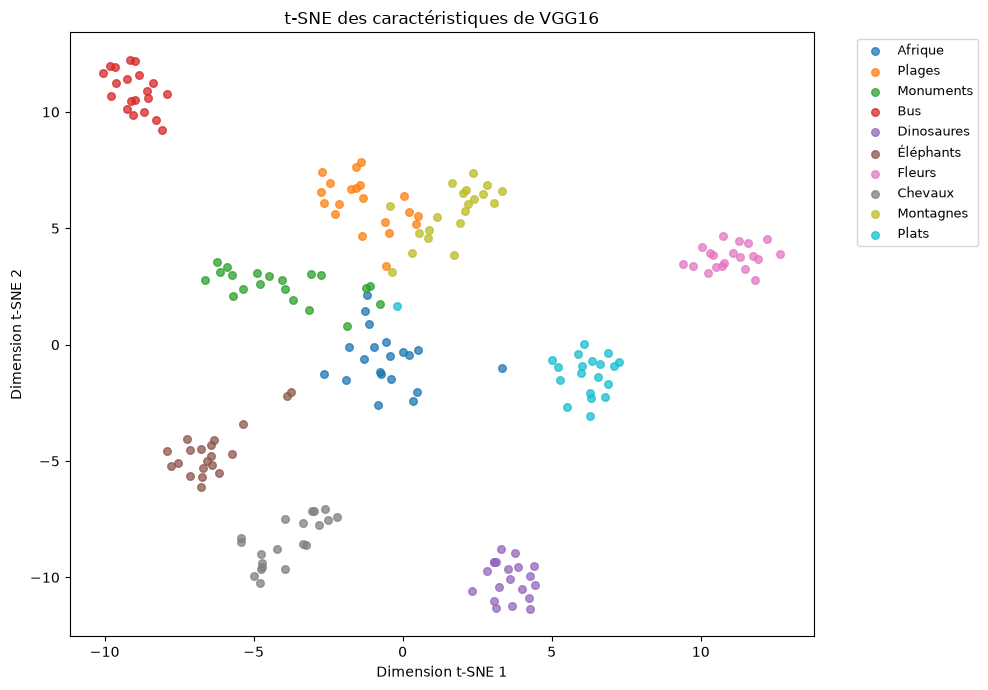

In [61]:
from sklearn.manifold import TSNE

# Couche dense qui produit les caractéristiques (première couche Dense de la tête)
couche_features = [c for c in model_vgg.layers if isinstance(c, layers.Dense)][0]
print("Couche utilisée :", couche_features.name, "—", couche_features.output.shape)

extracteur = keras.Model(inputs=model_vgg.inputs, outputs=couche_features.output)
feats = extracteur.predict(X_vgg_test, verbose=0)

print("Forme des caractéristiques :", feats.shape)
print("Nombre d'étiquettes :", len(y_img_test))

tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    init="pca",
    learning_rate="auto"
)
proj = tsne.fit_transform(feats)

plt.figure(figsize=(10, 7))
for c in range(10):
    masque = y_img_test == c
    plt.scatter(proj[masque, 0], proj[masque, 1], s=30, alpha=0.75, label=CLASSES[c])
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=9)
plt.title("t-SNE des caractéristiques de VGG16")
plt.xlabel("Dimension t-SNE 1")
plt.ylabel("Dimension t-SNE 2")
plt.tight_layout()
plt.show()

### Analyse des confusions par classe

La matrice de confusion normalisée (par ligne) donne la proportion d'images de chaque classe réelle qui sont attribuées à chaque classe prédite. Nous listons ensuite les confusions les plus fréquentes pour le VGG16 fine-tuné.

  [sauvegardé] figures/fig_059.pdf / .png


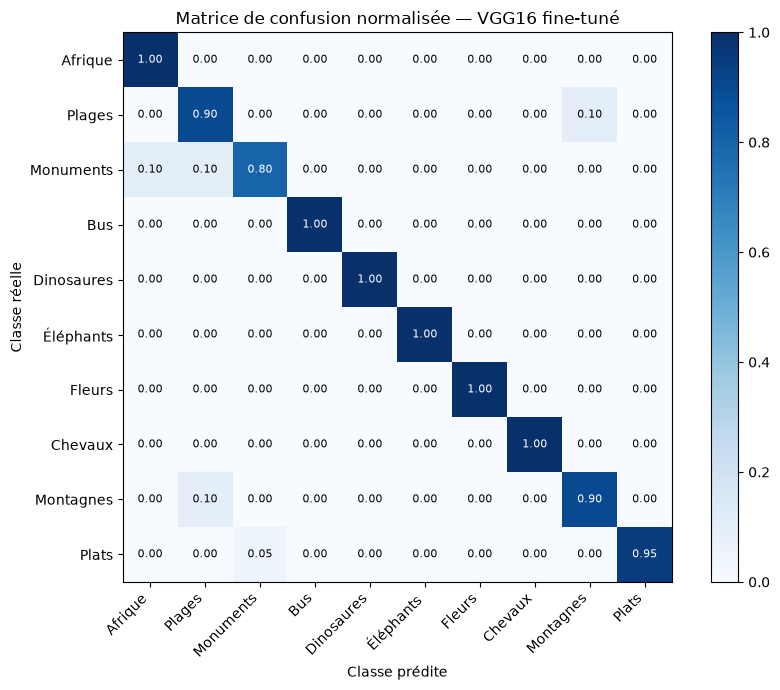

Top 10 des confusions (vrai -> prédit) :
---------------------------------------------
        Plages -> Montagnes    : 2 image(s)
     Monuments -> Plages       : 2 image(s)
     Monuments -> Afrique      : 2 image(s)
     Montagnes -> Plages       : 2 image(s)
         Plats -> Monuments    : 1 image(s)


In [62]:
cm = confusion_matrix(y_img_test, y_pred_vgg_ft, labels=np.arange(10))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(9, 7))
plt.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
plt.colorbar()
plt.xticks(range(10), CLASSES, rotation=45, ha="right")
plt.yticks(range(10), CLASSES)
for i in range(10):
    for j in range(10):
        plt.text(j, i, f"{cm_norm[i, j]:.2f}",
                 ha="center", va="center",
                 color="white" if cm_norm[i, j] > 0.5 else "black",
                 fontsize=8)
plt.title("Matrice de confusion normalisée — VGG16 fine-tuné")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.tight_layout()
plt.show()

# Top 10 des confusions (hors diagonale)
paires = []
for i in range(10):
    for j in range(10):
        if i != j and cm[i, j] > 0:
            paires.append((cm[i, j], CLASSES[i], CLASSES[j]))
paires.sort(reverse=True)

print("Top 10 des confusions (vrai -> prédit) :")
print("-" * 45)
for n, vrai, pred in paires[:10]:
    print(f"  {vrai:>12s} -> {pred:<12s} : {n} image(s)")

#### Rapport de classification et rappel par classe

Le rapport ci-dessous donne, pour le VGG16 fine-tuné, la précision, le rappel et le F1-score de chaque classe. Le diagramme montre le **rappel** (taux de reconnaissance) par classe, ce qui permet d'identifier immédiatement les thèmes les plus difficiles.

              precision    recall  f1-score   support

     Afrique       0.91      1.00      0.95        20
      Plages       0.82      0.90      0.86        20
   Monuments       0.94      0.80      0.86        20
         Bus       1.00      1.00      1.00        20
  Dinosaures       1.00      1.00      1.00        20
   Éléphants       1.00      1.00      1.00        20
      Fleurs       1.00      1.00      1.00        20
     Chevaux       1.00      1.00      1.00        20
   Montagnes       0.90      0.90      0.90        20
       Plats       1.00      0.95      0.97        20

    accuracy                           0.95       200
   macro avg       0.96      0.95      0.95       200
weighted avg       0.96      0.95      0.95       200

  [sauvegardé] figures/fig_060.pdf / .png


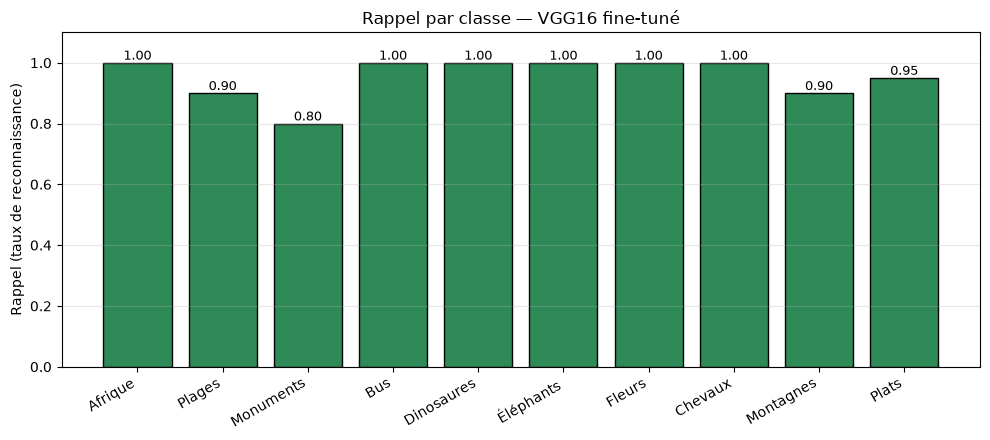

In [63]:
y_pred_ft_rapport = y_pred_vgg_ft

print(classification_report(
    y_img_test, y_pred_ft_rapport, target_names=CLASSES, zero_division=0
))

cm_rappel = confusion_matrix(y_img_test, y_pred_ft_rapport, labels=np.arange(10))
rappel_par_classe = np.diag(cm_rappel) / cm_rappel.sum(axis=1)

plt.figure(figsize=(10, 4.5))
barres = plt.bar(CLASSES, rappel_par_classe, color="seagreen", edgecolor="k")
for barre, v in zip(barres, rappel_par_classe):
    plt.text(barre.get_x() + barre.get_width() / 2, v + 0.01,
             f"{v:.2f}", ha="center", fontsize=9)
plt.ylim(0, 1.1)
plt.ylabel("Rappel (taux de reconnaissance)")
plt.title("Rappel par classe — VGG16 fine-tuné")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

#### Exemples d'images de test mal classées

Nous affichons quelques images de test que le VGG16 fine-tuné classe de façon erronée, avec la classe réelle et la classe prédite. Regarder ces erreurs aide à comprendre les confusions (images ambiguës, scènes contenant plusieurs thèmes, etc.).

Images de test mal classées : 9 / 200
  [sauvegardé] figures/fig_061.pdf / .png


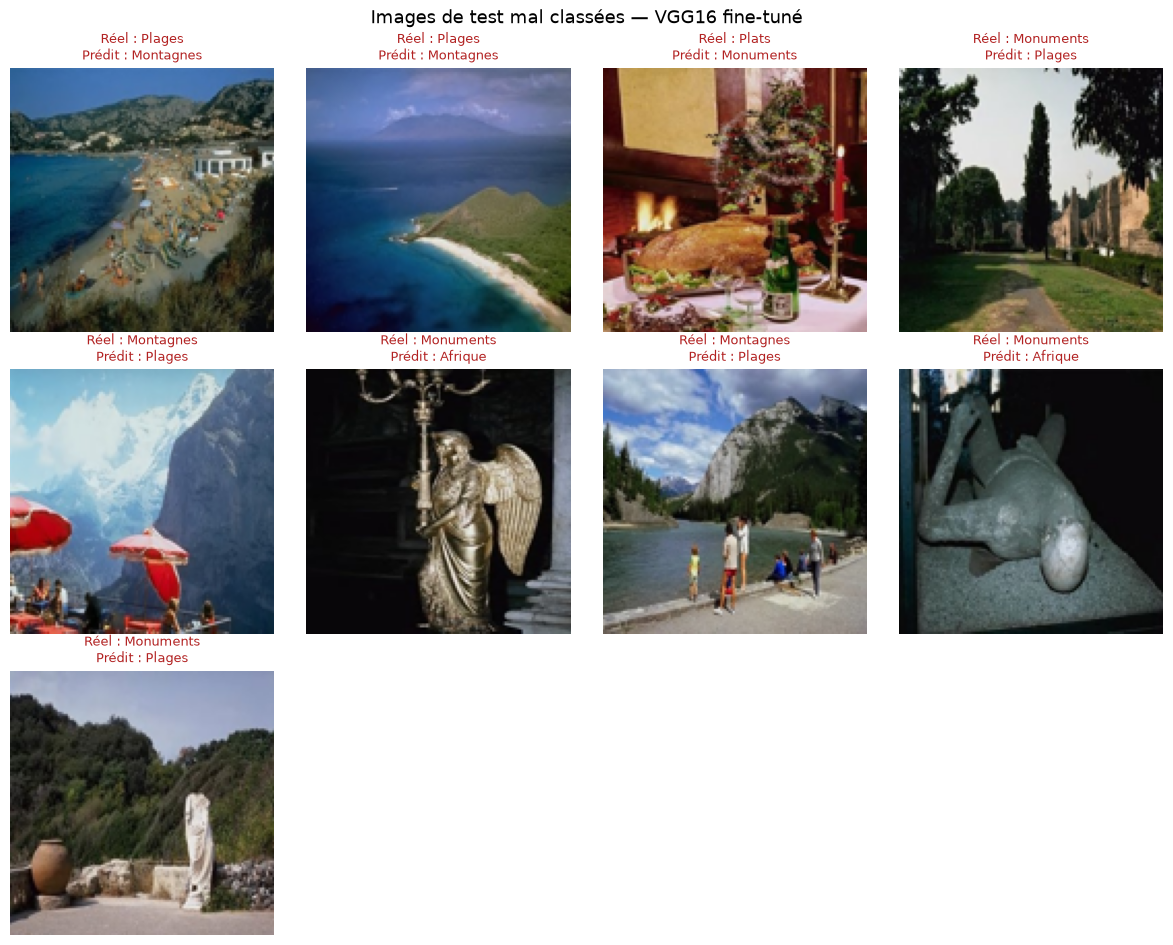

In [64]:
indices_erreurs = np.where(y_pred_vgg_ft != y_img_test)[0]
print(f"Images de test mal classées : {len(indices_erreurs)} / {len(y_img_test)}")

n_affichees = min(12, len(indices_erreurs))

if n_affichees == 0:
    print("Aucune erreur à afficher.")
else:
    n_colonnes = 4
    n_lignes = int(np.ceil(n_affichees / n_colonnes))
    plt.figure(figsize=(3 * n_colonnes, 3.2 * n_lignes))

    for k, idx in enumerate(indices_erreurs[:n_affichees]):
        plt.subplot(n_lignes, n_colonnes, k + 1)
        plt.imshow(X_img_test[idx])
        plt.title(f"Réel : {CLASSES[y_img_test[idx]]}\nPrédit : {CLASSES[y_pred_vgg_ft[idx]]}",
                  fontsize=9, color="firebrick")
        plt.axis("off")

    plt.suptitle("Images de test mal classées — VGG16 fine-tuné", fontsize=13)
    plt.tight_layout()
    plt.show()

### Robustesse aux perturbations

Nous mesurons l'accuracy du VGG16 fine-tuné lorsque les images de test sont dégradées : bruit gaussien, flou, rotation de 90° × k. Les perturbations sont appliquées sur les images normalisées entre 0 et 1, **avant** le prétraitement propre à VGG16 (`preparer_vgg`), pour que le modèle reçoive des entrées cohérentes avec celles de l'apprentissage. Le niveau 0 correspond aux images non perturbées et doit retrouver l'accuracy du test.

Robustesse — perturbation « gaussien » :
  niveau = 0.0   ->  accuracy = 0.9550
  niveau = 0.05  ->  accuracy = 0.9500
  niveau = 0.1   ->  accuracy = 0.8900
  niveau = 0.2   ->  accuracy = 0.4750
  niveau = 0.3   ->  accuracy = 0.2200
Robustesse — perturbation « flou » :
  niveau = 0     ->  accuracy = 0.9550
  niveau = 1     ->  accuracy = 0.9450
  niveau = 2     ->  accuracy = 0.9250
  niveau = 3     ->  accuracy = 0.8300
Robustesse — perturbation « rotation » :
  niveau = 0     ->  accuracy = 0.9550
  niveau = 1     ->  accuracy = 0.6550
  niveau = 2     ->  accuracy = 0.8400
  niveau = 3     ->  accuracy = 0.6900
  [sauvegardé] figures/fig_062.pdf / .png


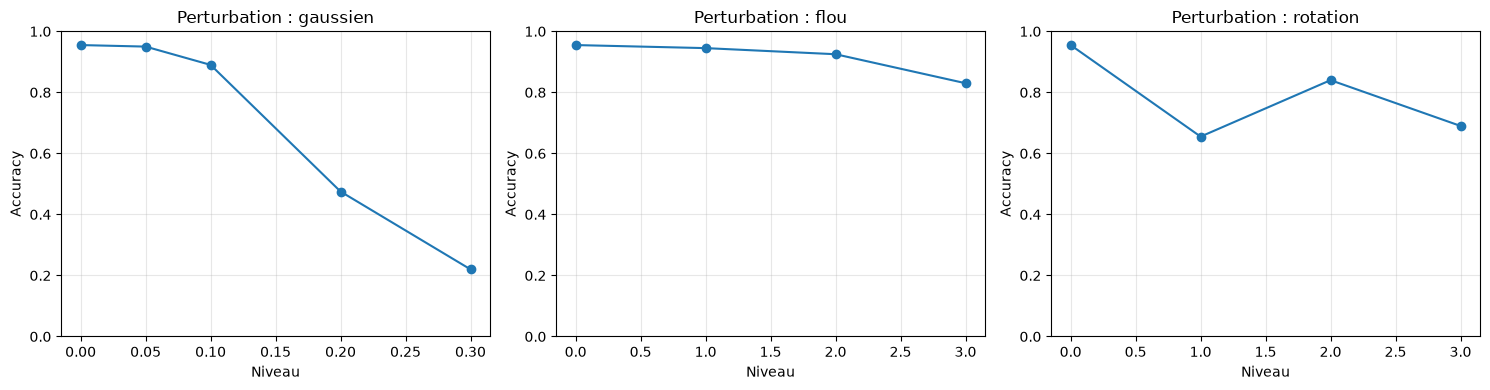

In [65]:
def perturber_images(images, type_perturbation, niveau):
    images = tf.convert_to_tensor(images, dtype=tf.float32)
    if type_perturbation == "gaussien":
        bruit = tf.random.normal(tf.shape(images), mean=0.0, stddev=niveau)
        return tf.clip_by_value(images + bruit, 0.0, 1.0).numpy()
    elif type_perturbation == "flou":
        k = int(2 * niveau + 1)
        return tf.nn.avg_pool2d(images, ksize=k, strides=1, padding="SAME").numpy()
    elif type_perturbation == "rotation":
        return tf.image.rot90(images, k=int(niveau)).numpy()
    return images.numpy()


def evaluer_perturbe(model, X, y, type_perturbation, niveau):
    X_pert = perturber_images(X, type_perturbation, niveau)
    X_prep = preparer_vgg(X_pert)          # redimensionnement 224 + prétraitement VGG16
    pred = np.argmax(model.predict(X_prep, verbose=0, batch_size=16), axis=1)
    return accuracy_score(y, pred)


tf.random.set_seed(42)

niveaux_test = {
    "gaussien": [0.0, 0.05, 0.1, 0.2, 0.3],   # écart-type du bruit
    "flou":     [0, 1, 2, 3],                  # noyau de taille 2*niveau + 1
    "rotation": [0, 1, 2, 3],                  # nombre de rotations de 90°
}

resultats_robustesse = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (type_pert, niveaux) in zip(axes, niveaux_test.items()):
    accs = []
    print(f"Robustesse — perturbation « {type_pert} » :")
    for niveau in niveaux:
        acc = evaluer_perturbe(model_vgg, X_img_test, y_img_test, type_pert, niveau)
        accs.append(acc)
        print(f"  niveau = {niveau:<5} ->  accuracy = {acc:.4f}")
    resultats_robustesse[type_pert] = accs

    ax.plot(niveaux, accs, marker="o")
    ax.set_title(f"Perturbation : {type_pert}")
    ax.set_xlabel("Niveau")
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 3. Comparaison globale de toutes les approches

,Modèle,Accuracy test,Approche,Taux d'erreur
0,EfficientNetB0,0.965,Transfert d'apprentissage,0.035
1,ResNet50,0.955,Transfert d'apprentissage,0.045
2,VGG16,0.935,Transfert d'apprentissage,0.065
3,MLP — JCD,0.855,MLP — descripteurs,0.145
4,MLP — CEDD,0.830,MLP — descripteurs,0.170
5,KppV — Concaténation,0.815,KppV — descripteurs,0.185
6,MLP — Concaténation,0.815,MLP — descripteurs,0.185
7,CNN — entraîné depuis zéro,0.785,CNN,0.215
8,KppV — CEDD,0.775,KppV — descripteurs,0.225
9,MLP — FuzzyColorHistogram,0.770,MLP — descripteurs,0.230


  [sauvegardé] figures/fig_063.pdf / .png


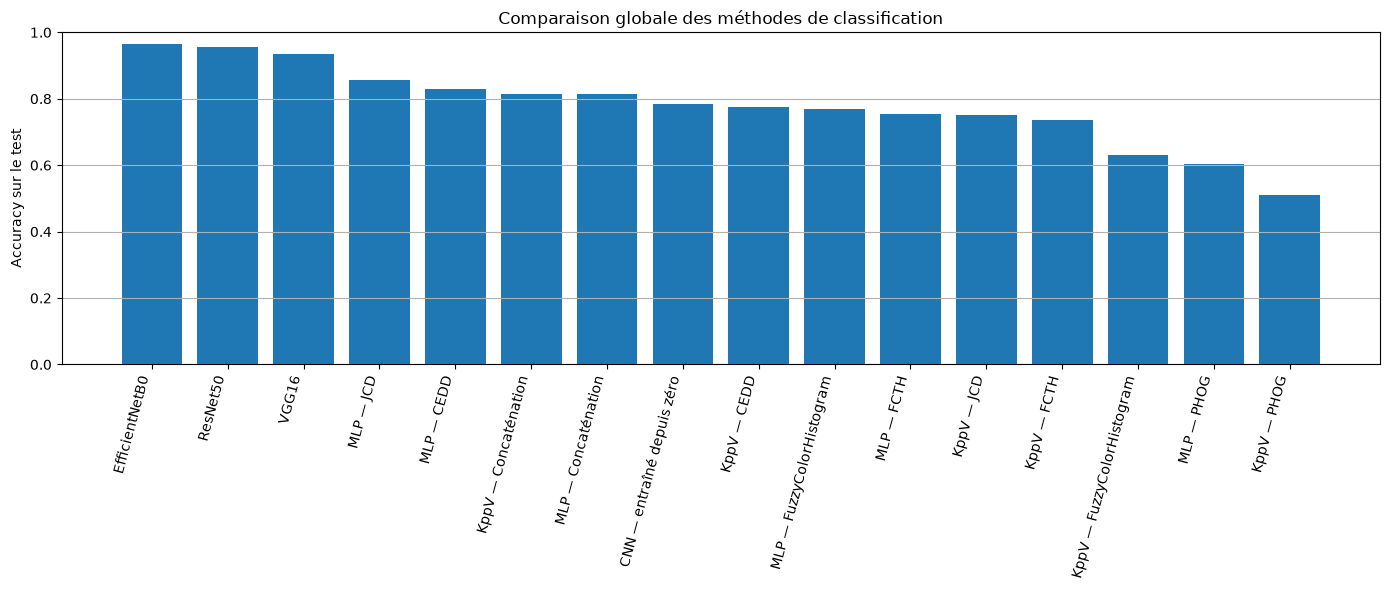

Meilleure approche : EfficientNetB0
Accuracy test : 0.9650
Taux d'erreur : 0.0350


In [66]:

# Résultats des MLP avec les différents descripteurs
global_mlp = pd.DataFrame({
    "Modèle": ["MLP — " + str(n) for n in tableau_mlp["Descripteur"]],
    "Accuracy test": tableau_mlp["Accuracy test"].to_numpy(),
    "Approche": "MLP — descripteurs"
})

# Résultats des KppV
global_knn = pd.DataFrame({
    "Modèle": ["KppV — " + str(n) for n in tableau_knn["Descripteur"]],
    "Accuracy test": tableau_knn["Accuracy test"].to_numpy(),
    "Approche": "KppV — descripteurs"
})

# CNN entraîné depuis zéro
global_cnn = pd.DataFrame([{
    "Modèle": "CNN — entraîné depuis zéro",
    "Accuracy test": float(accuracy_cnn),
    "Approche": "CNN"
}])

# VGG16 déjà évalué, sans nouvel entraînement
global_vgg = pd.DataFrame([{
    "Modèle": "VGG16",
    "Accuracy test": float(accuracy_vgg),
    "Approche": "Transfert d'apprentissage"
}])

# Nouveaux modèles
global_nouveaux = pd.DataFrame([
    {
        "Modèle": r["Modèle"],
        "Accuracy test": r["Accuracy test"],
        "Approche": "Transfert d'apprentissage"
    }
    for r in resultats_nouveaux
])

comparaison_globale = pd.concat(
    [global_mlp, global_knn, global_cnn, global_vgg, global_nouveaux],
    ignore_index=True
)

comparaison_globale["Taux d'erreur"] = (
    1 - comparaison_globale["Accuracy test"]
)

comparaison_globale = comparaison_globale.sort_values(
    "Accuracy test", ascending=False
).reset_index(drop=True)

display(comparaison_globale)

plt.figure(figsize=(14, 6))
plt.bar(
    comparaison_globale["Modèle"],
    comparaison_globale["Accuracy test"]
)
plt.ylabel("Accuracy sur le test")
plt.ylim(0, 1)
plt.title("Comparaison globale des méthodes de classification")
plt.xticks(rotation=75, ha="right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

meilleur_global = comparaison_globale.iloc[0]
print("Meilleure approche :", meilleur_global["Modèle"])
print(f"Accuracy test : {meilleur_global['Accuracy test']:.4f}")
taux_erreur = meilleur_reseau["Taux d'erreur"]
print(f"Taux d'erreur : {taux_erreur:.4f}")

### Bilan complet incluant les approfondissements

Nous ajoutons au tableau de comparaison globale les résultats des expériences complémentaires (fine-tuning de VGG16, CNN avec augmentation, meilleure configuration de l'ablation). Les valeurs exactes dépendent de l'initialisation aléatoire et des données de validation : il convient de se référer aux tableaux produits par l'exécution.

,Modèle,Accuracy test,Approche,Taux d'erreur
0,EfficientNetB0,0.965,Transfert d'apprentissage,0.035
1,ResNet50,0.955,Transfert d'apprentissage,0.045
2,VGG16 — fine-tuning,0.955,Approfondissement,0.045
3,VGG16,0.935,Transfert d'apprentissage,0.065
4,MLP — JCD,0.855,MLP — descripteurs,0.145
5,MLP — CEDD,0.830,MLP — descripteurs,0.170
6,KppV — Concaténation,0.815,KppV — descripteurs,0.185
7,MLP — Concaténation,0.815,MLP — descripteurs,0.185
8,CNN — entraîné depuis zéro,0.785,CNN,0.215
9,KppV — CEDD,0.775,KppV — descripteurs,0.225


  [sauvegardé] figures/fig_064.pdf / .png


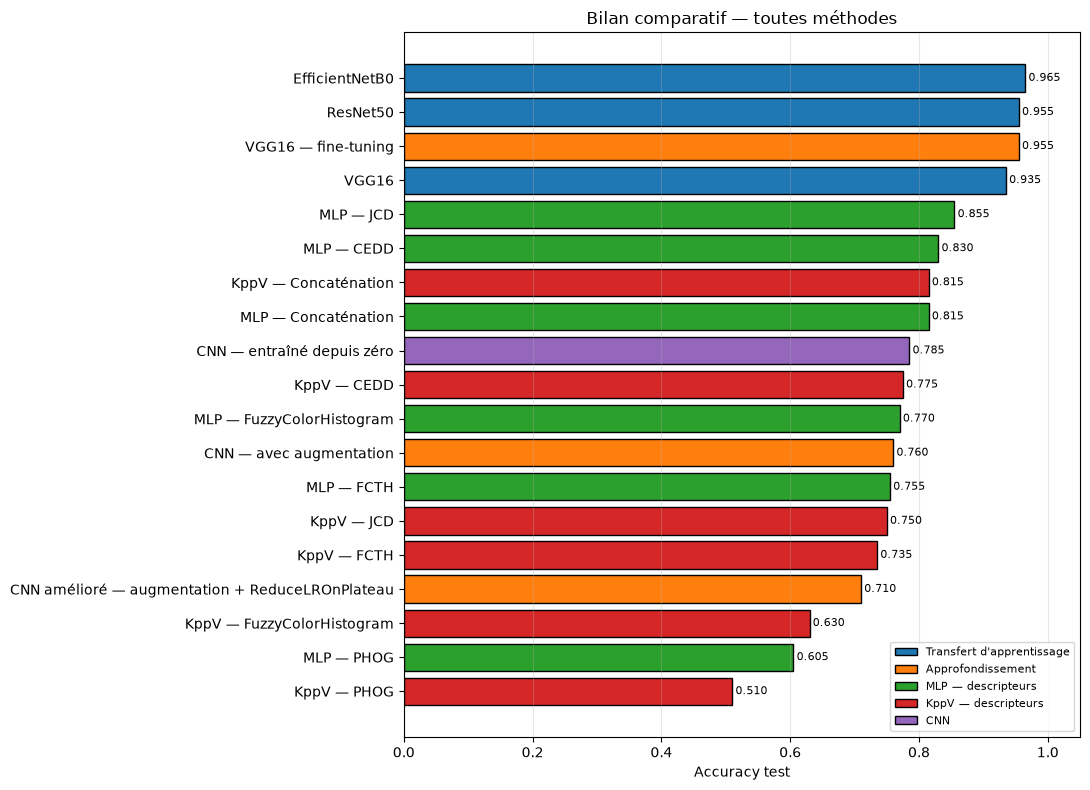

In [67]:
supplements = pd.DataFrame([
    {"Modèle": nom_exp, "Accuracy test": float(v), "Approche": "Approfondissement"}
    for nom_exp, v in resultats_supplementaires.items()
])

comparaison_complete = pd.concat(
    [comparaison_globale.drop(columns="Taux d'erreur"), supplements],
    ignore_index=True
)
comparaison_complete["Taux d'erreur"] = 1 - comparaison_complete["Accuracy test"]
comparaison_complete = comparaison_complete.sort_values(
    "Accuracy test", ascending=False
).reset_index(drop=True)

display(comparaison_complete)

approches = comparaison_complete["Approche"].unique()
palette = dict(zip(approches, plt.cm.tab10.colors))
couleurs = [palette[a] for a in comparaison_complete["Approche"]]

plt.figure(figsize=(11, 8))
plt.barh(comparaison_complete["Modèle"], comparaison_complete["Accuracy test"],
         color=couleurs, edgecolor="k")
for i, v in enumerate(comparaison_complete["Accuracy test"]):
    plt.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=8)
plt.gca().invert_yaxis()
plt.xlabel("Accuracy test")
plt.xlim(0, 1.05)
plt.title("Bilan comparatif — toutes méthodes")
handles = [plt.Rectangle((0, 0), 1, 1, color=palette[a], ec="k") for a in approches]
plt.legend(handles, approches, loc="lower right", fontsize=8)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## Conclusion générale

Ce TP nous a permis de comparer plusieurs approches de classification d’images sur la base Wang. Les résultats montrent que le **transfert d’apprentissage est l’approche la plus performante** : ResNet50 et EfficientNetB0 atteignent une accuracy de **96,5 %**, suivis de VGG16 avec **95 %**. Le MLP utilisant la concaténation des descripteurs obtient **82,5 %**, tandis que le CNN entraîné depuis zéro atteint **72 %**.

Ces résultats soulignent l’intérêt des caractéristiques pré-entraînées et de la combinaison de plusieurs descripteurs pour améliorer la classification. En conclusion, **ResNet50 et EfficientNetB0 offrent les meilleures performances sur ce jeu de données**, avec seulement 3,5 % d’erreurs sur l’ensemble de test.